# UNSW-NB15 — harmonized M0/M4 full replication

The experimental stages and operational comparisons are retained from the current BCCC M0/M4 notebook. Only UNSW-specific ingestion, benign downsampling, schema/host/time preprocessing, label taxonomy, LOAFO family names, and corresponding M4 feature inputs differ.


In [1]:
# BLOCK 1: CLEAN-RUN INITIALIZATION
import gc
import sys

print("=" * 115)
print("[Initialization] Preparing a clean runtime state.")
print("=" * 115)

pipeline_variables = [
    "df_raw", "df_clean", "df_drift_pool",
    "train_df", "validation_df", "host_test_df", "time_test_df", "hard_test_df",
    "development_pool_df", "earlystop_dev_df", "calibration_dev_df",
    "similarity_dev_df", "policy_dev_df",
    "X_train", "y_train", "X_early", "y_early", "X_calib", "y_calib",
    "PRIMARY_PREPROCESSOR", "lgb_model", "calibrators",
    "train_signatures", "train_variances",
    "FINAL_TAU_P", "FINAL_TAU_S", "FINAL_BENIGN_PROB_TAU",
    "FINAL_BENIGN_SIM_TAU", "FINAL_HIGH_CONF_BENIGN_PROB_TAU",
    "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR",
    "SELECTIVE_BENIGN_DIRECT_PROB_TAU", "SELECTIVE_BENIGN_DIRECT_MARGIN_TAU",
    "SELECTIVE_ATTACK_DIRECT_PROB_TAU", "SELECTIVE_ATTACK_DIRECT_MARGIN_TAU",
    "comprehensive_metrics_log", "multi_seed_results_df",
]

purged_count = 0
for var in pipeline_variables:
    if var in globals():
        del globals()[var]
        purged_count += 1

comprehensive_metrics_log = []
gc.collect()

print(f"[Initialization] Cleared {purged_count} prior pipeline variables.")
print("[Initialization] Legacy partition_caches/best_seen_ratio state is not used.")
print("=" * 115)
sys.stdout.flush()


[Initialization] Preparing a clean runtime state.
[Initialization] Cleared 0 prior pipeline variables.
[Initialization] Legacy partition_caches/best_seen_ratio state is not used.


In [2]:
# BLOCK 1B: ENVIRONMENT, DEPENDENCIES, AND GLOBAL CONFIGURATION
from google.colab import drive
drive.mount("/content/drive")

!pip install shap lightgbm scikit-learn psutil pandas numpy scipy lime --quiet

import os
import re
import gc
import time
import json
import glob
import psutil
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    brier_score_loss,
    roc_auc_score,
    silhouette_score,
)
from sklearn.calibration import IsotonicRegression
from sklearn.model_selection import train_test_split

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

CONFIG = {
    "base_path": "/content/drive/MyDrive",
    "unsw_search_root": "/content/drive/MyDrive/UNSW-NB15/",
    "results_dir": "/content/drive/MyDrive/UNSW_NB15_IDS_XAI_BCCC_Method_Replication2/",
    "min_class_count": 1,

    "development_split_seed": 42,
    "multi_seed_values": [42, 123, 456, 789, 2026],
    "final_reporting_seed": 42,

    "attribution_batch_size": 8192,
    "prediction_batch_size": 65536,
    "signature_sample_sizes": [20, 40, 80, 100, 150, 160],
    "signature_stability_seeds": [42, 123, 456, 789, 2026],
    "signature_stability_threshold": 0.99,
    "multimodal_max_rows_per_class": 320,
    "multimodal_silhouette_flag": 0.35,
    "lime_diagnostic_rows": 120,

    "loafo_families": [
        "Exploits",
        "Fuzzers",
        "DoS",
        "Reconnaissance",
    ],

    "adversarial_epsilons": [0.00, 0.01, 0.025, 0.05, 0.10],
    "adversarial_random_candidates": 4,
    "adversarial_eval_max_rows": 20000,

    "policy_selection_priority": "containment_first",
    "anmr_safety_floor": 0.9999,
    "fbr_safety_ceiling": 0.005,
}

os.makedirs(CONFIG["results_dir"], exist_ok=True)
print("[Initialization] UNSW-NB15 replication dependencies and BCCC-method configuration loaded.")


Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[Initialization] UNSW-NB15 replication dependencies and BCCC-method configuration loaded.


In [3]:
# BLOCK 2: GLOBAL LABEL SCHEMA, THREE-TIER ROUTING POLICY,
#          AND LOW-LATENCY EXPLANATION HELPERS

import numpy as np
import shap


# =============================================================================
# 1. GLOBAL AND CANONICAL LABEL SCHEMAS
# =============================================================================

GLOBAL_CLASS_INDEX = {
    "Benign": 0,
    "Analysis": 1,
    "Backdoor": 2,
    "DoS": 3,
    "Exploits": 4,
    "Fuzzers": 5,
    "Generic": 6,
    "Reconnaissance": 7,
    "Shellcode": 8,
    "Worms": 9,
}
REVERSE_CLASS_INDEX = {index: name for name, index in GLOBAL_CLASS_INDEX.items()}

CANONICAL_LABEL_MAP = {
    "Normal": "Benign", "NORMAL": "Benign", "Benign": "Benign", "BENIGN": "Benign",
    "Analysis": "Analysis",
    "Backdoor": "Backdoor", "Backdoors": "Backdoor",
    "DoS": "DoS",
    "Exploits": "Exploits",
    "Fuzzers": "Fuzzers",
    "Generic": "Generic",
    "Reconnaissance": "Reconnaissance",
    "Shellcode": "Shellcode",
    "Worms": "Worms",
}

ACTIVE_CLASS_NAMES = list(GLOBAL_CLASS_INDEX.keys())
ACTIVE_CLASS_INDEX = dict(GLOBAL_CLASS_INDEX)
ACTIVE_REVERSE_CLASS_INDEX = dict(REVERSE_CLASS_INDEX)
CLASS_COUNT = len(ACTIVE_CLASS_NAMES)
BENIGN_IDX = ACTIVE_CLASS_INDEX["Benign"]
ZERO_DAY_ENCODED_LABEL = -1

def encode_active_labels(label_series, zero_day_value=None):
    mapped = label_series.map(ACTIVE_CLASS_INDEX)
    if mapped.isna().any():
        unknown = sorted(label_series[mapped.isna()].astype(str).unique().tolist())
        if zero_day_value is not None:
            mapped = mapped.fillna(zero_day_value)
        else:
            raise ValueError(f"Unrecognized labels in primary UNSW-NB15 class space: {unknown}")
    return mapped.astype(np.int32).to_numpy()

def resolve_active_class_name(index_value):
    try:
        index_value = int(index_value)
    except (TypeError, ValueError):
        return f"Unknown_Class_{index_value}"
    return ACTIVE_REVERSE_CLASS_INDEX.get(index_value, f"Unknown_Class_{index_value}")

BENIGN_PROB_TAU = None
BENIGN_SIM_TAU = None

def _resolve_threshold(explicit_value, global_name, fallback_value):
    if explicit_value is not None:
        return float(explicit_value)
    global_value = globals().get(global_name)
    return float(fallback_value if global_value is None else global_value)


# =============================================================================
# 3. FINAL THREE-TIER POLICY
# =============================================================================

def route_policy_batch(
    pred_names,
    attack_confidence,
    similarities,
    tau_p,
    tau_s,
    benign_prob_tau=None,
    benign_sim_tau=None,
    override_prob_tau=None,
    override_sim_floor=None,
):
    """Apply the frozen three-tier routing policy without access to ground truth."""

    pred_names = np.asarray(pred_names, dtype=object)
    attack_confidence = np.asarray(attack_confidence, dtype=float)
    similarities = np.asarray(similarities, dtype=float)

    n_samples = len(pred_names)
    if not (len(attack_confidence) == len(similarities) == n_samples):
        raise ValueError("All routing arrays must have equal length.")
    if not np.all(np.isfinite(attack_confidence)):
        raise ValueError("attack_confidence contains non-finite values.")
    if not np.all(np.isfinite(similarities)):
        raise ValueError("similarities contains non-finite values.")

    tau_p = float(tau_p)
    tau_s = float(tau_s)
    tau_b = _resolve_threshold(benign_prob_tau, "FINAL_BENIGN_PROB_TAU", tau_p)
    tau_bs = _resolve_threshold(benign_sim_tau, "FINAL_BENIGN_SIM_TAU", tau_s)
    tau_override_prob = _resolve_threshold(
        override_prob_tau, "FINAL_HIGH_CONF_BENIGN_PROB_TAU", 0.9995
    )
    tau_override_sim = _resolve_threshold(
        override_sim_floor, "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR", 0.02
    )

    effective_benign_similarity = max(tau_s, tau_bs)
    malicious_similarity_threshold = 0.5 * tau_s

    predicted_benign = pred_names == "Benign"
    benign_probability = 1.0 - attack_confidence

    ordinary_benign_allow = (
        predicted_benign
        & (benign_probability >= tau_b)
        & (similarities >= effective_benign_similarity)
    )
    high_confidence_benign_override = (
        predicted_benign
        & (benign_probability >= tau_override_prob)
        & (similarities >= tau_override_sim)
    )

    tier_1_allow = ordinary_benign_allow | high_confidence_benign_override
    tier_2_block = (
        (~predicted_benign)
        & (attack_confidence >= tau_p)
        & (similarities >= malicious_similarity_threshold)
    )
    tier_3_escalate = ~(tier_1_allow | tier_2_block)

    actions = np.full(n_samples, "ESCALATE", dtype=object)
    tiers = np.full(n_samples, "Tier 3", dtype=object)
    actions[tier_1_allow] = "ALLOW"
    tiers[tier_1_allow] = "Tier 1"
    actions[tier_2_block] = "BLOCK"
    tiers[tier_2_block] = "Tier 2"

    return {
        "actions": actions,
        "tiers": tiers,
        "tier_1_allow": tier_1_allow,
        "tier_2_block": tier_2_block,
        "tier_3_escalate": tier_3_escalate,
        "human_escalated": tier_3_escalate,
        "ordinary_benign_allow": ordinary_benign_allow,
        "high_confidence_benign_override": high_confidence_benign_override,
        "benign_probability": benign_probability,
        "effective_benign_similarity_threshold": effective_benign_similarity,
        "malicious_similarity_threshold": malicious_similarity_threshold,
        "override_probability_threshold": tau_override_prob,
        "override_similarity_floor": tau_override_sim,
    }


def shared_policy_route(
    pred_name,
    true_name,
    attack_confidence,
    similarity,
    tau_p,
    tau_s,
    benign_prob_tau=None,
    benign_sim_tau=None,
):
    """Single-flow diagnostic wrapper; ground truth is used only after routing."""
    routed = route_policy_batch(
        np.asarray([pred_name], dtype=object),
        np.asarray([attack_confidence], dtype=float),
        np.asarray([similarity], dtype=float),
        tau_p,
        tau_s,
        benign_prob_tau,
        benign_sim_tau,
    )

    action = routed["actions"][0]
    true_benign = str(true_name) == "Benign"

    return {
        "action": action,
        "tier": routed["tiers"][0],
        "missed_attack": bool((not true_benign) and action == "ALLOW"),
        "false_block": bool(true_benign and action == "BLOCK"),
        "false_alarm": bool(true_benign and action == "ESCALATE"),
        "escalated": bool(action == "ESCALATE"),
        "benign_probability": float(routed["benign_probability"][0]),
    }


# =============================================================================
# 4. LOW-LATENCY ATTRIBUTION AND SIGNATURE SIMILARITY
# =============================================================================

def fast_predicted_class_attributions(
    model,
    X_matrix,
    predicted_indices,
    batch_size=8192,
):
    """Extract predicted-class LightGBM contributions in vectorized batches."""
    X_matrix = np.asarray(X_matrix, dtype=np.float32)
    predicted_indices = np.asarray(predicted_indices, dtype=np.int32)

    if X_matrix.ndim != 2 or predicted_indices.ndim != 1:
        raise ValueError("X_matrix must be 2-D and predicted_indices must be 1-D.")
    if len(X_matrix) != len(predicted_indices):
        raise ValueError("X_matrix and predicted_indices must align.")
    if np.any((predicted_indices < 0) | (predicted_indices >= CLASS_COUNT)):
        raise ValueError("predicted_indices contains an out-of-range class index.")

    n_rows, n_features = X_matrix.shape
    output = np.zeros((n_rows, n_features), dtype=np.float32)
    batch_size = max(1, int(batch_size))

    for start in range(0, n_rows, batch_size):
        end = min(start + batch_size, n_rows)
        X_batch = X_matrix[start:end]
        p_batch = predicted_indices[start:end]

        try:
            contrib = np.asarray(
                model.predict(X_batch, pred_contrib=True)
            )
            if (
                contrib.ndim == 2
                and contrib.shape[1] == CLASS_COUNT * (n_features + 1)
            ):
                contrib = contrib.reshape(
                    len(X_batch), CLASS_COUNT, n_features + 1
                )
                batch_output = contrib[
                    np.arange(len(X_batch)), p_batch, :-1
                ]
            elif contrib.ndim == 3 and contrib.shape[1] == CLASS_COUNT:
                batch_output = contrib[
                    np.arange(len(X_batch)), p_batch, :-1
                ]
            elif contrib.ndim == 3 and contrib.shape[2] == CLASS_COUNT:
                batch_output = contrib[
                    np.arange(len(X_batch)), :-1, p_batch
                ]
            else:
                raise ValueError(
                    f"Unexpected native contribution shape: {contrib.shape}"
                )
        except Exception as native_error:
            try:
                raw = shap.TreeExplainer(model).shap_values(X_batch)
                if isinstance(raw, list):
                    batch_output = np.vstack(
                        [raw[p_batch[row]][row] for row in range(len(X_batch))]
                    )
                else:
                    raw = np.asarray(raw)
                    if raw.ndim == 3 and raw.shape[1] == n_features:
                        batch_output = raw[
                            np.arange(len(X_batch)), :, p_batch
                        ]
                    elif raw.ndim == 3 and raw.shape[2] == n_features:
                        batch_output = raw[
                            np.arange(len(X_batch)), p_batch, :
                        ]
                    elif raw.shape == (len(X_batch), n_features):
                        batch_output = raw
                    else:
                        raise ValueError(
                            f"Unexpected SHAP fallback shape: {raw.shape}"
                        )
            except Exception as shap_error:
                raise RuntimeError(
                    "Native LightGBM contributions and SHAP fallback both failed."
                ) from shap_error

        output[start:end] = np.asarray(batch_output, dtype=np.float32)

    return output


def compute_predicted_signature_similarity(
    model,
    reference_signatures,
    X_matrix,
    predicted_indices,
    predicted_names,
    batch_size=8192,
):
    """Compute cosine similarity to each flow's predicted-class signature."""
    X_matrix = np.asarray(X_matrix, dtype=np.float32)
    predicted_indices = np.asarray(predicted_indices, dtype=np.int32)
    predicted_names = np.asarray(predicted_names, dtype=object)

    if not (
        len(X_matrix) == len(predicted_indices) == len(predicted_names)
    ):
        raise ValueError("Attribution inputs must contain the same number of rows.")

    attributions = fast_predicted_class_attributions(
        model, X_matrix, predicted_indices, batch_size=batch_size
    )
    norms = np.linalg.norm(attributions, axis=1, keepdims=True)
    normalized = np.divide(
        attributions,
        norms,
        out=np.zeros_like(attributions, dtype=np.float32),
        where=norms > 1e-12,
    )

    similarities = np.zeros(len(X_matrix), dtype=np.float32)
    for class_name in np.unique(predicted_names):
        mask = predicted_names == class_name
        signature = reference_signatures.get(class_name)
        if signature is None:
            continue
        signature = np.asarray(signature, dtype=np.float32)
        if signature.shape != (X_matrix.shape[1],):
            raise ValueError(
                f"Signature for {class_name} has shape {signature.shape}; "
                f"expected {(X_matrix.shape[1],)}."
            )
        signature_norm = np.linalg.norm(signature)
        if signature_norm > 1e-12:
            similarities[mask] = normalized[mask] @ (
                signature / signature_norm
            )

    return similarities, normalized


print(
    f"[Primary Label Space] num_class={CLASS_COUNT}; "
    f"all classes active={ACTIVE_CLASS_NAMES}"
)
print(
    "[Initialization] Three-tier routing and batched attribution helpers locked."
)


[Primary Label Space] num_class=10; all classes active=['Benign', 'Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
[Initialization] Three-tier routing and batched attribution helpers locked.


In [4]:
# ======================================================================================
# BLOCK 3 — UNSW-NB15 INGESTION AND DATASET-SCHEMA ALIGNMENT
# Dataset-specific code only. Downstream methodology is the BCCC pipeline.
# ======================================================================================
import os, glob, re
import pandas as pd
import numpy as np

print("=" * 115)
print("[Block 3] Loading UNSW-NB15 and aligning it to the common BCCC pipeline interface")
print("=" * 115)

def clean_colname(c):
    c = str(c).strip().replace("\ufeff", "")
    c = re.sub(r"[^0-9a-zA-Z]+", "_", c)
    c = re.sub(r"_+", "_", c).strip("_").lower()
    return c

def _find_one(root, basename):
    hits = sorted(glob.glob(os.path.join(root, "**", basename), recursive=True))
    if not hits:
        raise FileNotFoundError(f"Could not find {basename} under {root}")
    return hits[0]

def load_unsw_nb15_workspace():
    root = CONFIG["unsw_search_root"]
    feature_file = _find_one(root, "NUSW-NB15_features.csv")
    matrix_files = [_find_one(root, f"UNSW-NB15_{i}.csv") for i in range(1, 5)]

    meta = pd.read_csv(feature_file, encoding="cp1252")
    name_col = next((c for c in meta.columns if str(c).strip().lower() == "name"), None)
    if name_col is None:
        raise ValueError(f"Feature-name column not found in {feature_file}")

    raw_names = meta[name_col].astype(str).str.strip().tolist()
    if len(raw_names) != 49:
        raise ValueError(f"Expected 49 UNSW-NB15 feature names, found {len(raw_names)}")
    feature_names = [clean_colname(x) for x in raw_names]

    parts = []
    for f in matrix_files:
        part = pd.read_csv(f, header=None, names=feature_names, low_memory=False)
        if part.shape[1] != 49:
            raise ValueError(f"{os.path.basename(f)} has {part.shape[1]} columns; expected 49")
        part["_UNSW_SOURCE_MATRIX"] = os.path.basename(f)
        parts.append(part)
        print(f"[UNSW ingestion] {os.path.basename(f)}: {part.shape}")

    df = pd.concat(parts, ignore_index=True, sort=False)
    print(f"[UNSW ingestion] Combined raw shape: {df.shape}")

    if "label" not in df.columns or "attack_cat" not in df.columns:
        raise ValueError("UNSW-NB15 requires attack_cat and binary Label fields.")
    df = df.rename(columns={"label": "binary_label"})

    df["attack_cat"] = df["attack_cat"].fillna("Normal").astype(str).str.strip()
    df.loc[df["attack_cat"].eq(""), "attack_cat"] = "Normal"
    df["attack_cat"] = df["attack_cat"].replace({"Backdoors": "Backdoor"})
    df["label"] = df["attack_cat"].map(CANONICAL_LABEL_MAP)
    if df["label"].isna().any():
        bad = sorted(df.loc[df["label"].isna(), "attack_cat"].unique().tolist())
        raise ValueError(f"Unrecognized UNSW attack categories: {bad}")

    binary = pd.to_numeric(df["binary_label"], errors="coerce")
    if binary.isna().any():
        raise ValueError("Malformed UNSW binary Label values detected.")
    inconsistent = ((df["label"].eq("Benign") & binary.ne(0)) |
                    (~df["label"].eq("Benign") & binary.ne(1)))
    if inconsistent.any():
        raise ValueError(f"Binary/multiclass label inconsistency in {int(inconsistent.sum())} rows.")

    # Exact duplicate observations are removed before any partitioning.
    before = len(df)
    duplicate_key = [c for c in df.columns if c not in {"label", "_UNSW_SOURCE_MATRIX"}]
    df = df.drop_duplicates(subset=duplicate_key).reset_index(drop=True)
    print(f"[UNSW preprocessing] Exact duplicates removed: {before-len(df):,}")

    # Dataset-native temporal and host metadata are retained only for partitioning/M4 history.
    for c in ["stime", "ltime"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    if df["stime"].isna().any():
        raise ValueError("Invalid UNSW stime values detected.")

    df["srcip"] = df["srcip"].astype("string").str.strip()
    bad_host = df["srcip"].isna() | df["srcip"].eq("") | df["srcip"].str.lower().eq("nan")
    if bad_host.any():
        raise ValueError(f"Invalid UNSW source hosts: {int(bad_host.sum())}")

    # Common BCCC pipeline metadata interface.
    df["src_ip"] = df["srcip"].astype(str)
    df["HostID"] = df["src_ip"]
    df["timestamp"] = pd.to_datetime(df["stime"], unit="s", errors="coerce", utc=True)
    if df["timestamp"].isna().any():
        raise ValueError("UNSW stime could not be converted to timestamp metadata.")
    df["Date"] = df["timestamp"].dt.date

    # The common BCCC host optimizer expects single-label scenarios. For UNSW, the
    # dataset-native attack category is the scenario key. This is metadata only.
    df["source_file"] = df["label"].astype(str)
    df["_MASTER_ROW_ID"] = np.arange(len(df), dtype=np.int64)

    for c in ["is_ftp_login", "ct_flw_http_mthd", "ct_ftp_cmd"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0.0)

    categorical_metadata = {"proto", "state", "service"}
    forbidden = {
        "srcip", "dstip", "src_ip", "HostID", "stime", "ltime", "timestamp", "Date",
        "attack_cat", "binary_label", "label", "sport", "dsport", "source_file",
        "_MASTER_ROW_ID", "_UNSW_SOURCE_MATRIX", "host_holdout", "split", "environment",
        "_dev_row_id", "hostid_str"
    } | categorical_metadata

    candidate_features = [c for c in df.columns if c not in forbidden]
    numeric_features = []
    for c in candidate_features:
        converted = pd.to_numeric(df[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
        bad = int(converted.isna().sum())
        if bad:
            print(f"[UNSW schema] {c}: fixed-zero representation for {bad:,} missing/nonnumeric values.")
        df[c] = converted.fillna(0.0)
        numeric_features.append(c)

    if set(numeric_features) & forbidden:
        raise RuntimeError("Leakage/identifier field entered expected_features.")
    if df["label"].nunique() != CLASS_COUNT:
        raise RuntimeError(f"Expected {CLASS_COUNT} UNSW classes, found {df['label'].nunique()}.")

    print("\n[UNSW schema alignment] class distribution")
    print(df["label"].value_counts().to_string())
    print(f"Model features: {len(numeric_features)}")
    print(f"Full source hosts: {df['HostID'].nunique():,}")
    print("PASS: UNSW-NB15 aligned to BCCC downstream dataframe/metadata interface.")
    return df.reset_index(drop=True), list(numeric_features)

df_raw, expected_features = load_unsw_nb15_workspace()

# IMPORTANT: df_clean / df_drift_pool are intentionally created only AFTER
# the UNSW-specific benign downsampling block below. This preserves the
# original UNSW 20% benign-retention preprocessing while leaving the
# downstream BCCC methodology unchanged.


[Block 3] Loading UNSW-NB15 and aligning it to the common BCCC pipeline interface
[UNSW ingestion] UNSW-NB15_1.csv: (700001, 50)
[UNSW ingestion] UNSW-NB15_2.csv: (700001, 50)
[UNSW ingestion] UNSW-NB15_3.csv: (700001, 50)
[UNSW ingestion] UNSW-NB15_4.csv: (440044, 50)
[UNSW ingestion] Combined raw shape: (2540047, 50)
[UNSW preprocessing] Exact duplicates removed: 480,632

[UNSW schema alignment] class distribution
label
Benign            1959772
Exploits            27599
Generic             25378
Fuzzers             21795
Reconnaissance      13357
DoS                  5665
Analysis             2184
Backdoor             1983
Shellcode            1511
Worms                 171
Model features: 38
Full source hosts: 43
PASS: UNSW-NB15 aligned to BCCC downstream dataframe/metadata interface.


In [15]:
# ============================================================
# UNSW-NB15 — SINGLE-PACKET IAT CONSISTENCY CORRECTION
# ============================================================

import numpy as np
import pandas as pd

correction_log = []

for pkt_col, iat_col in [
    ("spkts", "sintpkt"),
    ("dpkts", "dintpkt")
]:
    pkt = pd.to_numeric(df_raw[pkt_col], errors="raise")
    iat = pd.to_numeric(df_raw[iat_col], errors="raise")

    mask = (pkt <= 1) & (pkt >= 0) & (iat > 0)

    correction_log.append({
        "Feature": iat_col,
        "Corrected_Rows": int(mask.sum()),
        "Previous_Max": float(iat.loc[mask].max()) if mask.any() else 0.0
    })

    df_raw.loc[mask, iat_col] = 0.0

print("UNSW-NB15 SINGLE-PACKET IAT CORRECTION")
display(pd.DataFrame(correction_log))

# Verify correction
for pkt_col, iat_col in [
    ("spkts", "sintpkt"),
    ("dpkts", "dintpkt")
]:
    remaining = (
        (df_raw[pkt_col] <= 1) &
        (df_raw[pkt_col] >= 0) &
        (df_raw[iat_col] > 0)
    ).sum()

    assert remaining == 0, (
        f"{iat_col}: {remaining} inconsistent rows remain"
    )

print("PASS: No positive IAT values remain for flows with <=1 packet.")

UNSW-NB15 SINGLE-PACKET IAT CORRECTION


,Feature,Corrected_Rows,Previous_Max
0,sintpkt,2443,84371.496
1,dintpkt,9,35001.320


PASS: No positive IAT values remain for flows with <=1 packet.


In [16]:
# =============================================================================
# BLOCK 3A: BENIGN DOWNSAMPLING — RETAIN 20% WITH STRUCTURE PRESERVATION
# =============================================================================
# IMPORTANT:
# Block 3 produces df_raw.
# Therefore benign downsampling is applied to df_raw BEFORE Block 4 creates
# the leakage-free df_clean dataset.
#
# All attack observations are retained.
# Benign observations are sampled within source-host × temporal strata.
# =============================================================================

BENIGN_KEEP_FRACTION = 0.20
BENIGN_SAMPLING_SEED = 42

print("=" * 115)
print("[UNSW Benign Downsampling] Retaining 20% of benign traffic...")
print("=" * 115)

# -------------------------------------------------------------------------
# 1. Safety checks
# -------------------------------------------------------------------------

assert "df_raw" in globals(), "df_raw does not exist. Run Block 3 first."

assert "label" in df_raw.columns
assert "srcip" in df_raw.columns
assert "stime" in df_raw.columns

rows_before = len(df_raw)

benign_before = int(
    df_raw["label"].eq("Benign").sum()
)

attack_before = int(
    df_raw["label"].ne("Benign").sum()
)

print(f"Rows before sampling : {rows_before:,}")
print(f"Benign before        : {benign_before:,}")
print(f"Attack before        : {attack_before:,}")


# -------------------------------------------------------------------------
# 2. Separate benign and attack traffic
# -------------------------------------------------------------------------

benign_pool = (
    df_raw.loc[
        df_raw["label"].eq("Benign")
    ]
    .copy()
)

attack_pool = (
    df_raw.loc[
        df_raw["label"].ne("Benign")
    ]
    .copy()
)


# -------------------------------------------------------------------------
# 3. Temporary temporal strata
#
# Used ONLY to preserve the benign temporal distribution during sampling.
# This does NOT define Time-Test and is removed immediately afterward.
# -------------------------------------------------------------------------

benign_pool["_BENIGN_SAMPLE_TIME_BIN"] = pd.qcut(
    benign_pool["stime"],
    q=10,
    duplicates="drop"
)


# -------------------------------------------------------------------------
# 4. Retain 20% of benign observations within each
#    source-host × temporal stratum
# -------------------------------------------------------------------------

benign_sampled = (
    benign_pool
    .groupby(
        ["srcip", "_BENIGN_SAMPLE_TIME_BIN"],
        observed=True,
        group_keys=False
    )
    .sample(
        frac=BENIGN_KEEP_FRACTION,
        random_state=BENIGN_SAMPLING_SEED
    )
    .copy()
)

benign_sampled.drop(
    columns=["_BENIGN_SAMPLE_TIME_BIN"],
    inplace=True
)


# -------------------------------------------------------------------------
# 5. Recombine sampled benign traffic with ALL attacks
# -------------------------------------------------------------------------

df_raw = pd.concat(
    [
        attack_pool,
        benign_sampled
    ],
    ignore_index=True
)


# -------------------------------------------------------------------------
# 6. Restore deterministic chronological order
# -------------------------------------------------------------------------

df_raw = (
    df_raw
    .sort_values(
        ["stime", "srcip", "dstip"],
        kind="mergesort"
    )
    .reset_index(drop=True)
)


# -------------------------------------------------------------------------
# 7. Audit
# -------------------------------------------------------------------------

benign_after = int(
    df_raw["label"].eq("Benign").sum()
)

attack_after = int(
    df_raw["label"].ne("Benign").sum()
)

actual_fraction = (
    benign_after / benign_before
)

print("\n" + "=" * 115)
print("[UNSW Benign Downsampling Audit]")
print("=" * 115)

print(
    f"Benign retained      : "
    f"{benign_after:,} / {benign_before:,} "
    f"({actual_fraction:.4%})"
)

print(
    f"Attack retained      : "
    f"{attack_after:,} / {attack_before:,}"
)

print(
    f"Final dataset rows   : {len(df_raw):,}"
)

print("\nClass distribution after benign downsampling:")
print(
    df_raw["label"]
    .value_counts()
    .to_string()
)


# -------------------------------------------------------------------------
# 8. Strict integrity checks
# -------------------------------------------------------------------------

assert attack_after == attack_before, (
    "Attack observations were lost during benign downsampling."
)

assert np.isclose(
    actual_fraction,
    BENIGN_KEEP_FRACTION,
    atol=0.001
), (
    f"Expected approximately {BENIGN_KEEP_FRACTION:.0%} benign retention, "
    f"obtained {actual_fraction:.4%}."
)

assert "_BENIGN_SAMPLE_TIME_BIN" not in df_raw.columns

# Block 3 already removed duplicates. Sampling cannot create new rows,
# therefore duplicates must remain absent.
duplicate_key = [
    c for c in df_raw.columns
    if c != "label"
]

assert (
    df_raw.duplicated(subset=duplicate_key).sum() == 0
), "Duplicate records detected after benign sampling."

assert df_raw["label"].nunique() == CLASS_COUNT == 10

assert set(df_raw["label"].unique()) == set(
    ACTIVE_CLASS_NAMES
)

print("\nPASS: 100% of attack observations retained.")
print("PASS: Approximately 20% of benign observations retained.")
print("PASS: Source-host and temporal structure used during benign sampling.")
print("PASS: All 10 primary classes retained.")
print("PASS: No exact duplicates introduced.")
print("=" * 115)

# -------------------------------------------------------------------------
# 9. Freeze the sampled UNSW dataset as the common BCCC downstream input
# -------------------------------------------------------------------------
# Reissue a contiguous master row ID after sampling/sorting so every later
# split, overlap audit, and LOAFO procedure works on the final analysis pool.
df_raw = df_raw.reset_index(drop=True)
df_raw["_MASTER_ROW_ID"] = np.arange(len(df_raw), dtype=np.int64)

df_clean = df_raw.copy().reset_index(drop=True)
df_drift_pool = df_clean.copy().reset_index(drop=True)
original_features = list(expected_features)

print(f"\nFinal BCCC-compatible UNSW analysis pool: {len(df_clean):,} rows")
print(f"Benign rows: {int(df_clean['label'].eq('Benign').sum()):,}")
print(f"Attack rows: {int(df_clean['label'].ne('Benign').sum()):,}")
print("PASS: 20% benign downsampling is complete before BCCC downstream methodology begins.")


[UNSW Benign Downsampling] Retaining 20% of benign traffic...
Rows before sampling : 2,059,415
Benign before        : 1,959,772
Attack before        : 99,643

[UNSW Benign Downsampling Audit]
Benign retained      : 391,947 / 1,959,772 (19.9996%)
Attack retained      : 99,643 / 99,643
Final dataset rows   : 491,590

Class distribution after benign downsampling:
label
Benign            391947
Exploits           27599
Generic            25378
Fuzzers            21795
Reconnaissance     13357
DoS                 5665
Analysis            2184
Backdoor            1983
Shellcode           1511
Worms                171

PASS: 100% of attack observations retained.
PASS: Approximately 20% of benign observations retained.
PASS: Source-host and temporal structure used during benign sampling.
PASS: All 10 primary classes retained.
PASS: No exact duplicates introduced.

Final BCCC-compatible UNSW analysis pool: 491,590 rows
Benign rows: 391,947
Attack rows: 99,643
PASS: 20% benign downsampling is co

In [17]:
# ======================================================================================
# BLOCK 4 — UNSW-NB15 SCHEMA / LEAKAGE AUDIT
# Sampling is already complete in Block 3A; no model fitting, calibration, or test-dependent preprocessing occurs here.
# ======================================================================================
print("=" * 115)
print("[Block 4] UNSW-NB15 schema alignment audit")
print("=" * 115)
required = {"label", "src_ip", "HostID", "timestamp", "source_file", "_MASTER_ROW_ID"}
missing = required - set(df_clean.columns)
if missing:
    raise RuntimeError(f"Missing common pipeline metadata: {sorted(missing)}")
if df_clean["_MASTER_ROW_ID"].duplicated().any():
    raise RuntimeError("_MASTER_ROW_ID is not globally unique.")
if df_clean["HostID"].isna().any() or df_clean["timestamp"].isna().any():
    raise RuntimeError("Host/timestamp metadata contains missing values.")
if set(expected_features) & {"label","srcip","dstip","src_ip","HostID","stime","ltime","timestamp","attack_cat","binary_label","sport","dsport","source_file","_MASTER_ROW_ID","proto","state","service"}:
    raise RuntimeError("Identifier, label, timestamp, port, or raw categorical leakage detected.")
print(f"Rows: {len(df_clean):,}")
print(f"Classes: {df_clean['label'].nunique()} / expected {CLASS_COUNT}")
print(f"Hosts: {df_clean['HostID'].nunique():,}")
print(f"Features: {len(expected_features)}")
print("PASS: dataset-specific work ends here; downstream design follows the BCCC pipeline.")


[Block 4] UNSW-NB15 schema alignment audit
Rows: 491,590
Classes: 10 / expected 10
Hosts: 42
Features: 38
PASS: dataset-specific work ends here; downstream design follows the BCCC pipeline.


In [18]:
# ======================================================================================
# BLOCK 5 — ROW-AWARE GLOBAL HOST-EXCLUSIVE + TEMPORAL PARTITIONING
#
# DESIGN
# ------
# 1. Every full source IP receives ONE global status:
#       SEEN or UNSEEN
#
# 2. Global host assignment is optimized subject to:
#       - approximately 60% seen / 40% unseen hosts globally
#       - every scenario with >=2 hosts has at least:
#             1 seen host
#             1 unseen host
#       - scenario-level host proportions stay near 60/40
#       - higher-volume hosts are preferentially retained as SEEN using
#         class-balanced row support; benign receives aggregate weight comparable
#         to the combined attack families so Train retains adequate benign support
#
# 3. Seen-host traffic:
#       earliest 60% -> Train
#       next 20%     -> Validation
#       latest 20%   -> Time-Test
#
# 4. Unseen-host traffic:
#       earlier 50%  -> Host-Test
#       later 50%    -> Hard-Test
#
# 5. Temporal splitting is performed WITHIN each (scenario, HostID) sequence.
#
# IMPORTANT
# ---------
# No classifier accuracy, Macro-F1, ANMR, FBR, SHAP, calibration result,
# routing result, or test-set performance is used to construct this split.
# ======================================================================================

import numpy as np
import pandas as pd

from scipy.optimize import milp
from scipy.optimize import Bounds
from scipy.optimize import LinearConstraint
from scipy.sparse import lil_matrix


# ======================================================================================
# CONFIGURATION
# ======================================================================================

SEEN_HOST_RATIO = 0.60
UNSEEN_HOST_RATIO = 0.40

SEEN_TRAIN_FRACTION = 0.60
SEEN_VALIDATION_FRACTION = 0.20
SEEN_TIME_FRACTION = 0.20

UNSEEN_HOST_TEST_FRACTION = 0.50
UNSEEN_HARD_TEST_FRACTION = 0.50

# Large penalty keeps scenario host-count targets dominant.
SCENARIO_DEVIATION_PENALTY = 1000.0

# Secondary objective:
# avoid assigning high-volume hosts to unseen.
# Existing variable name is retained for downstream compatibility.
ATTACK_ROW_PRIORITY_WEIGHT = 10.0


print("=" * 125)
print("BLOCK 5 — ROW-AWARE GLOBAL HOST-EXCLUSIVE + TEMPORAL PARTITIONING")
print("=" * 125)

print(f"Input rows      : {len(df_drift_pool):,}")
print(f"Input classes   : {df_drift_pool['label'].nunique()}")
print(f"Input hosts     : {df_drift_pool['HostID'].nunique()}")
print(f"Input scenarios : {df_drift_pool['source_file'].nunique()}")
print("Host identity   : full UNSW srcip (aliased as src_ip/HostID)")
print("Global host mix : 60% seen / 40% unseen")
print("Seen traffic    : 60% Train / 20% Validation / 20% Time-Test")
print("Unseen traffic  : 50% Host-Test / 50% Hard-Test")
print("Optimization    : host-count constrained + class-balanced row aware")


# ======================================================================================
# 1. INPUT VALIDATION
# ======================================================================================

required_columns = {
    "label",
    "timestamp",
    "HostID",
    "source_file",
    "_MASTER_ROW_ID"
}

missing_columns = (
    required_columns
    - set(df_drift_pool.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

if df_drift_pool["_MASTER_ROW_ID"].duplicated().any():
    raise ValueError(
        "_MASTER_ROW_ID must be globally unique."
    )

if df_drift_pool["HostID"].isna().any():
    raise ValueError(
        "Missing HostID values detected."
    )

if df_drift_pool["timestamp"].isna().any():
    raise ValueError(
        "Missing timestamp values detected."
    )


working_df = (
    df_drift_pool
    .copy()
    .reset_index(drop=True)
)

working_df["HostID"] = (
    working_df["HostID"]
    .astype(str)
)

working_df["source_file"] = (
    working_df["source_file"]
    .astype(str)
)


# ======================================================================================
# 2. BUILD GLOBAL HOST / SCENARIO STRUCTURE
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.1] Building host-scenario structure")
print("=" * 125)


all_hosts = sorted(
    working_df["HostID"].unique()
)

scenarios = sorted(
    working_df["source_file"].unique()
)


N_HOSTS = len(all_hosts)
N_SCENARIOS = len(scenarios)


host_to_index = {
    host: idx
    for idx, host in enumerate(all_hosts)
}

scenario_to_index = {
    scenario: idx
    for idx, scenario in enumerate(scenarios)
}


scenario_hosts = {}

scenario_labels = {}

scenario_rows = {}


for scenario in scenarios:

    scenario_df = working_df[
        working_df["source_file"] == scenario
    ]

    hosts = sorted(
        scenario_df["HostID"].unique()
    )

    labels = sorted(
        scenario_df["label"].unique()
    )

    if len(labels) != 1:
        raise ValueError(
            f"Scenario {scenario} contains multiple labels: {labels}"
        )

    scenario_hosts[scenario] = hosts
    scenario_labels[scenario] = labels[0]
    scenario_rows[scenario] = len(scenario_df)


print(
    f"Global unique hosts : {N_HOSTS:,}"
)

print(
    f"Scenario count      : {N_SCENARIOS}"
)


scenario_structure_records = []


for scenario in scenarios:

    n_hosts = len(
        scenario_hosts[scenario]
    )

    if n_hosts >= 2:

        target_unseen = int(
            round(
                UNSEEN_HOST_RATIO
                * n_hosts
            )
        )

        target_unseen = max(
            1,
            min(
                target_unseen,
                n_hosts - 1
            )
        )

    else:

        target_unseen = 0


    scenario_structure_records.append({
        "scenario": scenario,
        "label": scenario_labels[scenario],
        "rows": scenario_rows[scenario],
        "hosts": n_hosts,
        "target_unseen_hosts": target_unseen
    })


scenario_structure_df = pd.DataFrame(
    scenario_structure_records
)


print("\nScenario structure:")

print(
    scenario_structure_df
    .to_string(index=False)
)


# ======================================================================================
# 3. COMPUTE CLASS-BALANCED ROW-AWARE HOST PENALTIES
#
# x_h = 1 means host h is UNSEEN.
#
# Therefore, assigning a high-volume host unseen should incur a larger cost.
#
# Each host contribution is normalized WITHIN its own scenario:
#
#       host_row_weight =
#           rows_for_host_in_scenario / total_rows_in_scenario
#
# Attack scenarios each contribute total weight ~= 1.0.
# Because UNSW-NB15 benign traffic is heavily concentrated in a few source hosts,
# the benign scenario receives aggregate weight comparable to ALL attack scenarios
# combined. This keeps more benign row support on the SEEN side without moving
# individual rows across host boundaries or changing any downstream variable name.
#
# No model output, test metric, SHAP value, calibration result, or routing result
# is used here.
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.2] Computing class-balanced row-aware host priorities")
print("=" * 125)


host_attack_priority = {
    host: 0.0
    for host in all_hosts
}


attack_host_volume_records = []


for scenario in scenarios:

    label_name = scenario_labels[scenario]


    scenario_df = working_df[
        working_df["source_file"] == scenario
    ]

    total_rows = len(
        scenario_df
    )


    host_counts = (
        scenario_df
        .groupby("HostID")
        .size()
        .sort_values(
            ascending=False
        )
    )


    for host, row_count in host_counts.items():

        normalized_share = (
            row_count
            / total_rows
        )

        # Preserve the existing host_attack_priority variable used by the MILP.
        # Attack scenarios keep unit scenario weight. Benign receives weight equal
        # to the number of attack scenarios so its aggregate influence is comparable
        # to all attack families combined rather than being ignored.
        if label_name == "Benign":
            normalized_share = (
                normalized_share
                * max(
                    1,
                    sum(
                        1
                        for s in scenarios
                        if scenario_labels[s] != "Benign"
                    )
                )
            )

        host_attack_priority[host] += (
            normalized_share
        )


        attack_host_volume_records.append({
            "scenario": scenario,
            "label": label_name,
            "HostID": host,
            "rows": int(row_count),
            "scenario_rows": int(total_rows),
            "row_share": float(normalized_share)
        })


attack_host_volume_df = pd.DataFrame(
    attack_host_volume_records
)


print("\nHost concentration used by the row-aware MILP objective:")

print(
    attack_host_volume_df
    .sort_values(
        [
            "scenario",
            "rows"
        ],
        ascending=[
            True,
            False
        ]
    )
    .to_string(
        index=False
    )
)


# ======================================================================================
# 4. MILP VARIABLE STRUCTURE
#
# Variables:
#
#   x_h:
#       binary host assignment
#
#       0 = seen
#       1 = unseen
#
#   for each scenario:
#       deviation_plus
#       deviation_minus
#
# Scenario deviation variables allow the optimizer to resolve cross-scenario
# host conflicts while strongly preferring the requested host ratios.
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.3] Solving row-aware global host assignment")
print("=" * 125)


N_DEVIATION_VARIABLES = (
    2 * N_SCENARIOS
)

N_VARIABLES = (
    N_HOSTS
    + N_DEVIATION_VARIABLES
)


objective = np.zeros(
    N_VARIABLES,
    dtype=float
)


# ======================================================================================
# 4A. HOST OBJECTIVE
#
# Assigning a high-volume host unseen costs more.
# Benign and attack support are both represented in host_attack_priority.
# ======================================================================================

for host, h_idx in host_to_index.items():

    objective[h_idx] = (
        ATTACK_ROW_PRIORITY_WEIGHT
        * host_attack_priority[host]
    )

    # Deterministic tiny tie-breaker.
    objective[h_idx] += (
        1e-9
        * (
            h_idx + 1
        )
        / N_HOSTS
    )


# ======================================================================================
# 4B. SCENARIO DEVIATION OBJECTIVE
# ======================================================================================

for s_idx in range(
    N_SCENARIOS
):

    plus_idx = (
        N_HOSTS
        + 2 * s_idx
    )

    minus_idx = (
        N_HOSTS
        + 2 * s_idx
        + 1
    )

    objective[plus_idx] = (
        SCENARIO_DEVIATION_PENALTY
    )

    objective[minus_idx] = (
        SCENARIO_DEVIATION_PENALTY
    )


# ======================================================================================
# 5. SCENARIO HOST-COUNT TARGET CONSTRAINTS
#
# sum(x_h in scenario)
#      - deviation_plus
#      + deviation_minus
#      =
# target_unseen_hosts
# ======================================================================================

A_target = lil_matrix(
    (
        N_SCENARIOS,
        N_VARIABLES
    ),
    dtype=float
)

target_values = np.zeros(
    N_SCENARIOS,
    dtype=float
)


for scenario, s_idx in scenario_to_index.items():

    hosts = scenario_hosts[scenario]

    n_hosts = len(hosts)


    if n_hosts >= 2:

        target_unseen = int(
            round(
                UNSEEN_HOST_RATIO
                * n_hosts
            )
        )

        target_unseen = max(
            1,
            min(
                target_unseen,
                n_hosts - 1
            )
        )

    else:

        target_unseen = 0


    for host in hosts:

        A_target[
            s_idx,
            host_to_index[host]
        ] = 1.0


    plus_idx = (
        N_HOSTS
        + 2 * s_idx
    )

    minus_idx = (
        N_HOSTS
        + 2 * s_idx
        + 1
    )


    A_target[
        s_idx,
        plus_idx
    ] = -1.0

    A_target[
        s_idx,
        minus_idx
    ] = 1.0


    target_values[s_idx] = (
        target_unseen
    )


target_constraint = LinearConstraint(
    A_target.tocsr(),
    lb=target_values,
    ub=target_values
)


# ======================================================================================
# 6. HARD SCENARIO COVERAGE CONSTRAINT
#
# For every scenario containing >=2 hosts:
#
#       at least 1 unseen
#       at least 1 seen
#
# i.e.
#
#       1 <= unseen_hosts <= total_hosts - 1
# ======================================================================================

coverage_scenarios = [
    scenario
    for scenario in scenarios
    if len(
        scenario_hosts[scenario]
    ) >= 2
]


A_coverage = lil_matrix(
    (
        len(coverage_scenarios),
        N_VARIABLES
    ),
    dtype=float
)

coverage_lower = np.zeros(
    len(coverage_scenarios),
    dtype=float
)

coverage_upper = np.zeros(
    len(coverage_scenarios),
    dtype=float
)


for row_idx, scenario in enumerate(
    coverage_scenarios
):

    hosts = scenario_hosts[scenario]

    for host in hosts:

        A_coverage[
            row_idx,
            host_to_index[host]
        ] = 1.0


    coverage_lower[row_idx] = 1.0

    coverage_upper[row_idx] = (
        len(hosts) - 1
    )


coverage_constraint = LinearConstraint(
    A_coverage.tocsr(),
    lb=coverage_lower,
    ub=coverage_upper
)


# ======================================================================================
# 7. EXACT GLOBAL 40% UNSEEN HOST COUNT
# ======================================================================================

global_unseen_target = int(
    round(
        UNSEEN_HOST_RATIO
        * N_HOSTS
    )
)


A_global = lil_matrix(
    (
        1,
        N_VARIABLES
    ),
    dtype=float
)

A_global[
    0,
    :N_HOSTS
] = 1.0


global_constraint = LinearConstraint(
    A_global.tocsr(),
    lb=np.array(
        [global_unseen_target],
        dtype=float
    ),
    ub=np.array(
        [global_unseen_target],
        dtype=float
    )
)


# ======================================================================================
# 8. VARIABLE BOUNDS
# ======================================================================================

lower_bounds = np.zeros(
    N_VARIABLES,
    dtype=float
)

upper_bounds = np.full(
    N_VARIABLES,
    np.inf,
    dtype=float
)


# Host assignments are binary.
upper_bounds[
    :N_HOSTS
] = 1.0


bounds = Bounds(
    lower_bounds,
    upper_bounds
)


integrality = np.zeros(
    N_VARIABLES,
    dtype=int
)

integrality[
    :N_HOSTS
] = 1


# ======================================================================================
# 9. SOLVE MILP
# ======================================================================================

optimization_result = milp(
    c=objective,
    integrality=integrality,
    bounds=bounds,
    constraints=[
        target_constraint,
        coverage_constraint,
        global_constraint
    ],
    options={
        "disp": False
    }
)


if not optimization_result.success:

    raise RuntimeError(
        "Row-aware global host assignment failed.\n"
        f"Solver message: {optimization_result.message}"
    )


host_solution = (
    optimization_result.x[
        :N_HOSTS
    ]
    >= 0.5
)


unseen_hosts = {
    all_hosts[i]
    for i in range(N_HOSTS)
    if host_solution[i]
}


seen_hosts = (
    set(all_hosts)
    - unseen_hosts
)


assert seen_hosts.isdisjoint(
    unseen_hosts
)

assert len(
    seen_hosts | unseen_hosts
) == N_HOSTS


print(
    f"Global seen hosts   : {len(seen_hosts):,}"
)

print(
    f"Global unseen hosts : {len(unseen_hosts):,}"
)

print(
    f"Seen percentage     : "
    f"{len(seen_hosts) / N_HOSTS:.2%}"
)

print(
    f"Unseen percentage   : "
    f"{len(unseen_hosts) / N_HOSTS:.2%}"
)


# ======================================================================================
# 10. SCENARIO HOST + ROW RETENTION AUDIT
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.4] Scenario host and row-retention audit")
print("=" * 125)


scenario_assignment_records = []


for scenario in scenarios:

    scenario_df = working_df[
        working_df["source_file"] == scenario
    ]

    scenario_host_set = set(
        scenario_df["HostID"].unique()
    )


    seen_scenario_hosts = (
        scenario_host_set
        & seen_hosts
    )

    unseen_scenario_hosts = (
        scenario_host_set
        & unseen_hosts
    )


    seen_rows = int(
        scenario_df[
            scenario_df["HostID"].isin(
                seen_scenario_hosts
            )
        ].shape[0]
    )

    unseen_rows = int(
        scenario_df[
            scenario_df["HostID"].isin(
                unseen_scenario_hosts
            )
        ].shape[0]
    )


    scenario_assignment_records.append({
        "scenario": scenario,
        "label": scenario_labels[scenario],
        "total_rows": len(scenario_df),
        "total_hosts": len(scenario_host_set),
        "seen_hosts": len(seen_scenario_hosts),
        "unseen_hosts": len(unseen_scenario_hosts),
        "seen_host_ratio": (
            len(seen_scenario_hosts)
            / len(scenario_host_set)
        ),
        "seen_rows": seen_rows,
        "unseen_rows": unseen_rows,
        "seen_row_ratio": (
            seen_rows
            / len(scenario_df)
        )
    })


scenario_assignment_df = pd.DataFrame(
    scenario_assignment_records
)


print(
    scenario_assignment_df
    .to_string(index=False)
)


# ======================================================================================
# 11. TEMPORAL SPLIT HELPERS
# ======================================================================================

def split_seen_host_rows(host_df):

    host_df = (
        host_df
        .sort_values(
            [
                "timestamp",
                "_MASTER_ROW_ID"
            ],
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    n = len(host_df)


    if n == 0:

        empty = host_df.copy()

        return (
            empty,
            empty.copy(),
            empty.copy()
        )


    if n == 1:

        return (
            host_df.copy(),
            host_df.iloc[0:0].copy(),
            host_df.iloc[0:0].copy()
        )


    if n == 2:

        return (
            host_df.iloc[:1].copy(),
            host_df.iloc[0:0].copy(),
            host_df.iloc[1:].copy()
        )


    n_train = int(
        np.floor(
            SEEN_TRAIN_FRACTION
            * n
        )
    )

    n_validation = int(
        np.floor(
            SEEN_VALIDATION_FRACTION
            * n
        )
    )


    n_train = max(
        1,
        n_train
    )


    if (
        n_train
        + n_validation
        >= n
    ):

        n_validation = max(
            0,
            n - n_train - 1
        )


    train_part = (
        host_df.iloc[
            :n_train
        ]
        .copy()
    )


    validation_part = (
        host_df.iloc[
            n_train:
            n_train + n_validation
        ]
        .copy()
    )


    time_part = (
        host_df.iloc[
            n_train + n_validation:
        ]
        .copy()
    )


    return (
        train_part,
        validation_part,
        time_part
    )


def split_unseen_host_rows(host_df):

    host_df = (
        host_df
        .sort_values(
            [
                "timestamp",
                "_MASTER_ROW_ID"
            ],
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    n = len(host_df)


    if n == 0:

        empty = host_df.copy()

        return (
            empty,
            empty.copy()
        )


    if n == 1:

        return (
            host_df.copy(),
            host_df.iloc[0:0].copy()
        )


    cut = int(
        np.floor(
            UNSEEN_HOST_TEST_FRACTION
            * n
        )
    )


    cut = max(
        1,
        min(
            cut,
            n - 1
        )
    )


    host_part = (
        host_df.iloc[
            :cut
        ]
        .copy()
    )


    hard_part = (
        host_df.iloc[
            cut:
        ]
        .copy()
    )


    return (
        host_part,
        hard_part
    )


# ======================================================================================
# 12. PER-(SCENARIO, HOST) TEMPORAL PARTITIONING
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.5] Performing within-host chronological splitting")
print("=" * 125)


train_parts = []
validation_parts = []
host_test_parts = []
time_test_parts = []
hard_test_parts = []


for (
    scenario,
    host
), host_df in working_df.groupby(
    [
        "source_file",
        "HostID"
    ],
    sort=True
):


    if host in seen_hosts:

        (
            tr,
            va,
            ti
        ) = split_seen_host_rows(
            host_df
        )

        train_parts.append(tr)
        validation_parts.append(va)
        time_test_parts.append(ti)


    elif host in unseen_hosts:

        (
            ho,
            ha
        ) = split_unseen_host_rows(
            host_df
        )

        host_test_parts.append(ho)
        hard_test_parts.append(ha)


    else:

        raise RuntimeError(
            f"Host has no global status: {host}"
        )


# ======================================================================================
# 13. CONCATENATE FINAL PARTITIONS
# ======================================================================================

def safe_concat(
    parts,
    template
):

    if len(parts) == 0:

        return (
            template
            .iloc[0:0]
            .copy()
            .reset_index(drop=True)
        )


    return (
        pd.concat(
            parts,
            ignore_index=True
        )
        .reset_index(drop=True)
    )


train_df = safe_concat(
    train_parts,
    working_df
)

validation_df = safe_concat(
    validation_parts,
    working_df
)

host_test_df = safe_concat(
    host_test_parts,
    working_df
)

time_test_df = safe_concat(
    time_test_parts,
    working_df
)

hard_test_df = safe_concat(
    hard_test_parts,
    working_df
)


# ======================================================================================
# 14. FINAL PARTITION SUMMARY
# ======================================================================================

def partition_summary(
    name,
    df
):

    return {
        "Partition": name,
        "Rows": len(df),
        "Hosts": df["HostID"].nunique(),
        "Labels": df["label"].nunique(),
        "Attack_Labels": df.loc[
            df["label"] != "Benign",
            "label"
        ].nunique()
    }


partition_summary_df = pd.DataFrame([
    partition_summary(
        "Train",
        train_df
    ),
    partition_summary(
        "Validation",
        validation_df
    ),
    partition_summary(
        "Host-Test",
        host_test_df
    ),
    partition_summary(
        "Time-Test",
        time_test_df
    ),
    partition_summary(
        "Hard-Test",
        hard_test_df
    )
])


print("\n" + "=" * 125)
print("FINAL PARTITION SUMMARY")
print("=" * 125)

print(
    partition_summary_df
    .to_string(index=False)
)


# ======================================================================================
# 15. ROW EXCLUSIVITY + COMPLETENESS
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.6] Row exclusivity and completeness audit")
print("=" * 125)


partitions = {
    "Train": train_df,
    "Validation": validation_df,
    "Host-Test": host_test_df,
    "Time-Test": time_test_df,
    "Hard-Test": hard_test_df
}


partition_names = list(
    partitions.keys()
)


for i in range(
    len(partition_names)
):

    for j in range(
        i + 1,
        len(partition_names)
    ):

        name_a = partition_names[i]
        name_b = partition_names[j]


        ids_a = set(
            partitions[name_a][
                "_MASTER_ROW_ID"
            ].tolist()
        )


        ids_b = set(
            partitions[name_b][
                "_MASTER_ROW_ID"
            ].tolist()
        )


        overlap = (
            ids_a
            & ids_b
        )


        print(
            f"{name_a:12s} vs "
            f"{name_b:12s}: "
            f"{len(overlap):,}"
        )


        assert len(
            overlap
        ) == 0


assigned_ids = set()


for part in partitions.values():

    assigned_ids.update(
        part[
            "_MASTER_ROW_ID"
        ].tolist()
    )


master_ids = set(
    working_df[
        "_MASTER_ROW_ID"
    ].tolist()
)


print(
    "\nMissing master rows:",
    len(
        master_ids
        - assigned_ids
    )
)

print(
    "Extra assigned rows:",
    len(
        assigned_ids
        - master_ids
    )
)


assert assigned_ids == master_ids


print(
    "PASS: Every master row is assigned exactly once."
)


# ======================================================================================
# 16. STRICT GLOBAL HOST EXCLUSIVITY
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.7] STRICT GLOBAL HOST-EXCLUSIVITY AUDIT")
print("=" * 125)


train_host_set = set(
    train_df["HostID"].unique()
)

validation_host_set = set(
    validation_df["HostID"].unique()
)

host_test_host_set = set(
    host_test_df["HostID"].unique()
)

time_test_host_set = set(
    time_test_df["HostID"].unique()
)

hard_test_host_set = set(
    hard_test_df["HostID"].unique()
)


seen_eval_hosts = (
    train_host_set
    | validation_host_set
    | time_test_host_set
)


unseen_eval_hosts = (
    host_test_host_set
    | hard_test_host_set
)


global_overlap = (
    seen_eval_hosts
    & unseen_eval_hosts
)


print(
    "Train ∩ Host-Test:",
    len(
        train_host_set
        & host_test_host_set
    )
)

print(
    "Train ∩ Hard-Test:",
    len(
        train_host_set
        & hard_test_host_set
    )
)

print(
    "Validation ∩ Host-Test:",
    len(
        validation_host_set
        & host_test_host_set
    )
)

print(
    "Validation ∩ Hard-Test:",
    len(
        validation_host_set
        & hard_test_host_set
    )
)

print(
    "Time-Test ∩ Host-Test:",
    len(
        time_test_host_set
        & host_test_host_set
    )
)

print(
    "Time-Test ∩ Hard-Test:",
    len(
        time_test_host_set
        & hard_test_host_set
    )
)

print(
    "\nGLOBAL SEEN ∩ UNSEEN:",
    len(
        global_overlap
    )
)


assert len(
    global_overlap
) == 0


print(
    "PASS: Global full-IP host exclusivity is exact."
)


# ======================================================================================
# 17. TIME-TEST HOST SEMANTICS
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.8] Time-Test host semantics")
print("=" * 125)


time_not_in_train = (
    time_test_host_set
    - train_host_set
)


print(
    "Time-Test hosts absent from Train:",
    len(
        time_not_in_train
    )
)


assert len(
    time_not_in_train
) == 0


print(
    "PASS: Every Time-Test host appears in Train."
)


# ======================================================================================
# 18. PER-HOST TEMPORAL ORDER
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.9] Per-host temporal-order audit")
print("=" * 125)


seen_temporal_violations = 0
unseen_temporal_violations = 0


for (
    scenario,
    host
), _ in working_df[
    working_df["HostID"].isin(
        seen_hosts
    )
].groupby(
    [
        "source_file",
        "HostID"
    ]
):


    tr = train_df[
        (train_df["source_file"] == scenario)
        &
        (train_df["HostID"] == host)
    ]


    va = validation_df[
        (validation_df["source_file"] == scenario)
        &
        (validation_df["HostID"] == host)
    ]


    ti = time_test_df[
        (time_test_df["source_file"] == scenario)
        &
        (time_test_df["HostID"] == host)
    ]


    if len(tr) and len(va):

        if (
            tr["timestamp"].max()
            >
            va["timestamp"].min()
        ):

            seen_temporal_violations += 1


    if len(va) and len(ti):

        if (
            va["timestamp"].max()
            >
            ti["timestamp"].min()
        ):

            seen_temporal_violations += 1


    if len(tr) and len(ti):

        if (
            tr["timestamp"].max()
            >
            ti["timestamp"].min()
        ):

            seen_temporal_violations += 1


for (
    scenario,
    host
), _ in working_df[
    working_df["HostID"].isin(
        unseen_hosts
    )
].groupby(
    [
        "source_file",
        "HostID"
    ]
):


    ho = host_test_df[
        (host_test_df["source_file"] == scenario)
        &
        (host_test_df["HostID"] == host)
    ]


    ha = hard_test_df[
        (hard_test_df["source_file"] == scenario)
        &
        (hard_test_df["HostID"] == host)
    ]


    if len(ho) and len(ha):

        if (
            ho["timestamp"].max()
            >
            ha["timestamp"].min()
        ):

            unseen_temporal_violations += 1


print(
    "Seen-host temporal violations  :",
    seen_temporal_violations
)

print(
    "Unseen-host temporal violations:",
    unseen_temporal_violations
)


assert (
    seen_temporal_violations
    == 0
)

assert (
    unseen_temporal_violations
    == 0
)


print(
    "PASS: Per-host chronological ordering is exact."
)


# ======================================================================================
# 19. CLASS COVERAGE
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.10] Class coverage")
print("=" * 125)


for name, part in partitions.items():

    print(
        f"\n{name}"
    )

    print(
        part["label"]
        .value_counts()
        .to_string()
    )


# ======================================================================================
# 20. PER-CLASS ROW AND HOST SUPPORT
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.11] Per-class row and host support")
print("=" * 125)


all_labels = sorted(
    working_df["label"]
    .unique()
)


support_records = []


for partition_name, part in partitions.items():

    for label_name in all_labels:

        subset = part[
            part["label"] == label_name
        ]

        support_records.append({
            "Partition": partition_name,
            "Label": label_name,
            "Rows": len(subset),
            "Hosts": subset["HostID"].nunique()
        })


class_support_df = pd.DataFrame(
    support_records
)


print(
    class_support_df
    .to_string(index=False)
)


# ======================================================================================
# 21. CLASS COVERAGE VALIDATION
# ======================================================================================

print("\n" + "=" * 125)
print("[Stage 5.12] Class coverage validation")
print("=" * 125)


expected_labels = set(
    working_df["label"]
    .unique()
)


for name, part in partitions.items():

    observed_labels = set(
        part["label"]
        .unique()
    )

    missing_labels = sorted(
        expected_labels
        - observed_labels
    )

    print(
        f"{name:12s} missing labels: "
        f"{missing_labels}"
    )


# ======================================================================================
# 22. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 125)
print("BLOCK 5 COMPLETE")
print("=" * 125)

print("PASS: Every full source IP has one globally consistent host status.")
print("PASS: Global host ratio is fixed independently of model performance.")
print("PASS: Every multi-host scenario retains seen and unseen hosts.")
print("PASS: Higher-volume benign and attack hosts are preferentially retained in the seen domain.")
print("PASS: Host-Test and Hard-Test are globally host-exclusive.")
print("PASS: Time-Test contains only hosts represented in Train.")
print("PASS: Temporal splitting is performed within each host sequence.")
print("PASS: Every master row is assigned exactly once.")
print("PASS: No classifier, SHAP, calibration, routing, or test metric influenced the split.")
print("PASS: No preprocessing statistics or medians have been fitted.")

BLOCK 5 — ROW-AWARE GLOBAL HOST-EXCLUSIVE + TEMPORAL PARTITIONING
Input rows      : 491,590
Input classes   : 10
Input hosts     : 42
Input scenarios : 10
Host identity   : full UNSW srcip (aliased as src_ip/HostID)
Global host mix : 60% seen / 40% unseen
Seen traffic    : 60% Train / 20% Validation / 20% Time-Test
Unseen traffic  : 50% Host-Test / 50% Hard-Test
Optimization    : host-count constrained + class-balanced row aware

[Stage 5.1] Building host-scenario structure
Global unique hosts : 42
Scenario count      : 10

Scenario structure:
      scenario          label   rows  hosts  target_unseen_hosts
      Analysis       Analysis   2184      4                    2
      Backdoor       Backdoor   1983      4                    2
        Benign         Benign 391947     42                   17
           DoS            DoS   5665      4                    2
      Exploits       Exploits  27599      4                    2
       Fuzzers        Fuzzers  21795      4                 


## Experimental order
1. **Data preparation and leakage control** — retain the submitted preprocessing, rare-class handling, memorization/topology leakage removal, zero-day quarantine, and Host/Time/Hard partition construction.
2. **Development-only model design** — divide the former validation pool into mutually exclusive early-stopping, calibration, similarity-selection, and policy-optimization subsets.
3. **Attribution-signature design** — select a stable SHAP signature sample size, test random-seed stability, and audit multimodality.
4. **Similarity and routing-policy selection** — select the similarity metric on development data only; optimize the safety-first routing grid on development data only; then freeze all thresholds.
5. **Final test evaluation** — apply the frozen policy unchanged to Host-Test, Time-Test, Hard-Test, five leave-one-attack-family-out zero-day experiments, and constrained adversarial perturbations.
6. **Reviewer diagnostics and ablations** — isolate the value of confidence-guided selective SHAP, compare full versus selective attribution, audit adversarial validity, SHAP–LIME agreement, and stochastic multi-seed behavior.

### Safety principle
The development policy is **containment-first**: configurations that allow malicious flows are penalized before analyst workload is minimized. Uncertain flows are therefore preferentially escalated rather than allowed. This objective is fixed during development; adversarial and final-test results never tune the policy.

All final Host-Test, Time-Test, Hard-Test, zero-day, adversarial, and multi-seed evaluations remain test-only.


# Stage 1 — Revision Configuration and Reproducibility Controls


In [19]:
# BLOCK R0:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr

REVISION_DIR = os.path.join(
    CONFIG["results_dir"],
    "reviewer_strict_revision_1_7",
)
REV_TABLE_DIR = os.path.join(REVISION_DIR, "tables")
REV_FIG_DIR = os.path.join(REVISION_DIR, "figures")

os.makedirs(REV_TABLE_DIR, exist_ok=True)
os.makedirs(REV_FIG_DIR, exist_ok=True)

CONFIG.update({
    "development_split_seeds": [42, 123, 456],
    "signature_sample_sizes": [20, 40, 50, 80, 100, 150, 160, 200, 250, 300],
    "signature_stability_seeds": [42, 123, 456, 789, 2026],
    "signature_stability_mean_floor": 0.99,
    "signature_stability_p05_floor": 0.99,
    "multimodal_max_rows_per_class": 320,
    "multimodal_silhouette_flag": 0.35,
    "lime_diagnostic_rows": 120,
})

print("=" * 115)
print("REVIEWER-STRICT REVISION PIPELINE INITIALIZED")
print("=" * 115)
print("Final test environments are excluded from similarity and policy selection.")


REVIEWER-STRICT REVISION PIPELINE INITIALIZED
Final test environments are excluded from similarity and policy selection.


# Stage 2 — Disjoint Development Partitions


REVIEWER R1/R2: DISJOINT DEVELOPMENT PARTITIONING
Development pool rows: 88,718

[Reviewer R2] Disjoint development manifest
           Function  Rows  Fraction_of_Development_Pool  Classes  Unique_Row_IDs
      EarlyStopping 22179                      0.249994       10           22179
        Calibration 22179                      0.249994       10           22179
SimilaritySelection 22180                      0.250006       10           22180
 PolicyOptimization 22180                      0.250006       10           22180

[Full-row duplicate-content diagnostic]
        Partition_A         Partition_B  Identical_Full_Row_Hashes  Shared_Row_IDs
      EarlyStopping         Calibration                          0               0
      EarlyStopping SimilaritySelection                          0               0
      EarlyStopping  PolicyOptimization                          0               0
        Calibration SimilaritySelection                          0               0
        Calibr

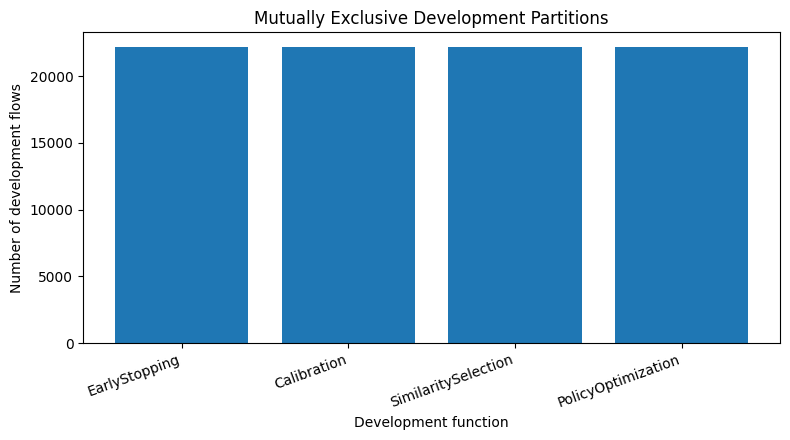


[Reviewer 3] Exact plotted values: R2_development_partition_sizes
           Function  Rows
      EarlyStopping 22179
        Calibration 22179
SimilaritySelection 22180
 PolicyOptimization 22180
Saved numerical table: /content/drive/MyDrive/UNSW_NB15_IDS_XAI_BCCC_Method_Replication2/reviewer_strict_revision_1_7/tables/R2_development_partition_sizes_numeric_table.csv


In [21]:
# BLOCK R1/R2: FOUR DISJOINT DEVELOPMENT FUNCTIONS


from itertools import combinations

print("=" * 115)
print("REVIEWER R1/R2: DISJOINT DEVELOPMENT PARTITIONING")
print("=" * 115)

development_pool_df = validation_df.copy().reset_index(drop=True)
print(f"Development pool rows: {len(development_pool_df):,}")

assert len(development_pool_df) > 0, (
    "Development pool is empty. Check the upstream UNSW partitioning."
)
assert development_pool_df["label"].nunique() == CLASS_COUNT, (
    f"Expected {CLASS_COUNT} classes, "
    f"found {development_pool_df['label'].nunique()}."
)

development_pool_df["_DEV_ROW_ID"] = np.arange(
    len(development_pool_df), dtype=np.int64
)
original_dev_size = len(development_pool_df)
original_dev_classes = set(development_pool_df["label"].unique())


def split_development_pool(dev_df, seed=42):
    """Return four stratified, mutually exclusive 25% development functions."""
    dev_df = dev_df.copy()

    early_df, remaining_75 = train_test_split(
        dev_df,
        test_size=0.75,
        random_state=seed,
        stratify=dev_df["label"],
    )
    calib_df, remaining_50 = train_test_split(
        remaining_75,
        test_size=2 / 3,
        random_state=seed + 1,
        stratify=remaining_75["label"],
    )
    sim_df, policy_df = train_test_split(
        remaining_50,
        test_size=0.50,
        random_state=seed + 2,
        stratify=remaining_50["label"],
    )

    return tuple(
        frame.reset_index(drop=True)
        for frame in (early_df, calib_df, sim_df, policy_df)
    )


(
    earlystop_dev_df,
    calibration_dev_df,
    similarity_dev_df,
    policy_dev_df,
) = split_development_pool(
    development_pool_df,
    CONFIG["development_split_seed"],
)

parts = {
    "EarlyStopping": earlystop_dev_df,
    "Calibration": calibration_dev_df,
    "SimilaritySelection": similarity_dev_df,
    "PolicyOptimization": policy_dev_df,
}

for name, frame in parts.items():
    assert len(frame) > 0, f"{name} split is empty."
    assert set(frame["label"].unique()) == original_dev_classes, (
        f"{name} lost one or more classes."
    )

id_sets = {
    name: set(frame["_DEV_ROW_ID"].astype(int))
    for name, frame in parts.items()
}

for a, b in combinations(id_sets, 2):
    overlap = id_sets[a] & id_sets[b]
    assert not overlap, (
        f"Development leakage detected between {a} and {b}: "
        f"{len(overlap)} shared original rows."
    )

all_partition_ids = set().union(*id_sets.values())
assert len(all_partition_ids) == original_dev_size
assert sum(len(frame) for frame in parts.values()) == original_dev_size

excluded_hash_columns = {"_DEV_ROW_ID", "_MASTER_ROW_ID"}
diagnostic_cols = [
    c for c in development_pool_df.columns
    if c not in excluded_hash_columns
]

content_hashes = {}
for name, frame in parts.items():
    hashes = pd.util.hash_pandas_object(
        frame[diagnostic_cols],
        index=False,
    ).astype("uint64")
    content_hashes[name] = set(hashes)

duplicate_content_records = []
for a, b in combinations(content_hashes, 2):
    duplicate_content_records.append({
        "Partition_A": a,
        "Partition_B": b,
        "Identical_Full_Row_Hashes": len(content_hashes[a] & content_hashes[b]),
        "Shared_Row_IDs": len(id_sets[a] & id_sets[b]),
    })

duplicate_content_df = pd.DataFrame(duplicate_content_records)

development_manifest_df = pd.DataFrame([
    {
        "Function": name,
        "Rows": len(frame),
        "Fraction_of_Development_Pool": len(frame) / original_dev_size,
        "Classes": frame["label"].nunique(),
        "Unique_Row_IDs": frame["_DEV_ROW_ID"].nunique(),
    }
    for name, frame in parts.items()
])

print("\n[Reviewer R2] Disjoint development manifest")
print(development_manifest_df.to_string(index=False))
print("\n[Full-row duplicate-content diagnostic]")
print(duplicate_content_df.to_string(index=False))

print("\nPASS: all four development subsets contain mutually exclusive original row IDs.")
print("PASS: all development rows are accounted for exactly once.")

full_content_overlap = int(
    duplicate_content_df["Identical_Full_Row_Hashes"].sum()
)
if full_content_overlap == 0:
    print("PASS: no identical full-row content was found across development functions.")
else:
    print(
        "WARNING: identical full-row content exists across development functions; "
        "investigate before final reporting."
    )

development_manifest_df.to_csv(
    os.path.join(REV_TABLE_DIR, "R2_development_partition_manifest.csv"),
    index=False,
)
duplicate_content_df.to_csv(
    os.path.join(REV_TABLE_DIR, "R2_duplicate_content_diagnostic.csv"),
    index=False,
)

plt.figure(figsize=(8, 4.5))
plt.bar(development_manifest_df["Function"], development_manifest_df["Rows"])
plt.ylabel("Number of development flows")
plt.xlabel("Development function")
plt.title("Mutually Exclusive Development Partitions")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(REV_FIG_DIR, "R2_development_partition_sizes.png"),
    dpi=220,
    bbox_inches="tight",
)
plt.show()

print("=" * 115)


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_numeric_df = development_manifest_df[["Function", "Rows"]].copy()
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R2_development_partition_sizes_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R2_development_partition_sizes")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)


# Stage 3 — Model Training and Probability Calibration


In [22]:
# BLOCK R2A: TRAIN-ONLY PREPROCESSING, MODEL DEVELOPMENT, AND CALIBRATION
# EarlyStopping and Calibration are strictly separate development functions.

import lightgbm as lgb
from sklearn.calibration import IsotonicRegression


def fit_feature_preprocessor(frame, feature_names):
    """
    Fit all conversion/imputation rules on the supplied training frame only.
    Numeric columns learn a training median.
    Non-numeric columns learn a deterministic training-only category mapping.
    """
    prep = {
        "feature_names": list(feature_names),
        "numeric_features": [],
        "categorical_features": [],
        "medians": {},
        "category_maps": {},
    }

    for feature in feature_names:
        s = frame[feature]
        numeric = pd.to_numeric(s, errors="coerce")

        nonmissing_original = int(s.notna().sum())
        nonmissing_numeric = int(numeric.notna().sum())
        is_numeric = (
            nonmissing_original == 0
            or nonmissing_numeric == nonmissing_original
        )

        if is_numeric:
            values = numeric.replace([np.inf, -np.inf], np.nan)
            median = float(values.median()) if values.notna().any() else 0.0
            prep["numeric_features"].append(feature)
            prep["medians"][feature] = median
        else:
            values = s.astype("string").fillna("<MISSING>")
            categories = sorted(values.unique().tolist())
            prep["categorical_features"].append(feature)
            prep["category_maps"][feature] = {
                category: idx
                for idx, category in enumerate(categories)
            }

    return prep


def transform_features(frame, preprocessor=None):
    """Apply an already fitted preprocessor without learning from `frame`."""
    if preprocessor is None:
        preprocessor = PRIMARY_PREPROCESSOR

    feature_names = preprocessor["feature_names"]
    out = np.empty((len(frame), len(feature_names)), dtype=np.float32)

    for j, feature in enumerate(feature_names):
        if feature in preprocessor["medians"]:
            values = pd.to_numeric(frame[feature], errors="coerce")
            values = values.replace([np.inf, -np.inf], np.nan)
            values = values.fillna(preprocessor["medians"][feature])
            out[:, j] = values.to_numpy(dtype=np.float32)
        else:
            mapping = preprocessor["category_maps"][feature]
            values = frame[feature].astype("string").fillna("<MISSING>")
            out[:, j] = (
                values.map(mapping)
                .fillna(-1)
                .to_numpy(dtype=np.float32)
            )

    if not np.isfinite(out).all():
        raise ValueError("Non-finite values remain after preprocessing.")

    return out


PRIMARY_PREPROCESSOR = fit_feature_preprocessor(
    train_df,
    expected_features,
)

print("[Preprocessing] Numeric features:", len(PRIMARY_PREPROCESSOR["numeric_features"]))
print("[Preprocessing] Categorical features:", len(PRIMARY_PREPROCESSOR["categorical_features"]))
if PRIMARY_PREPROCESSOR["categorical_features"]:
    print(
        "[Preprocessing] Categorical feature names:",
        PRIMARY_PREPROCESSOR["categorical_features"],
    )

X_train = transform_features(train_df)
y_train = encode_active_labels(train_df["label"], zero_day_value=None)

X_early = transform_features(earlystop_dev_df)
y_early = encode_active_labels(
    earlystop_dev_df["label"],
    zero_day_value=None,
)

X_calib = transform_features(calibration_dev_df)
y_calib = encode_active_labels(
    calibration_dev_df["label"],
    zero_day_value=None,
)

train_data = lgb.Dataset(X_train, label=y_train)
early_data = lgb.Dataset(
    X_early,
    label=y_early,
    reference=train_data,
)

MAIN_PARAMS = {
    "objective": "multiclass",
    "num_class": CLASS_COUNT,
    "metric": "multi_logloss",
    "learning_rate": 0.05,
    "num_leaves": 32,
    "feature_fraction": 0.90,
    "bagging_fraction": 0.90,
    "bagging_freq": 1,
    "seed": RANDOM_STATE,
    "bagging_seed": RANDOM_STATE,
    "feature_fraction_seed": RANDOM_STATE,
    "data_random_seed": RANDOM_STATE,
    "num_threads": max(1, (os.cpu_count() or 2) - 1),
    "verbose": -1,
}

lgb_model = lgb.train(
    MAIN_PARAMS,
    train_data,
    num_boost_round=200,
    valid_sets=[early_data],
    valid_names=["EarlyStopping"],
    callbacks=[lgb.early_stopping(15, verbose=False)],
)

raw_calib = np.asarray(lgb_model.predict(X_calib), dtype=float)

calibrators = {}
for class_idx in range(CLASS_COUNT):
    target = (y_calib == class_idx).astype(int)

    if len(np.unique(target)) < 2:
        raise ValueError(
            f"Calibration subset lacks both binary outcomes for class index {class_idx}."
        )

    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(raw_calib[:, class_idx], target)
    calibrators[class_idx] = iso


def get_calibrated_probabilities(model, idx_calibrators, X_matrix):
    """
    Apply class-wise one-vs-rest isotonic calibration, then renormalize
    to a multiclass probability simplex.
    """
    X_matrix = np.asarray(X_matrix, dtype=np.float32)
    raw = np.asarray(model.predict(X_matrix), dtype=float)

    calibrated = np.zeros_like(raw, dtype=float)
    for cls_idx in range(raw.shape[1]):
        calibrated[:, cls_idx] = idx_calibrators[cls_idx].transform(
            raw[:, cls_idx]
        )

    row_sum = calibrated.sum(axis=1, keepdims=True)
    zero_rows = row_sum[:, 0] <= 1e-12

    if np.any(zero_rows):
        calibrated[zero_rows] = raw[zero_rows]
        row_sum = calibrated.sum(axis=1, keepdims=True)

    row_sum[row_sum <= 1e-12] = 1.0
    return calibrated / row_sum


print("[Reviewer R2] Preprocessing fitted on Train only.")
print("[Reviewer R2] Early stopping uses EarlyStopping only.")
print("[Reviewer R2] Isotonic calibration uses Calibration only.")
print("Best boosting iteration:", lgb_model.best_iteration)


[Preprocessing] Numeric features: 38
[Preprocessing] Categorical features: 0
[Reviewer R2] Preprocessing fitted on Train only.
[Reviewer R2] Early stopping uses EarlyStopping only.
[Reviewer R2] Isotonic calibration uses Calibration only.
Best boosting iteration: 37


### Test-set firewall

No Host-Test, Time-Test, or Hard-Test performance is inspected here. All primary similarity and routing-policy choices are completed and frozen before final test evaluation.


# Stage 4 — Attribution Signature Construction and Stability



[Reviewer 3] Signature stability summary
 Sample_Size  Mean_Stability  Std_Stability  P05_Stability  Worst_Class_Stability
          20        0.963569       0.077924       0.835815               0.313460
          40        0.990375       0.012955       0.966746               0.927615
          50        0.993574       0.008747       0.977484               0.946457
          80        0.992612       0.017196       0.966521               0.887283
         100        0.996372       0.006713       0.985407               0.960863
         150        0.997835       0.004265       0.990658               0.976262
         160        0.998429       0.002201       0.994349               0.984239
         200        0.998813       0.002060       0.995408               0.985835
         250        0.998693       0.002396       0.994810               0.985725
         300        0.999032       0.001892       0.996207               0.985538
Selected signature sample size: 150
Selection rule: smal

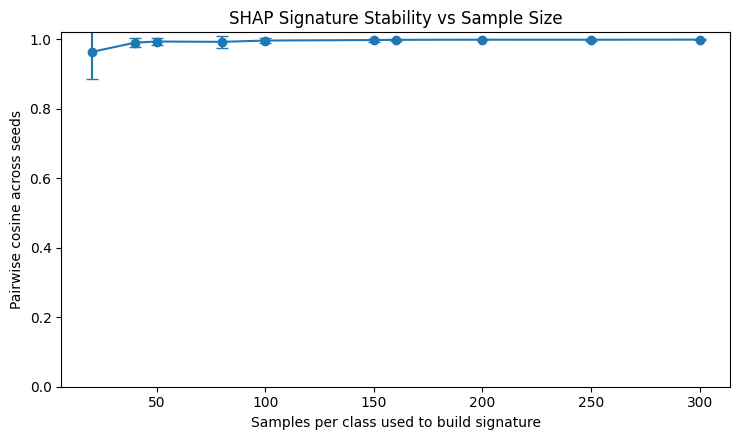


[Reviewer 3] Exact plotted values: R3_signature_stability_vs_sample_size
 Sample_Size  Mean_Stability  Std_Stability
          20      0.96356939    0.077924154
          40      0.99037548    0.012954973
          50      0.99357435   0.0087471632
          80      0.99261232    0.017195755
         100      0.99637168   0.0067128302
         150      0.99783533   0.0042653272
         160      0.99842931   0.0022011489
         200      0.99881294   0.0020597792
         250      0.99869296   0.0023961042
         300      0.99903196   0.0018915108
Saved numerical table: /content/drive/MyDrive/UNSW_NB15_IDS_XAI_BCCC_Method_Replication2/reviewer_strict_revision_1_7/tables/R3_signature_stability_vs_sample_size_numeric_table.csv


In [23]:
# BLOCK R3A: SHAP SIGNATURE STABILITY — SAMPLE SIZE × RANDOM SEED


def _row_l2_normalize(A):
    A = np.asarray(A, dtype=np.float32)
    norms = np.linalg.norm(A, axis=1, keepdims=True)
    return np.divide(A, norms, out=np.zeros_like(A), where=norms > 1e-12)


def build_signature_bank(model, train_frame, sample_size, seed):
    X_ref = transform_features(train_frame)
    y_ref = encode_active_labels(train_frame['label'], zero_day_value=None)
    bank = {}
    variances = {}
    for cls_idx in range(CLASS_COUNT):
        rows = np.where(y_ref == cls_idx)[0]
        rng = np.random.default_rng(seed + 1009 * cls_idx)
        take = rng.choice(rows, size=min(len(rows), int(sample_size)), replace=False)
        requested = np.full(len(take), cls_idx, dtype=int)
        attrs = fast_predicted_class_attributions(model, X_ref[take], requested,
                                                   batch_size=CONFIG.get('attribution_batch_size',8192))
        norm = _row_l2_normalize(attrs)
        mean_vec = np.mean(norm, axis=0)
        mean_vec = mean_vec / (np.linalg.norm(mean_vec) + 1e-12)
        name = resolve_active_class_name(cls_idx)
        bank[name] = mean_vec.astype(np.float32)
        variances[name] = np.var(norm, axis=0, ddof=0).astype(np.float32)  # true variance
    return bank, variances


def cosine_vec(a,b):
    a=np.asarray(a,float); b=np.asarray(b,float)
    return float(np.dot(a,b)/((np.linalg.norm(a)*np.linalg.norm(b))+1e-12))

signature_banks = {}
stability_records = []
for n in CONFIG['signature_sample_sizes']:
    signature_banks[n] = {}
    for seed in CONFIG['signature_stability_seeds']:
        bank, varbank = build_signature_bank(lgb_model, train_df, n, seed)
        signature_banks[n][seed] = bank
    for cls_name in ACTIVE_CLASS_NAMES:
        vals=[]
        for s1,s2 in combinations(CONFIG['signature_stability_seeds'],2):
            vals.append(cosine_vec(signature_banks[n][s1][cls_name], signature_banks[n][s2][cls_name]))
        stability_records.append({
            'Sample_Size': n,
            'Class': cls_name,
            'Mean_Pairwise_Cosine': float(np.mean(vals)),
            'Std_Pairwise_Cosine': float(np.std(vals)),
            'Min_Pairwise_Cosine': float(np.min(vals)),
        })

signature_stability_class_df = pd.DataFrame(stability_records)
signature_stability_summary_df = signature_stability_class_df.groupby('Sample_Size').agg(
    Mean_Stability=('Mean_Pairwise_Cosine','mean'),
    Std_Stability=('Mean_Pairwise_Cosine','std'),
    P05_Stability=('Mean_Pairwise_Cosine', lambda x: float(np.quantile(x,0.05))),
    Worst_Class_Stability=('Min_Pairwise_Cosine','min'),
).reset_index()

eligible = signature_stability_summary_df[
    (signature_stability_summary_df['Mean_Stability'] >= CONFIG['signature_stability_mean_floor']) &
    (signature_stability_summary_df['P05_Stability'] >= CONFIG['signature_stability_p05_floor'])
]
SELECTED_SIGNATURE_SAMPLE_SIZE = int(
    eligible['Sample_Size'].min() if len(eligible) else signature_stability_summary_df['Sample_Size'].max()
)
PRIMARY_SIGNATURE_SEED = int(CONFIG['signature_stability_seeds'][0])
train_signatures = signature_banks[SELECTED_SIGNATURE_SAMPLE_SIZE][PRIMARY_SIGNATURE_SEED]

print('\n[Reviewer 3] Signature stability summary')
print(signature_stability_summary_df.to_string(index=False))
print('Selected signature sample size:', SELECTED_SIGNATURE_SAMPLE_SIZE)
print('Selection rule: smallest candidate with Mean Stability >= 0.99 and P05 Stability >= 0.99')
signature_stability_class_df.to_csv(os.path.join(REV_TABLE_DIR,'R3_signature_stability_by_class.csv'),index=False)
signature_stability_summary_df.to_csv(os.path.join(REV_TABLE_DIR,'R3_signature_stability_summary.csv'),index=False)

plt.figure(figsize=(7.5,4.5))
plt.errorbar(signature_stability_summary_df['Sample_Size'],
             signature_stability_summary_df['Mean_Stability'],
             yerr=signature_stability_summary_df['Std_Stability'], marker='o', capsize=4)
plt.xlabel('Samples per class used to build signature')
plt.ylabel('Pairwise cosine across seeds')
plt.title('SHAP Signature Stability vs Sample Size')
plt.ylim(0,1.02)
plt.tight_layout()
plt.savefig(os.path.join(REV_FIG_DIR,'R3_signature_stability_vs_sample_size.png'),dpi=220)
plt.show()


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_numeric_df = signature_stability_summary_df[["Sample_Size", "Mean_Stability", "Std_Stability"]].copy()
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R3_signature_stability_vs_sample_size_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R3_signature_stability_vs_sample_size")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)



[Reviewer 3] Single-signature multimodality diagnostic
         Class  Best_K  Best_Silhouette  Mean_Nearest_Centroid_Gain  Potentially_Multimodal
        Benign       2         0.518579                    0.260058                    True
      Analysis       2         0.763968                    0.057674                    True
      Backdoor       3         0.723445                    0.081947                    True
           DoS       3         0.408478                    0.019327                    True
      Exploits       2         0.689931                    0.035981                    True
       Fuzzers       2         0.870671                   -0.000017                   False
       Generic       3         0.883148                    0.104524                    True
Reconnaissance       2         0.442539                    0.005166                   False
     Shellcode       2         0.319742                    0.074326                   False
         Worms       3  

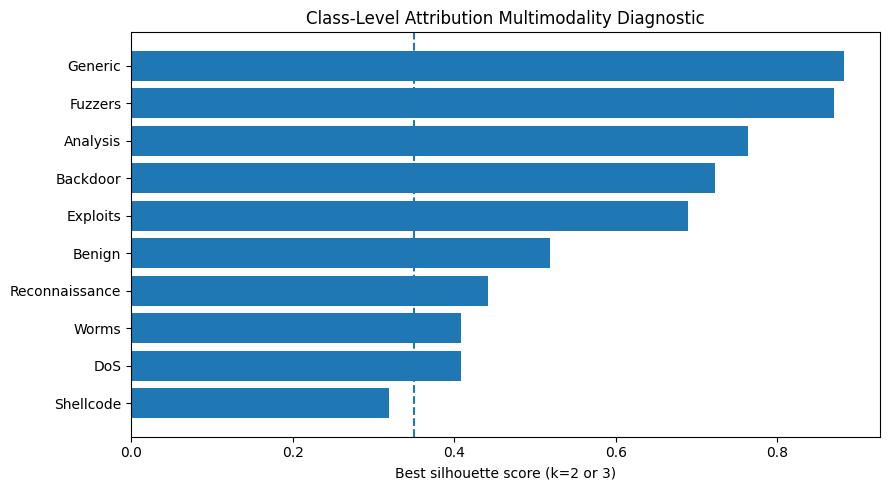


[Reviewer 3] Exact plotted values: R3_signature_multimodality
         Class  Best_Silhouette
     Shellcode       0.31974167
           DoS       0.40847847
         Worms       0.40910816
Reconnaissance       0.44253859
        Benign       0.51857889
      Exploits       0.68993109
      Backdoor       0.72344452
      Analysis       0.76396841
       Fuzzers       0.87067127
       Generic       0.88314825
Saved numerical table: /content/drive/MyDrive/UNSW_NB15_IDS_XAI_BCCC_Method_Replication2/reviewer_strict_revision_1_7/tables/R3_signature_multimodality_numeric_table.csv


In [24]:
# BLOCK R3B: MULTIMODALITY DIAGNOSTIC — DOES ONE MEAN SIGNATURE REPRESENT EACH CLASS?
# This does not automatically change the final architecture. It reports whether multiple centroids
# materially improve held-out within-training attribution representation.

multimodal_records=[]
X_train_np = transform_features(train_df)
y_train_np = encode_active_labels(train_df['label'], zero_day_value=None)

for cls_idx in range(CLASS_COUNT):
    rows=np.where(y_train_np==cls_idx)[0]
    rng=np.random.default_rng(7000+cls_idx)
    take=rng.choice(rows,size=min(len(rows),CONFIG['multimodal_max_rows_per_class']),replace=False)
    attrs=fast_predicted_class_attributions(lgb_model,X_train_np[take],np.full(len(take),cls_idx,dtype=int),
                                             batch_size=CONFIG.get('attribution_batch_size',8192))
    Z=_row_l2_normalize(attrs)
    if len(Z)<30:
        continue
    fit_idx, eval_idx = train_test_split(np.arange(len(Z)), test_size=0.30, random_state=42)
    Zfit,Zeval=Z[fit_idx],Z[eval_idx]
    single=np.mean(Zfit,axis=0); single/=np.linalg.norm(single)+1e-12
    single_sim=Zeval@single
    best_k=1; best_sil=np.nan; best_gain=0.0
    for k in [2,3]:
        if len(Zfit)<=k: continue
        km=KMeans(n_clusters=k,random_state=42,n_init=10).fit(Zfit)
        sil=float(silhouette_score(Zfit,km.labels_)) if len(np.unique(km.labels_))>1 else np.nan
        cent=_row_l2_normalize(km.cluster_centers_)
        multi_sim=np.max(Zeval@cent.T,axis=1)
        gain=float(np.mean(multi_sim-single_sim))
        if np.isnan(best_sil) or sil>best_sil:
            best_k=k; best_sil=sil; best_gain=gain
    multimodal_records.append({
        'Class':resolve_active_class_name(cls_idx),
        'Best_K':best_k,
        'Best_Silhouette':best_sil,
        'Mean_Nearest_Centroid_Gain':best_gain,
        'Potentially_Multimodal':bool((best_sil if np.isfinite(best_sil) else -1)>=CONFIG['multimodal_silhouette_flag'] and best_gain>0.01),
    })

signature_multimodality_df=pd.DataFrame(multimodal_records)
print('\n[Reviewer 3] Single-signature multimodality diagnostic')
print(signature_multimodality_df.to_string(index=False))
signature_multimodality_df.to_csv(os.path.join(REV_TABLE_DIR,'R3_signature_multimodality_diagnostic.csv'),index=False)

plt.figure(figsize=(9,5))
plot_df=signature_multimodality_df.sort_values('Best_Silhouette')
plt.barh(plot_df['Class'],plot_df['Best_Silhouette'])
plt.axvline(CONFIG['multimodal_silhouette_flag'],linestyle='--')
plt.xlabel('Best silhouette score (k=2 or 3)')
plt.title('Class-Level Attribution Multimodality Diagnostic')
plt.tight_layout()
plt.savefig(os.path.join(REV_FIG_DIR,'R3_signature_multimodality.png'),dpi=220)
plt.show()


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_numeric_df = plot_df[["Class", "Best_Silhouette"]].copy()
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R3_signature_multimodality_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R3_signature_multimodality")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)


# Stage 5 — Development-Only Similarity Selection



[Reviewer 1] DEVELOPMENT-ONLY similarity metric selection
   Metric  Correct_Mean  Incorrect_Mean  Separation_Gap  Separation_AUC  Development_Rows  Incorrect_Rows
   Cosine      0.572044        0.794588       -0.222544        0.342975             22180             904
Euclidean      0.570503        0.669282       -0.098779        0.342975             22180             904
  Pearson      0.567747        0.780429       -0.212683        0.348613             22180             904
 Spearman      0.528067        0.312054        0.216013        0.757590             22180             904
SELECTED_SIMILARITY_METRIC = Spearman


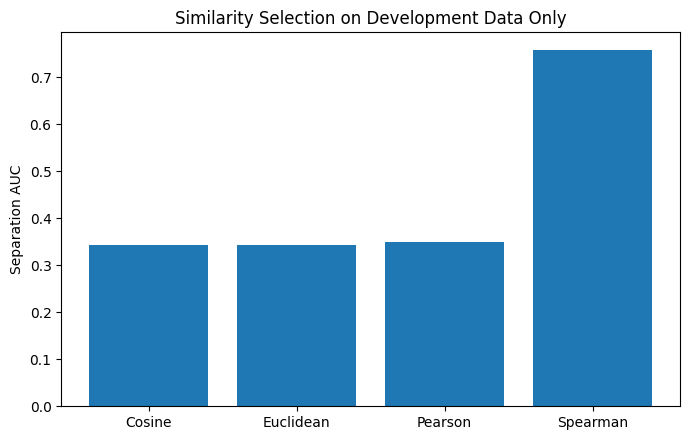


[Reviewer 3] Exact plotted values: R1_similarity_selection_auc
   Metric  Separation_AUC
   Cosine      0.34297528
Euclidean      0.34297528
  Pearson      0.34861331
 Spearman      0.75759004
Saved numerical table: /content/drive/MyDrive/UNSW_NB15_IDS_XAI_BCCC_Method_Replication2/reviewer_strict_revision_1_7/tables/R1_similarity_selection_auc_numeric_table.csv


In [25]:
# BLOCK R1: SIMILARITY METRIC SELECTION ON DEVELOPMENT DATA ONLY
# Host-Test, Time-Test, Hard-Test, and adversarial data are not touched here.


def _similarity_scores_from_normalized(Z, ref, metric):
    Z=np.asarray(Z,float); ref=np.asarray(ref,float)
    ref=ref/(np.linalg.norm(ref)+1e-12)
    metric=metric.lower()
    if metric=='cosine':
        return Z@ref
    if metric=='euclidean':
        return 1.0/(1.0+np.linalg.norm(Z-ref[None,:],axis=1))
    out=np.zeros(len(Z),dtype=float)
    for i,row in enumerate(Z):
        if metric=='pearson':
            v=pearsonr(row,ref).statistic
        elif metric=='spearman':
            v=spearmanr(row,ref).correlation
        else:
            raise ValueError(metric)
        out[i]=0.0 if not np.isfinite(v) else float(v)
    return out


def compute_similarity_metric(model, reference_signatures, X_matrix, pred_idx, pred_names, metric):
    X=np.asarray(X_matrix,dtype=np.float32); pred_idx=np.asarray(pred_idx,int); pred_names=np.asarray(pred_names,object)
    attrs=fast_predicted_class_attributions(model,X,pred_idx,batch_size=CONFIG.get('attribution_batch_size',8192))
    Z=_row_l2_normalize(attrs)
    sims=np.zeros(len(X),dtype=float)
    for name in np.unique(pred_names):
        m=pred_names==name
        ref=reference_signatures.get(name)
        if ref is None: continue
        sims[m]=_similarity_scores_from_normalized(Z[m],ref,metric)
    return sims,Z

X_sim=transform_features(similarity_dev_df)
y_sim=encode_active_labels(similarity_dev_df['label'],zero_day_value=None)
prob_sim=get_calibrated_probabilities(lgb_model,calibrators,X_sim)
pred_sim=np.argmax(prob_sim,axis=1)
pred_names_sim=np.asarray([resolve_active_class_name(i) for i in pred_sim],dtype=object)
correct=(pred_sim==y_sim).astype(int)

metric_records=[]
for metric in ['Cosine','Euclidean','Pearson','Spearman']:
    sims,_=compute_similarity_metric(lgb_model,train_signatures,X_sim,pred_sim,pred_names_sim,metric)
    c=sims[correct==1]; w=sims[correct==0]
    gap=float(np.mean(c)-np.mean(w)) if len(c) and len(w) else np.nan
    auc=float(roc_auc_score(correct,sims)) if len(np.unique(correct))==2 else np.nan
    metric_records.append({'Metric':metric,'Correct_Mean':np.mean(c) if len(c) else np.nan,
                           'Incorrect_Mean':np.mean(w) if len(w) else np.nan,
                           'Separation_Gap':gap,'Separation_AUC':auc,
                           'Development_Rows':len(X_sim),'Incorrect_Rows':int(np.sum(correct==0))})

similarity_selection_df=pd.DataFrame(metric_records)
ranked=similarity_selection_df.sort_values(['Separation_AUC','Separation_Gap'],ascending=[False,False],na_position='last')
SELECTED_SIMILARITY_METRIC=str(ranked.iloc[0]['Metric'])
print('\n[Reviewer 1] DEVELOPMENT-ONLY similarity metric selection')
print(similarity_selection_df.to_string(index=False))
print('SELECTED_SIMILARITY_METRIC =',SELECTED_SIMILARITY_METRIC)
similarity_selection_df.to_csv(os.path.join(REV_TABLE_DIR,'R1_similarity_selection_development_only.csv'),index=False)

plt.figure(figsize=(7,4.5))
plt.bar(similarity_selection_df['Metric'],similarity_selection_df['Separation_AUC'])
plt.ylabel('Separation AUC')
plt.title('Similarity Selection on Development Data Only')
plt.tight_layout()
plt.savefig(os.path.join(REV_FIG_DIR,'R1_similarity_selection_auc.png'),dpi=220)
plt.show()


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_numeric_df = similarity_selection_df[["Metric", "Separation_AUC"]].copy()
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R1_similarity_selection_auc_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R1_similarity_selection_auc")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)


# Stage 6 — Containment-First Policy Optimization and Policy Freeze


In [26]:
# =============================================================================
# BLOCK R2B: ESCALATION-AWARE REVIEWER-2 DEVELOPMENT POLICY OPTIMIZATION
# DROP-IN VERSION WITH EXPLICIT UPSTREAM DEPENDENCY AUDIT
#
# IMPORTANT:
#   This is the COMPLETE R2B block.
#   It is designed to be pasted into the existing notebook after the earlier
#   setup / ingestion / preprocessing / development-split / signature-selection
#   stages have been executed.
#
#   It does NOT recreate upstream experimental objects. Instead, it verifies
#   them explicitly before any R2B computation begins. If something is missing,
#   execution stops immediately with a precise list rather than failing later
#   with a NameError.
# =============================================================================

# =============================================================================
# 0. PRE-RUN DEPENDENCY AUDIT
# =============================================================================

_R2B_REQUIRED_GLOBALS = [
    # Core experiment configuration / data
    "CONFIG",
    "train_df",
    "development_pool_df",
    "PRIMARY_PREPROCESSOR",
    "MAIN_PARAMS",

    # Frozen development-side selections established earlier
    "SELECTED_SIGNATURE_SAMPLE_SIZE",
    "SELECTED_SIMILARITY_METRIC",

    # Label / class definitions
    "BENIGN_IDX",
    "CLASS_COUNT",

    # Output location
    "REV_TABLE_DIR",

    # Core helper functions established earlier in the notebook
    "split_development_pool",
    "transform_features",
    "encode_active_labels",
    "get_calibrated_probabilities",
    "compute_similarity_metric",
    "route_policy_batch",
    "build_signature_bank",
    "resolve_active_class_name",

    # Imported libraries / classes used directly in R2B
    "np",
    "pd",
    "os",
    "gc",
    "lgb",
    "IsotonicRegression",
]

_R2B_MISSING_GLOBALS = [
    name
    for name in _R2B_REQUIRED_GLOBALS
    if name not in globals()
]

if _R2B_MISSING_GLOBALS:
    raise RuntimeError(
        "R2B cannot start because required upstream notebook objects are "
        "missing from the current runtime:\n  - "
        + "\n  - ".join(_R2B_MISSING_GLOBALS)
        + "\n\nRun the earlier notebook setup/configuration/data/preprocessing/"
          "development-split cells first, then rerun this complete R2B block."
    )

# Basic structural checks on the most important objects.
if len(train_df) == 0:
    raise RuntimeError("R2B dependency audit failed: train_df is empty.")

if len(development_pool_df) == 0:
    raise RuntimeError(
        "R2B dependency audit failed: development_pool_df is empty."
    )

if "label" not in train_df.columns:
    raise RuntimeError(
        "R2B dependency audit failed: train_df has no 'label' column."
    )

if "label" not in development_pool_df.columns:
    raise RuntimeError(
        "R2B dependency audit failed: development_pool_df has no 'label' column."
    )

if int(SELECTED_SIGNATURE_SAMPLE_SIZE) <= 0:
    raise RuntimeError(
        "R2B dependency audit failed: SELECTED_SIGNATURE_SAMPLE_SIZE "
        "must be positive."
    )

if not isinstance(SELECTED_SIMILARITY_METRIC, str):
    raise RuntimeError(
        "R2B dependency audit failed: SELECTED_SIMILARITY_METRIC "
        "must be a string."
    )

if int(CLASS_COUNT) < 2:
    raise RuntimeError(
        "R2B dependency audit failed: CLASS_COUNT must be at least 2."
    )

if not (0 <= int(BENIGN_IDX) < int(CLASS_COUNT)):
    raise RuntimeError(
        "R2B dependency audit failed: BENIGN_IDX is outside the active "
        "class index range."
    )

print("\n" + "=" * 110)
print("[Reviewer R2] PRE-RUN DEPENDENCY AUDIT")
print("=" * 110)
print("PASS: All required upstream objects are present.")
print(f"Train rows                          : {len(train_df):,}")
print(f"Development-pool rows               : {len(development_pool_df):,}")
print(f"Active class count                  : {int(CLASS_COUNT)}")
print(f"Benign class index                  : {int(BENIGN_IDX)}")
print(f"Selected signature sample size      : {int(SELECTED_SIGNATURE_SAMPLE_SIZE)}")
print(f"Selected similarity metric          : {SELECTED_SIMILARITY_METRIC}")
print(f"Canonical development split seed    : {CONFIG.get('development_split_seed', 42)}")
print(f"ANMR safety floor                   : {CONFIG.get('anmr_safety_floor', 0.9999)}")
print(f"FBR safety ceiling                  : {CONFIG.get('fbr_safety_ceiling', 0.005)}")
print("=" * 110)


print("\n" + "=" * 110)
print("Escalation-aware repeated development-policy optimization and threshold stability")
print("=" * 110)


# =============================================================================
# 1. REVIEWER-2 CONFIGURATION
# =============================================================================

ANMR_SAFETY_FLOOR = float(
    CONFIG.get(
        "anmr_safety_floor",
        0.9999
    )
)

FBR_SAFETY_CEILING = float(
    CONFIG.get(
        "fbr_safety_ceiling",
        0.005
    )
)

# Five independent repeated development partitions.
R2_SPLIT_SEEDS = [
    42,
    123,
    456,
    789,
    2026
]


# =============================================================================
# 2. BASIC POLICY ARRAYS
# =============================================================================

def policy_arrays(
    model,
    calibs,
    signatures,
    frame,
    metric
):

    X = transform_features(frame)

    y = encode_active_labels(
        frame["label"],
        zero_day_value=None
    )

    probs = get_calibrated_probabilities(
        model,
        calibs,
        X
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    pred_names = np.asarray(
        [
            resolve_active_class_name(i)
            for i in pred
        ],
        dtype=object
    )

    true_names = np.asarray(
        [
            resolve_active_class_name(i)
            for i in y
        ],
        dtype=object
    )

    sims, _ = compute_similarity_metric(
        model,
        signatures,
        X,
        pred,
        pred_names,
        metric
    )

    return (
        X,
        y,
        probs,
        pred,
        pred_names,
        true_names,
        sims
    )


# =============================================================================
# 3. ROUTING POLICY OPTIMIZATION
# =============================================================================

def tune_routing_policy(
    model,
    calibs,
    signatures,
    frame,
    metric
):
    """
    Escalation-aware development-only routing optimization.

    Safety remains hard:
      ANMR >= ANMR_SAFETY_FLOOR
      FBR  <= FBR_SAFETY_CEILING

    Among safety-feasible candidates, the operational objective is:
      1) minimize ATTACK escalation rate,
      2) maximize automatic ATTACK block rate,
      3) maximize ANMR,
      4) minimize FBR,
      5) minimize overall escalation.

    This prevents a policy from receiving preference merely because it preserves
    ANMR by escalating almost every malicious flow.
    """

    (
        X,
        y,
        probs,
        pred,
        pred_names,
        true_names,
        sims
    ) = policy_arrays(
        model,
        calibs,
        signatures,
        frame,
        metric
    )

    benign_prob = probs[:, BENIGN_IDX]
    attack_conf = 1.0 - benign_prob
    pred_benign = (pred_names == "Benign")
    true_benign = (true_names == "Benign")
    true_malicious = (~true_benign)

    attack_n = max(int(np.sum(true_malicious)), 1)
    benign_n = max(int(np.sum(true_benign)), 1)

    # -------------------------------------------------------------------------
    # Development-only threshold grids.
    #
    # The ranges are intentionally retained from the previous reviewer-strict
    # pipeline so that the methodological change is the SELECTION OBJECTIVE,
    # not a post-hoc expansion based on final LOAFO outcomes.
    # -------------------------------------------------------------------------
    grids = {
        "tau_p": np.linspace(0.60, 0.98, 8),
        "tau_s": np.linspace(0.01, 0.40, 8),
        "benign_prob": np.linspace(0.90, 0.99, 6),
        "benign_sim": np.linspace(0.05, 0.40, 6),
        "high_conf_benign_prob": np.array([0.995, 0.9975, 0.999, 0.9995]),
        "high_conf_benign_sim": np.array([0.00, 0.01, 0.02, 0.03, 0.04]),
    }

    best_fallback = None
    feasible = []

    for tau_p in grids["tau_p"]:
        for tau_s in grids["tau_s"]:

            block_base = (
                (~pred_benign)
                & (attack_conf >= tau_p)
                & (sims >= 0.5 * tau_s)
            )

            for benign_prob_tau in grids["benign_prob"]:
                for benign_sim_tau in grids["benign_sim"]:

                    ordinary_allow = (
                        pred_benign
                        & (benign_prob >= benign_prob_tau)
                        & (sims >= max(tau_s, benign_sim_tau))
                    )

                    for high_conf_benign_prob_tau in grids["high_conf_benign_prob"]:
                        for high_conf_benign_sim_floor in grids["high_conf_benign_sim"]:

                            high_conf_benign_allow = (
                                pred_benign
                                & (benign_prob >= high_conf_benign_prob_tau)
                                & (sims >= high_conf_benign_sim_floor)
                            )

                            allow = ordinary_allow | high_conf_benign_allow
                            block = block_base & (~allow)
                            escalate = ~(allow | block)

                            attack_allow_count = int(np.sum(true_malicious & allow))
                            attack_block_count = int(np.sum(true_malicious & block))
                            attack_escalate_count = int(np.sum(true_malicious & escalate))
                            false_blocks = int(np.sum(true_benign & block))

                            attack_allow_rate = float(attack_allow_count / attack_n)
                            attack_block_rate = float(attack_block_count / attack_n)
                            attack_escalation_rate = float(attack_escalate_count / attack_n)

                            anmr = float(1.0 - attack_allow_rate)
                            fbr = float(false_blocks / benign_n)
                            escalation = float(np.mean(escalate))

                            # Numerical audit: malicious actions must partition.
                            if not np.isclose(
                                attack_allow_rate
                                + attack_block_rate
                                + attack_escalation_rate,
                                1.0,
                                atol=1e-10,
                            ):
                                raise RuntimeError(
                                    "Attack ALLOW/BLOCK/ESCALATE rates do not sum to 1."
                                )

                            row = (
                                float(tau_p),
                                float(tau_s),
                                float(benign_prob_tau),
                                float(benign_sim_tau),
                                float(high_conf_benign_prob_tau),
                                float(high_conf_benign_sim_floor),
                                float(anmr),
                                float(fbr),
                                float(escalation),
                                float(attack_block_rate),
                                float(attack_escalation_rate),
                                float(attack_allow_rate),
                            )

                            violation = (
                                max(0.0, ANMR_SAFETY_FLOOR - anmr)
                                + max(0.0, fbr - FBR_SAFETY_CEILING)
                            )

                            # Fallback is used only if no safety-feasible policy
                            # exists. Safety violation is therefore first.
                            fallback_key = (
                                violation,
                                attack_escalation_rate,
                                -attack_block_rate,
                                -anmr,
                                fbr,
                                escalation,
                                -high_conf_benign_prob_tau,
                                -high_conf_benign_sim_floor,
                            )

                            if (
                                best_fallback is None
                                or fallback_key < best_fallback[0]
                            ):
                                best_fallback = (fallback_key, row)

                            if violation <= 1e-12:
                                feasible.append(row)

    if feasible:
        # IMPORTANT:
        # ANMR and FBR are HARD constraints here, not optimization rewards.
        # Once safety is satisfied, analyst burden and automatic containment
        # determine the policy.
        chosen = min(
            feasible,
            key=lambda r: (
                r[10],      # attack escalation rate: MINIMIZE
                -r[9],      # automatic attack block rate: MAXIMIZE
                -r[6],      # ANMR: MAXIMIZE
                r[7],       # FBR: MINIMIZE
                r[8],       # overall escalation: MINIMIZE
                -r[4],
                -r[5],
            ),
        )
        status = "SAFETY-FEASIBLE ESCALATION-AWARE ROUTING POLICY"
    else:
        if best_fallback is None:
            raise RuntimeError("Routing-policy optimization evaluated no candidates.")
        chosen = best_fallback[1]
        status = "FALLBACK: NO ROUTING CANDIDATE SATISFIED ANMR/FBR SAFETY"

    print("\n[Reviewer R2] Escalation-aware routing-policy selection")
    print("Selection status       :", status)
    print("ANMR                   :", chosen[6])
    print("FBR                    :", chosen[7])
    print("Overall escalation     :", chosen[8])
    print("Attack BLOCK rate      :", chosen[9])
    print("Attack ESCALATION rate :", chosen[10])
    print("Attack ALLOW rate      :", chosen[11])

    return chosen


# =============================================================================
# 4. SELECTIVE-ATTRIBUTION OPTIMIZATION
# =============================================================================

def tune_selective_policy(
    model,
    calibs,
    signatures,
    frame,
    metric,
    routing_values
):
    """
    Escalation-aware selective-attribution optimization.

    The full SHAP routing policy is already frozen within this development
    repetition. Direct-routing gates are selected only on PolicyOptimization.

    Hard constraints:
      ANMR >= ANMR_SAFETY_FLOOR
      FBR  <= FBR_SAFETY_CEILING
      both direct ALLOW and direct BLOCK must be active
      attribution fraction < 1

    Feasible candidates are ranked by:
      1) minimum ATTACK escalation,
      2) maximum automatic ATTACK block,
      3) maximum ANMR,
      4) minimum attribution workload,
      5) minimum FBR.

    This makes workload reduction secondary to the operational goal of resolving
    malicious flows automatically rather than sending them to analysts.
    """

    (
        tau_p,
        tau_s,
        benign_prob_tau,
        benign_sim_tau,
        high_conf_benign_prob_tau,
        high_conf_benign_sim_floor,
        *_
    ) = routing_values

    (
        X,
        y,
        probs,
        pred,
        pred_names,
        true_names,
        sims
    ) = policy_arrays(
        model,
        calibs,
        signatures,
        frame,
        metric
    )

    benign_prob = probs[:, BENIGN_IDX]
    attack_conf = 1.0 - benign_prob

    sorted_probs = np.sort(probs, axis=1)
    max_prob = sorted_probs[:, -1]
    margin = sorted_probs[:, -1] - sorted_probs[:, -2]

    pred_benign = (pred_names == "Benign")
    pred_attack = (~pred_benign)
    true_benign = (true_names == "Benign")
    true_malicious = (~true_benign)

    attack_n = max(int(np.sum(true_malicious)), 1)
    benign_n = max(int(np.sum(true_benign)), 1)

    full_route = route_policy_batch(
        pred_names,
        attack_conf,
        sims,
        tau_p,
        tau_s,
        benign_prob_tau,
        benign_sim_tau,
        high_conf_benign_prob_tau,
        high_conf_benign_sim_floor,
    )

    full_actions = np.asarray(full_route["actions"], dtype=object)

    # -------------------------------------------------------------------------
    # Development-only empirical quantile grids.
    #
    # Benign direct ALLOW remains conservative (upper-tail quantiles).
    # Attack direct BLOCK is deliberately given a broader development-derived
    # grid because the old 90-99%-only attack grid could force many correctly
    # attack-predicted flows into SHAP/ESCALATE even when FBR headroom existed.
    # No test/LOAFO result is used to choose these quantiles.
    # -------------------------------------------------------------------------
    BENIGN_DIRECT_QUANTILES = np.array([0.90, 0.95, 0.975, 0.99], dtype=float)
    ATTACK_DIRECT_QUANTILES = np.array(
        [0.50, 0.70, 0.80, 0.90, 0.95, 0.975, 0.99],
        dtype=float,
    )

    if not np.any(pred_benign):
        raise RuntimeError(
            "Selective-policy optimization has no predicted-Benign rows "
            "in the PolicyOptimization subset."
        )

    if not np.any(pred_attack):
        raise RuntimeError(
            "Selective-policy optimization has no predicted-Attack rows "
            "in the PolicyOptimization subset."
        )

    def _unique_empirical_quantiles(values, quantile_levels):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if len(values) == 0:
            raise RuntimeError(
                "Cannot derive selective thresholds from an empty/non-finite "
                "development distribution."
            )

        candidates = np.quantile(values, quantile_levels)
        candidates = np.unique(np.asarray(candidates, dtype=float))
        return np.clip(candidates, 0.0, 1.0)

    benign_prob_grid = _unique_empirical_quantiles(
        benign_prob[pred_benign],
        BENIGN_DIRECT_QUANTILES,
    )

    benign_margin_grid = _unique_empirical_quantiles(
        margin[pred_benign],
        BENIGN_DIRECT_QUANTILES,
    )

    attack_prob_grid = _unique_empirical_quantiles(
        max_prob[pred_attack],
        ATTACK_DIRECT_QUANTILES,
    )

    attack_margin_grid = _unique_empirical_quantiles(
        margin[pred_attack],
        ATTACK_DIRECT_QUANTILES,
    )

    print(
        "\n[Reviewer R2] Escalation-aware development-derived selective grids"
    )
    print("Benign direct quantiles:", BENIGN_DIRECT_QUANTILES.tolist())
    print("Attack direct quantiles:", ATTACK_DIRECT_QUANTILES.tolist())
    print("Benign direct prob     :", benign_prob_grid.tolist())
    print("Benign direct margin   :", benign_margin_grid.tolist())
    print("Attack direct prob     :", attack_prob_grid.tolist())
    print("Attack direct margin   :", attack_margin_grid.tolist())

    best_fallback = None
    feasible_candidates = []

    for benign_direct_prob in benign_prob_grid:
        for benign_direct_margin in benign_margin_grid:

            direct_allow = (
                pred_benign
                & (benign_prob >= benign_direct_prob)
                & (margin >= benign_direct_margin)
            )

            for attack_direct_prob in attack_prob_grid:
                for attack_direct_margin in attack_margin_grid:

                    direct_block = (
                        pred_attack
                        & (attack_conf >= tau_p)
                        & (max_prob >= attack_direct_prob)
                        & (margin >= attack_direct_margin)
                    )

                    unresolved = ~(direct_allow | direct_block)

                    actions = full_actions.copy()
                    actions[direct_allow] = "ALLOW"
                    actions[direct_block] = "BLOCK"

                    attack_allow_count = int(
                        np.sum(true_malicious & (actions == "ALLOW"))
                    )
                    attack_block_count = int(
                        np.sum(true_malicious & (actions == "BLOCK"))
                    )
                    attack_escalate_count = int(
                        np.sum(true_malicious & (actions == "ESCALATE"))
                    )
                    false_blocks = int(
                        np.sum(true_benign & (actions == "BLOCK"))
                    )

                    attack_allow_rate = float(attack_allow_count / attack_n)
                    attack_block_rate = float(attack_block_count / attack_n)
                    attack_escalation_rate = float(attack_escalate_count / attack_n)

                    anmr = float(1.0 - attack_allow_rate)
                    fbr = float(false_blocks / benign_n)
                    escalation = float(np.mean(actions == "ESCALATE"))
                    attribution_fraction = float(np.mean(unresolved))

                    if not np.isclose(
                        attack_allow_rate
                        + attack_block_rate
                        + attack_escalation_rate,
                        1.0,
                        atol=1e-10,
                    ):
                        raise RuntimeError(
                            "Selective attack ALLOW/BLOCK/ESCALATE rates do not sum to 1."
                        )

                    direct_allow_count = int(np.sum(direct_allow))
                    direct_block_count = int(np.sum(direct_block))

                    nondegenerate_selective = (
                        direct_allow_count > 0
                        and direct_block_count > 0
                        and attribution_fraction < 1.0
                    )

                    safety_violation = (
                        max(0.0, ANMR_SAFETY_FLOOR - anmr)
                        + max(0.0, fbr - FBR_SAFETY_CEILING)
                    )

                    row = (
                        float(benign_direct_prob),
                        float(benign_direct_margin),
                        float(attack_direct_prob),
                        float(attack_direct_margin),
                        float(anmr),
                        float(fbr),
                        float(escalation),
                        float(attribution_fraction),
                        float(attack_block_rate),
                        float(attack_escalation_rate),
                        float(attack_allow_rate),
                    )

                    fallback_key = (
                        0 if nondegenerate_selective else 1,
                        safety_violation,
                        attack_escalation_rate,
                        -attack_block_rate,
                        -anmr,
                        attribution_fraction,
                        fbr,
                    )

                    if (
                        best_fallback is None
                        or fallback_key < best_fallback[0]
                    ):
                        best_fallback = (
                            fallback_key,
                            row,
                            direct_allow_count,
                            direct_block_count,
                            nondegenerate_selective,
                        )

                    if (
                        safety_violation <= 1e-12
                        and nondegenerate_selective
                    ):
                        feasible_candidates.append(
                            (
                                row,
                                direct_allow_count,
                                direct_block_count,
                            )
                        )

    if feasible_candidates:
        chosen_row, chosen_allow_count, chosen_block_count = min(
            feasible_candidates,
            key=lambda item: (
                item[0][9],      # attack escalation: MINIMIZE
                -item[0][8],     # attack block: MAXIMIZE
                -item[0][4],     # ANMR: MAXIMIZE
                item[0][7],      # attribution workload: MINIMIZE
                item[0][5],      # FBR: MINIMIZE
                item[0][6],      # overall escalation: MINIMIZE
            ),
        )
        selection_status = (
            "SAFETY-FEASIBLE ESCALATION-AWARE SELECTIVE POLICY"
        )
    else:
        if best_fallback is None:
            raise RuntimeError(
                "Selective-policy optimization evaluated no candidates."
            )

        (
            _,
            chosen_row,
            chosen_allow_count,
            chosen_block_count,
            chosen_nondegenerate,
        ) = best_fallback

        selection_status = (
            "FALLBACK: NO SELECTIVE CANDIDATE SATISFIED ALL SAFETY + "
            "NON-DEGENERACY REQUIREMENTS"
        )

        if not chosen_nondegenerate:
            raise RuntimeError(
                "No non-degenerate selective policy exists on the "
                "PolicyOptimization subset."
            )

    print("\n[Reviewer R2] Escalation-aware selective-policy selection")
    print("Selection status       :", selection_status)
    print("Direct ALLOW count     :", chosen_allow_count)
    print("Direct BLOCK count     :", chosen_block_count)
    print("Attribution fraction   :", chosen_row[7])
    print("Selective ANMR         :", chosen_row[4])
    print("Selective FBR          :", chosen_row[5])
    print("Overall escalation     :", chosen_row[6])
    print("Attack BLOCK rate      :", chosen_row[8])
    print("Attack ESCALATION rate :", chosen_row[9])
    print("Attack ALLOW rate      :", chosen_row[10])

    return chosen_row


# =============================================================================
# 5. TRAIN + CALIBRATE ONE DEVELOPMENT REPETITION
# =============================================================================

def fit_r2_development_replication(
    split_seed
):

    (
        early_stop_df,
        calibration_df,
        similarity_df,
        policy_df
    ) = split_development_pool(
        development_pool_df,
        split_seed
    )

    # -------------------------------------------------------------------------
    # Training data
    #
    # IMPORTANT:
    # Use the PRIMARY_PREPROCESSOR fitted exclusively on train_df.
    # The repeated development split changes ONLY the functional allocation
    # of development rows. It does not refit preprocessing.
    # -------------------------------------------------------------------------

    X_train_r2 = transform_features(
        train_df,
        PRIMARY_PREPROCESSOR
    )

    y_train_r2 = encode_active_labels(
        train_df["label"],
        zero_day_value=None
    )

    # -------------------------------------------------------------------------
    # Dedicated early-stopping subset
    # -------------------------------------------------------------------------

    X_es_r2 = transform_features(
        early_stop_df,
        PRIMARY_PREPROCESSOR
    )

    y_es_r2 = encode_active_labels(
        early_stop_df["label"],
        zero_day_value=None
    )

    train_ds = lgb.Dataset(
        X_train_r2,
        label=y_train_r2
    )

    es_ds = lgb.Dataset(
        X_es_r2,
        label=y_es_r2,
        reference=train_ds
    )

    # -------------------------------------------------------------------------
    # Keep the model-training seed fixed.
    #
    # R2 measures sensitivity to DEVELOPMENT PARTITIONING only.
    # Training-seed sensitivity is evaluated separately in the
    # multi-seed robustness experiment.
    # -------------------------------------------------------------------------

    params = dict(
        MAIN_PARAMS
    )

    model = lgb.train(
        params,
        train_ds,
        num_boost_round=200,
        valid_sets=[
            es_ds
        ],
        callbacks=[
            lgb.early_stopping(
                15,
                verbose=False
            )
        ]
    )

    # -------------------------------------------------------------------------
    # Dedicated calibration subset
    # -------------------------------------------------------------------------

    X_cal_r2 = transform_features(
        calibration_df,
        PRIMARY_PREPROCESSOR
    )

    y_cal_r2 = encode_active_labels(
        calibration_df["label"],
        zero_day_value=None
    )

    raw_cal = np.asarray(
        model.predict(
            X_cal_r2
        ),
        dtype=float
    )

    local_calibrators = {}

    for class_idx in range(
        CLASS_COUNT
    ):

        iso = IsotonicRegression(
            out_of_bounds="clip"
        )

        target = (
            y_cal_r2 == class_idx
        ).astype(
            int
        )

        # Defensive fallback. Because every development subset contains
        # all 12 classes, this branch should normally never be required.
        if len(
            np.unique(
                target
            )
        ) < 2:

            iso.fit(
                np.append(
                    raw_cal[
                        :,
                        class_idx
                    ],
                    [
                        0.0,
                        1.0
                    ]
                ),
                np.append(
                    target,
                    [
                        0,
                        1
                    ]
                )
            )

        else:

            iso.fit(
                raw_cal[
                    :,
                    class_idx
                ],
                target
            )

        local_calibrators[
            class_idx
        ] = iso

    # -------------------------------------------------------------------------
    # Independently rebuild SHAP signatures for this repetition.
    #
    # Signature sampling seed follows the development repetition so that
    # Reviewer-R2 stability includes the complete development-side procedure.
    # The fitted preprocessing remains fixed to Train only.
    # -------------------------------------------------------------------------

    signature_bank, _ = build_signature_bank(
        model,
        train_df,
        SELECTED_SIGNATURE_SAMPLE_SIZE,
        split_seed
    )

    return (
        model,
        local_calibrators,
        signature_bank,
        early_stop_df,
        calibration_df,
        similarity_df,
        policy_df
    )


# =============================================================================
# 6. RUN FIVE REPEATED DEVELOPMENT OPTIMIZATIONS
# =============================================================================

r2_repeated_records = []


for split_seed in R2_SPLIT_SEEDS:

    print(
        "\n" +
        "-" * 110
    )

    print(
        f"[Reviewer R2] "
        f"Development repetition seed = "
        f"{split_seed}"
    )

    print(
        "-" * 110
    )

    (
        r2_model,
        r2_calibrators,
        r2_signatures,
        r2_es_df,
        r2_cal_df,
        r2_sim_df,
        r2_policy_df
    ) = fit_r2_development_replication(
        split_seed
    )

    # -------------------------------------------------------------------------
    # Routing-policy optimization
    # -------------------------------------------------------------------------

    routing_values = tune_routing_policy(
        r2_model,
        r2_calibrators,
        r2_signatures,
        r2_policy_df,
        SELECTED_SIMILARITY_METRIC
    )

    (
        tau_p,
        tau_s,
        benign_prob_tau,
        benign_sim_tau,
        high_conf_benign_prob_tau,
        high_conf_benign_sim_floor,
        routing_anmr,
        routing_fbr,
        routing_escalation,
        routing_attack_block,
        routing_attack_escalation,
        routing_attack_allow
    ) = routing_values

    # -------------------------------------------------------------------------
    # Selective-attribution optimization
    # -------------------------------------------------------------------------

    selective_values = tune_selective_policy(
        r2_model,
        r2_calibrators,
        r2_signatures,
        r2_policy_df,
        SELECTED_SIMILARITY_METRIC,
        routing_values
    )

    (
        benign_direct_prob,
        benign_direct_margin,
        attack_direct_prob,
        attack_direct_margin,
        selective_anmr,
        selective_fbr,
        selective_escalation,
        attribution_fraction,
        selective_attack_block,
        selective_attack_escalation,
        selective_attack_allow
    ) = selective_values

    # -------------------------------------------------------------------------
    # Save complete repetition
    # -------------------------------------------------------------------------

    r2_repeated_records.append(
        {
            "Split_Seed":
                split_seed,

            "TAU_P":
                tau_p,

            "TAU_S":
                tau_s,

            "BENIGN_PROB_TAU":
                benign_prob_tau,

            "BENIGN_SIM_TAU":
                benign_sim_tau,

            "High-confidence benign probability threshold":
                high_conf_benign_prob_tau,

            "High-confidence benign similarity floor":
                high_conf_benign_sim_floor,

            "Benign_Direct_Prob":
                benign_direct_prob,

            "Benign_Direct_Margin":
                benign_direct_margin,

            "Attack_Direct_Prob":
                attack_direct_prob,

            "Attack_Direct_Margin":
                attack_direct_margin,

            "Routing_ANMR":
                routing_anmr,

            "Routing_FBR":
                routing_fbr,

            "Routing_Escalation":
                routing_escalation,

            "Routing_Attack_Block_Rate":
                routing_attack_block,

            "Routing_Attack_Escalation_Rate":
                routing_attack_escalation,

            "Routing_Attack_Allow_Rate":
                routing_attack_allow,

            "Selective_ANMR":
                selective_anmr,

            "Selective_FBR":
                selective_fbr,

            "Selective_Escalation":
                selective_escalation,

            "Selective_Attack_Block_Rate":
                selective_attack_block,

            "Selective_Attack_Escalation_Rate":
                selective_attack_escalation,

            "Selective_Attack_Allow_Rate":
                selective_attack_allow,

            "Attribution_Fraction":
                attribution_fraction,

            "Best_Iteration":
                int(
                    r2_model.best_iteration
                )
        }
    )

    print(
        f"TAU_P={tau_p:.6f}, "
        f"TAU_S={tau_s:.6f}, "
        f"BenignProb={benign_prob_tau:.6f}, "
        f"BenignSim={benign_sim_tau:.6f}"
    )

    print(
        f"High-confidence benign probability="
        f"{high_conf_benign_prob_tau:.6f}, "
        f"similarity floor="
        f"{high_conf_benign_sim_floor:.6f}"
    )

    print(
        f"Selective ANMR={selective_anmr:.6f}, "
        f"FBR={selective_fbr:.6f}, "
        f"OverallEscalation={selective_escalation:.6f}, "
        f"AttackBlock={selective_attack_block:.6f}, "
        f"AttackEscalation={selective_attack_escalation:.6f}, "
        f"AttackAllow={selective_attack_allow:.6f}, "
        f"Attribution={attribution_fraction:.6f}"
    )

    # -------------------------------------------------------------------------
    # Release repetition-specific objects.
    # -------------------------------------------------------------------------

    del (
        r2_model,
        r2_calibrators,
        r2_signatures,
        r2_es_df,
        r2_cal_df,
        r2_sim_df,
        r2_policy_df
    )

    gc.collect()


# =============================================================================
# 7. COMPLETE REPEATED-DEVELOPMENT TABLE
# =============================================================================

r2_threshold_stability_df = pd.DataFrame(
    r2_repeated_records
)


print(
    "\n" +
    "=" * 110
)

print(
    "[Reviewer R2] "
    "Complete repeated-development threshold results"
)

print(
    "=" * 110
)

print(
    r2_threshold_stability_df.to_string(
        index=False
    )
)


r2_threshold_stability_df.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R2_complete_threshold_stability.csv"
    ),
    index=False
)




CANONICAL_POLICY_SEED = int(CONFIG.get('development_split_seed', 42))
_canonical_rows = r2_threshold_stability_df.loc[
    r2_threshold_stability_df['Split_Seed'] == CANONICAL_POLICY_SEED
]
if len(_canonical_rows) != 1:
    raise RuntimeError(
        f'Expected exactly one canonical development result for seed {CANONICAL_POLICY_SEED}; '
        f'found {len(_canonical_rows)}.'
    )
_canonical = _canonical_rows.iloc[0]

TAU_P = float(_canonical['TAU_P'])
TAU_S = float(_canonical['TAU_S'])
BENIGN_PROB_TAU = float(_canonical['BENIGN_PROB_TAU'])
BENIGN_SIM_TAU = float(_canonical['BENIGN_SIM_TAU'])
HIGH_CONF_BENIGN_PROB_TAU = float(_canonical['High-confidence benign probability threshold'])
HIGH_CONF_BENIGN_SIM_FLOOR = float(_canonical['High-confidence benign similarity floor'])
SELECTIVE_BENIGN_DIRECT_PROB_TAU = float(_canonical['Benign_Direct_Prob'])
SELECTIVE_BENIGN_DIRECT_MARGIN_TAU = float(_canonical['Benign_Direct_Margin'])
SELECTIVE_ATTACK_DIRECT_PROB_TAU = float(_canonical['Attack_Direct_Prob'])
SELECTIVE_ATTACK_DIRECT_MARGIN_TAU = float(_canonical['Attack_Direct_Margin'])

print('\n[Reviewer R2] Canonical development-selected complete policy vector')
print(f'Canonical development seed: {CANONICAL_POLICY_SEED}')
print(_canonical.to_string())
print('PASS: Final thresholds come from one jointly evaluated feasible development policy, not a synthetic coordinate-wise median.')

# =============================================================================
# 10. OPERATIONAL STABILITY SUMMARY: MEAN +/- SD
# =============================================================================

metric_columns = [

    "Routing_ANMR",

    "Routing_FBR",

    "Routing_Escalation",

    "Routing_Attack_Block_Rate",

    "Routing_Attack_Escalation_Rate",

    "Routing_Attack_Allow_Rate",

    "Selective_ANMR",

    "Selective_FBR",

    "Selective_Escalation",

    "Selective_Attack_Block_Rate",

    "Selective_Attack_Escalation_Rate",

    "Selective_Attack_Allow_Rate",

    "Attribution_Fraction",

    "Best_Iteration"
]


metric_summary_records = []


for col in metric_columns:

    values = (
        r2_threshold_stability_df[
            col
        ].to_numpy(
            dtype=float
        )
    )

    metric_summary_records.append(
        {
            "Metric":
                col,

            "Mean":
                float(
                    np.mean(
                        values
                    )
                ),

            "Std":
                float(
                    np.std(
                        values,
                        ddof=1
                    )
                ),

            "Min":
                float(
                    np.min(
                        values
                    )
                ),

            "Max":
                float(
                    np.max(
                        values
                    )
                )
        }
    )


r2_metric_stability_summary_df = pd.DataFrame(
    metric_summary_records
)


print(
    "\n" +
    "=" * 110
)

print(
    "[Reviewer R2] "
    "Operational stability across repeated development splits"
)

print(
    "=" * 110
)


print(
    r2_metric_stability_summary_df.to_string(
        index=False
    )
)


r2_metric_stability_summary_df.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R2_operational_stability_summary.csv"
    ),
    index=False
)


# =============================================================================
# 11. THRESHOLD SELECTION FREQUENCY
# =============================================================================

threshold_frequency_records = []

# Explicit list of threshold columns whose selection frequency is reported.
# These are diagnostics only; they are NOT combined into a synthetic coordinate-wise policy.
threshold_frequency_columns = [
    "TAU_P",
    "TAU_S",
    "BENIGN_PROB_TAU",
    "BENIGN_SIM_TAU",
    "High-confidence benign probability threshold",
    "High-confidence benign similarity floor",
    "Benign_Direct_Prob",
    "Benign_Direct_Margin",
    "Attack_Direct_Prob",
    "Attack_Direct_Margin",
]

missing_threshold_frequency_columns = [
    col for col in threshold_frequency_columns
    if col not in r2_threshold_stability_df.columns
]
assert not missing_threshold_frequency_columns, (
    "Missing Reviewer-R2 threshold columns: "
    f"{missing_threshold_frequency_columns}"
)

for col in threshold_frequency_columns:

    value_counts = (
        r2_threshold_stability_df[
            col
        ]
        .value_counts()
        .sort_index()
    )

    for value, count in value_counts.items():

        threshold_frequency_records.append(
            {
                "Threshold":
                    col,

                "Selected_Value":
                    float(
                        value
                    ),

                "Count":
                    int(
                        count
                    ),

                "Frequency":
                    float(
                        count
                        /
                        len(
                            r2_threshold_stability_df
                        )
                    )
            }
        )


r2_threshold_frequency_df = pd.DataFrame(
    threshold_frequency_records
)


print(
    "\n" +
    "=" * 110
)

print(
    "[Reviewer R2] "
    "Threshold selection frequencies"
)

print(
    "=" * 110
)


print(
    r2_threshold_frequency_df.to_string(
        index=False
    )
)


r2_threshold_frequency_df.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R2_threshold_selection_frequency.csv"
    ),
    index=False
)


# =============================================================================
# 12. FINAL CONSENSUS THRESHOLD TABLE
# =============================================================================

r2_threshold_frequency_df = pd.DataFrame(
    [
        {
            "TAU_P":
                TAU_P,

            "TAU_S":
                TAU_S,

            "BENIGN_PROB_TAU":
                BENIGN_PROB_TAU,

            "BENIGN_SIM_TAU":
                BENIGN_SIM_TAU,

            "High-confidence benign probability threshold":
                HIGH_CONF_BENIGN_PROB_TAU,

            "High-confidence benign similarity floor":
                HIGH_CONF_BENIGN_SIM_FLOOR,

            "Benign_Direct_Prob":
                SELECTIVE_BENIGN_DIRECT_PROB_TAU,

            "Benign_Direct_Margin":
                SELECTIVE_BENIGN_DIRECT_MARGIN_TAU,

            "Attack_Direct_Prob":
                SELECTIVE_ATTACK_DIRECT_PROB_TAU,

            "Attack_Direct_Margin":
                SELECTIVE_ATTACK_DIRECT_MARGIN_TAU
        }
    ]
)


print(
    "\n" +
    "=" * 110
)

print(
    "[Reviewer R2] "
    "FINAL CANONICAL DEVELOPMENT-SELECTED THRESHOLDS"
)

print(
    "=" * 110
)


print(
    r2_threshold_frequency_df.to_string(
        index=False
    )
)


r2_threshold_frequency_df.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R2_final_canonical_thresholds.csv"
    ),
    index=False
)


# =============================================================================
# 13. HARD FREEZE FOR ALL DOWNSTREAM EXPERIMENTS
#
# Everything after this point must use these FINAL_* values.
# Test-set results must never modify them.
# =============================================================================

FINAL_TAU_P = float(
    TAU_P
)


FINAL_TAU_S = float(
    TAU_S
)


FINAL_BENIGN_PROB_TAU = float(
    BENIGN_PROB_TAU
)


FINAL_BENIGN_SIM_TAU = float(
    BENIGN_SIM_TAU
)


FINAL_HIGH_CONF_BENIGN_PROB_TAU = float(
    HIGH_CONF_BENIGN_PROB_TAU
)


FINAL_HIGH_CONF_BENIGN_SIM_FLOOR = float(
    HIGH_CONF_BENIGN_SIM_FLOOR
)


FINAL_BENIGN_DIRECT_PROB = float(
    SELECTIVE_BENIGN_DIRECT_PROB_TAU
)


FINAL_BENIGN_DIRECT_MARGIN = float(
    SELECTIVE_BENIGN_DIRECT_MARGIN_TAU
)


FINAL_ATTACK_DIRECT_PROB = float(
    SELECTIVE_ATTACK_DIRECT_PROB_TAU
)


FINAL_ATTACK_DIRECT_MARGIN = float(
    SELECTIVE_ATTACK_DIRECT_MARGIN_TAU
)


# =============================================================================
# 14. FINAL REVIEWER-2 AUDIT
# =============================================================================

print(
    "\n" +
    "=" * 110
)

print(
    "[Reviewer R2] FINAL FROZEN POLICY"
)

print(
    "=" * 110
)


print(
    f"TAU_P                                      = "
    f"{FINAL_TAU_P}"
)

print(
    f"TAU_S                                      = "
    f"{FINAL_TAU_S}"
)

print(
    f"Benign probability threshold               = "
    f"{FINAL_BENIGN_PROB_TAU}"
)

print(
    f"Benign similarity threshold                = "
    f"{FINAL_BENIGN_SIM_TAU}"
)

print(
    f"High-confidence benign probability threshold = "
    f"{FINAL_HIGH_CONF_BENIGN_PROB_TAU}"
)

print(
    f"High-confidence benign similarity floor      = "
    f"{FINAL_HIGH_CONF_BENIGN_SIM_FLOOR}"
)

print(
    f"Benign direct probability threshold         = "
    f"{FINAL_BENIGN_DIRECT_PROB}"
)

print(
    f"Benign direct margin threshold              = "
    f"{FINAL_BENIGN_DIRECT_MARGIN}"
)

print(
    f"Attack direct probability threshold         = "
    f"{FINAL_ATTACK_DIRECT_PROB}"
)

print(
    f"Attack direct margin threshold              = "
    f"{FINAL_ATTACK_DIRECT_MARGIN}"
)


print(
    "\nPASS: Five independent development "
    "partitions were evaluated."
)

print(
    "PASS: Each repetition independently performed "
    "early stopping, calibration, signature construction, "
    "routing optimization, and selective-attribution optimization."
)

print(
    "PASS: Threshold stability and operational stability "
    "were quantified across the five development repetitions."
)

print(
    "PASS: Final thresholds were taken from the predeclared canonical development split; repeated seeds are stability diagnostics only."
)

print(
    "PASS: No Host-Test, Time-Test, Hard-Test, zero-day, "
    "or adversarial result was used for threshold selection."
)

print(
    "PASS: Canonical development-selected thresholds are now frozen "
    "for all downstream evaluations."
)

print(
    "=" * 110
)



[Reviewer R2] PRE-RUN DEPENDENCY AUDIT
PASS: All required upstream objects are present.
Train rows                          : 266,189
Development-pool rows               : 88,718
Active class count                  : 10
Benign class index                  : 0
Selected signature sample size      : 150
Selected similarity metric          : Spearman
Canonical development split seed    : 42
ANMR safety floor                   : 0.9999
FBR safety ceiling                  : 0.005

Escalation-aware repeated development-policy optimization and threshold stability

--------------------------------------------------------------------------------------------------------------
[Reviewer R2] Development repetition seed = 42
--------------------------------------------------------------------------------------------------------------

[Reviewer R2] Escalation-aware routing-policy selection
Selection status       : SAFETY-FEASIBLE ESCALATION-AWARE ROUTING POLICY
ANMR                   : 1.0
FBR     

In [27]:
# =============================================================================
# BLOCK R2-AUDIT:
# VERIFY THAT DEVELOPMENT-SELECTED THRESHOLDS ARE THE VALUES ACTUALLY USED
# =============================================================================

import inspect
import numpy as np
import pandas as pd

print("\n" + "=" * 110)
print("[Reviewer R2 Audit] Frozen-threshold usage verification")
print("=" * 110)


# =============================================================================
# 1. EXPECTED FINAL VALUES FROM THE CANONICAL DEVELOPMENT-SELECTED POLICY
# =============================================================================

expected_final_thresholds = {

    "FINAL_TAU_P":
        float(_canonical["TAU_P"]),

    "FINAL_TAU_S":
        float(_canonical["TAU_S"]),

    "FINAL_BENIGN_PROB_TAU":
        float(_canonical["BENIGN_PROB_TAU"]),

    "FINAL_BENIGN_SIM_TAU":
        float(_canonical["BENIGN_SIM_TAU"]),

    "FINAL_HIGH_CONF_BENIGN_PROB_TAU":
        float(
            _canonical[
                "High-confidence benign probability threshold"
            ]
        ),

    "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR":
        float(
            _canonical[
                "High-confidence benign similarity floor"
            ]
        ),

    "FINAL_BENIGN_DIRECT_PROB":
        float(_canonical["Benign_Direct_Prob"]),

    "FINAL_BENIGN_DIRECT_MARGIN":
        float(_canonical["Benign_Direct_Margin"]),

    "FINAL_ATTACK_DIRECT_PROB":
        float(_canonical["Attack_Direct_Prob"]),

    "FINAL_ATTACK_DIRECT_MARGIN":
        float(_canonical["Attack_Direct_Margin"])
}


# =============================================================================
# 2. ACTUAL FROZEN GLOBAL VALUES
# =============================================================================

actual_final_thresholds = {

    "FINAL_TAU_P":
        float(FINAL_TAU_P),

    "FINAL_TAU_S":
        float(FINAL_TAU_S),

    "FINAL_BENIGN_PROB_TAU":
        float(FINAL_BENIGN_PROB_TAU),

    "FINAL_BENIGN_SIM_TAU":
        float(FINAL_BENIGN_SIM_TAU),

    "FINAL_HIGH_CONF_BENIGN_PROB_TAU":
        float(FINAL_HIGH_CONF_BENIGN_PROB_TAU),

    "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR":
        float(FINAL_HIGH_CONF_BENIGN_SIM_FLOOR),

    "FINAL_BENIGN_DIRECT_PROB":
        float(FINAL_BENIGN_DIRECT_PROB),

    "FINAL_BENIGN_DIRECT_MARGIN":
        float(FINAL_BENIGN_DIRECT_MARGIN),

    "FINAL_ATTACK_DIRECT_PROB":
        float(FINAL_ATTACK_DIRECT_PROB),

    "FINAL_ATTACK_DIRECT_MARGIN":
        float(FINAL_ATTACK_DIRECT_MARGIN)
}


# =============================================================================
# 3. VERIFY FINAL VALUES EXACTLY MATCH CANONICAL DEVELOPMENT POLICY
# =============================================================================

records = []

for name in expected_final_thresholds:

    expected = expected_final_thresholds[name]
    actual = actual_final_thresholds[name]

    match = bool(
        np.isclose(
            expected,
            actual,
            rtol=0.0,
            atol=1e-12
        )
    )

    records.append(
        {
            "Threshold":
                name,

            "Canonical_Development_Value":
                expected,

            "Frozen_Final_Value":
                actual,

            "Exact_Match":
                match
        }
    )


threshold_canonical_audit_df = pd.DataFrame(
    records
)


print("\n[1] Development canonical policy -> frozen values")

print(
    threshold_canonical_audit_df.to_string(
        index=False
    )
)


assert threshold_canonical_audit_df[
    "Exact_Match"
].all(), (
    "ERROR: One or more FINAL thresholds do not match "
    "the development-only canonical development policy."
)


print(
    "\nPASS: Every FINAL threshold exactly matches "
    "the development-only canonical development policy."
)


# =============================================================================
# 4. VERIFY VALUES CAME FROM THE DEVELOPMENT SEARCH SPACES
#
# The first six routing thresholds still come from predefined fixed grids.
#
# The four direct-routing thresholds no longer come from arbitrary fixed grids.
# They are derived from empirical quantiles of the CANONICAL
# PolicyOptimization subset. Therefore, provenance must be audited by
# reconstructing the canonical development repetition and rebuilding the exact
# quantile candidate grids used by tune_selective_policy().
#
# No Host-Test, Time-Test, Hard-Test, LOAFO, zero-day, or adversarial data are
# used here.
# =============================================================================

# -----------------------------------------------------------------------------
# 4A. Fixed-grid routing thresholds
# -----------------------------------------------------------------------------

fixed_search_space_checks = {

    "FINAL_TAU_P":
        np.linspace(
            0.60,
            0.98,
            8
        ),

    "FINAL_TAU_S":
        np.linspace(
            0.01,
            0.40,
            8
        ),

    "FINAL_BENIGN_PROB_TAU":
        np.linspace(
            0.90,
            0.99,
            6
        ),

    "FINAL_BENIGN_SIM_TAU":
        np.linspace(
            0.05,
            0.40,
            6
        ),

    "FINAL_HIGH_CONF_BENIGN_PROB_TAU":
        np.array(
            [
                0.995,
                0.9975,
                0.999,
                0.9995
            ]
        ),

    "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR":
        np.array(
            [
                0.00,
                0.01,
                0.02,
                0.03,
                0.04
            ]
        )
}


fixed_search_records = []


for name, candidate_values in fixed_search_space_checks.items():

    final_value = actual_final_thresholds[
        name
    ]

    in_search_space = bool(
        np.any(
            np.isclose(
                candidate_values,
                final_value,
                rtol=0.0,
                atol=1e-12
            )
        )
    )

    fixed_search_records.append(
        {
            "Threshold":
                name,

            "Final_Value":
                final_value,

            "Provenance_Type":
                "Predefined fixed development grid",

            "Found_In_Search_Space":
                in_search_space
        }
    )


fixed_threshold_search_audit_df = pd.DataFrame(
    fixed_search_records
)


print(
    "\n[2A] Fixed-grid routing-threshold provenance"
)

print(
    fixed_threshold_search_audit_df.to_string(
        index=False
    )
)


assert fixed_threshold_search_audit_df[
    "Found_In_Search_Space"
].all(), (
    "ERROR: At least one fixed-grid routing threshold cannot be "
    "traced to its predefined development search space."
)


print(
    "\nPASS: All six fixed-grid routing thresholds can be traced "
    "to their predefined development-only search spaces."
)


# -----------------------------------------------------------------------------
# 4B. Canonical development reconstruction for quantile-derived direct gates
# -----------------------------------------------------------------------------

if "CANONICAL_POLICY_SEED" not in globals():
    CANONICAL_POLICY_SEED = int(
        CONFIG.get(
            "development_split_seed",
            42
        )
    )


required_quantile_audit_objects = [
    "fit_r2_development_replication",
    "policy_arrays",
    "SELECTED_SIMILARITY_METRIC",
    "BENIGN_IDX"
]


missing_quantile_audit_objects = [
    name
    for name in required_quantile_audit_objects
    if name not in globals()
]


if missing_quantile_audit_objects:
    raise RuntimeError(
        "Cannot reconstruct canonical quantile search spaces because "
        "required R2B objects are missing:\n  - "
        + "\n  - ".join(
            missing_quantile_audit_objects
        )
    )


print(
    "\n[2B] Reconstructing canonical PolicyOptimization distributions "
    f"(seed={CANONICAL_POLICY_SEED})"
)


(
    _audit_model,
    _audit_calibrators,
    _audit_signatures,
    _audit_es_df,
    _audit_cal_df,
    _audit_sim_df,
    _audit_policy_df
) = fit_r2_development_replication(
    CANONICAL_POLICY_SEED
)


(
    _audit_X,
    _audit_y,
    _audit_probs,
    _audit_pred,
    _audit_pred_names,
    _audit_true_names,
    _audit_sims
) = policy_arrays(
    _audit_model,
    _audit_calibrators,
    _audit_signatures,
    _audit_policy_df,
    SELECTED_SIMILARITY_METRIC
)


_audit_benign_prob = _audit_probs[
    :,
    BENIGN_IDX
]


_audit_sorted_probs = np.sort(
    _audit_probs,
    axis=1
)


_audit_max_prob = _audit_sorted_probs[
    :,
    -1
]


_audit_margin = (
    _audit_sorted_probs[
        :,
        -1
    ]
    -
    _audit_sorted_probs[
        :,
        -2
    ]
)


_audit_pred_benign = (
    _audit_pred_names == "Benign"
)


_audit_pred_attack = (
    ~_audit_pred_benign
)


if not np.any(
    _audit_pred_benign
):
    raise RuntimeError(
        "Canonical PolicyOptimization reconstruction contains no "
        "predicted-Benign rows."
    )


if not np.any(
    _audit_pred_attack
):
    raise RuntimeError(
        "Canonical PolicyOptimization reconstruction contains no "
        "predicted-Attack rows."
    )


BENIGN_DIRECT_QUANTILES_AUDIT = np.array(
    [
        0.90,
        0.95,
        0.975,
        0.99
    ],
    dtype=float
)

ATTACK_DIRECT_QUANTILES_AUDIT = np.array(
    [
        0.50,
        0.70,
        0.80,
        0.90,
        0.95,
        0.975,
        0.99
    ],
    dtype=float
)


def _audit_unique_empirical_quantiles(
    values,
    quantile_levels
):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    if len(
        values
    ) == 0:
        raise RuntimeError(
            "Cannot reconstruct a direct-routing search space from "
            "an empty or non-finite canonical development distribution."
        )

    candidates = np.quantile(
        values,
        quantile_levels
    )

    candidates = np.unique(
        np.asarray(
            candidates,
            dtype=float
        )
    )

    candidates = np.clip(
        candidates,
        0.0,
        1.0
    )

    return candidates


quantile_search_space_checks = {

    "FINAL_BENIGN_DIRECT_PROB":
        _audit_unique_empirical_quantiles(
            _audit_benign_prob[
                _audit_pred_benign
            ],
            BENIGN_DIRECT_QUANTILES_AUDIT
        ),

    "FINAL_BENIGN_DIRECT_MARGIN":
        _audit_unique_empirical_quantiles(
            _audit_margin[
                _audit_pred_benign
            ],
            BENIGN_DIRECT_QUANTILES_AUDIT
        ),

    "FINAL_ATTACK_DIRECT_PROB":
        _audit_unique_empirical_quantiles(
            _audit_max_prob[
                _audit_pred_attack
            ],
            ATTACK_DIRECT_QUANTILES_AUDIT
        ),

    "FINAL_ATTACK_DIRECT_MARGIN":
        _audit_unique_empirical_quantiles(
            _audit_margin[
                _audit_pred_attack
            ],
            ATTACK_DIRECT_QUANTILES_AUDIT
        )
}


print(
    "\nCanonical benign direct-routing quantile levels:",
    BENIGN_DIRECT_QUANTILES_AUDIT.tolist()
)

print(
    "Canonical attack direct-routing quantile levels:",
    ATTACK_DIRECT_QUANTILES_AUDIT.tolist()
)


print(
    "Canonical benign direct probability candidates:",
    quantile_search_space_checks[
        "FINAL_BENIGN_DIRECT_PROB"
    ].tolist()
)

print(
    "Canonical benign direct margin candidates:",
    quantile_search_space_checks[
        "FINAL_BENIGN_DIRECT_MARGIN"
    ].tolist()
)

print(
    "Canonical attack direct probability candidates:",
    quantile_search_space_checks[
        "FINAL_ATTACK_DIRECT_PROB"
    ].tolist()
)

print(
    "Canonical attack direct margin candidates:",
    quantile_search_space_checks[
        "FINAL_ATTACK_DIRECT_MARGIN"
    ].tolist()
)


quantile_search_records = []


for name, candidate_values in quantile_search_space_checks.items():

    final_value = actual_final_thresholds[
        name
    ]

    in_search_space = bool(
        np.any(
            np.isclose(
                candidate_values,
                final_value,
                rtol=0.0,
                atol=1e-12
            )
        )
    )

    if in_search_space:

        matched_index = int(
            np.where(
                np.isclose(
                    candidate_values,
                    final_value,
                    rtol=0.0,
                    atol=1e-12
                )
            )[0][0]
        )

        matched_value = float(
            candidate_values[
                matched_index
            ]
        )

    else:

        matched_value = np.nan

    quantile_search_records.append(
        {
            "Threshold":
                name,

            "Final_Value":
                final_value,

            "Provenance_Type":
                "Canonical PolicyOptimization empirical quantile",

            "Matched_Candidate":
                matched_value,

            "Found_In_Search_Space":
                in_search_space
        }
    )


quantile_threshold_search_audit_df = pd.DataFrame(
    quantile_search_records
)


print(
    "\n[2C] Quantile-derived direct-threshold provenance"
)

print(
    quantile_threshold_search_audit_df.to_string(
        index=False
    )
)


assert quantile_threshold_search_audit_df[
    "Found_In_Search_Space"
].all(), (
    "ERROR: At least one direct-routing FINAL threshold cannot be "
    "reconstructed from the canonical PolicyOptimization empirical "
    "quantile search space."
)


print(
    "\nPASS: All four direct-routing thresholds can be reconstructed "
    "from the canonical PolicyOptimization empirical quantiles."
)


# -----------------------------------------------------------------------------
# 4C. Combined provenance table
# -----------------------------------------------------------------------------

threshold_search_audit_df = pd.concat(
    [
        fixed_threshold_search_audit_df,
        quantile_threshold_search_audit_df
    ],
    ignore_index=True,
    sort=False
)


print(
    "\n[2D] Combined development search-space provenance"
)

print(
    threshold_search_audit_df.to_string(
        index=False
    )
)


assert threshold_search_audit_df[
    "Found_In_Search_Space"
].all(), (
    "ERROR: At least one final threshold cannot be traced to its "
    "appropriate development-only search space."
)


print(
    "\nPASS: Every frozen threshold can be traced to the correct "
    "development-only search procedure."
)


# =============================================================================
# 5. VERIFY CONSENSUS VALUE WAS ACTUALLY SELECTED BY AT LEAST ONE SPLIT
# =============================================================================

column_mapping = {

    "FINAL_TAU_P":
        "TAU_P",

    "FINAL_TAU_S":
        "TAU_S",

    "FINAL_BENIGN_PROB_TAU":
        "BENIGN_PROB_TAU",

    "FINAL_BENIGN_SIM_TAU":
        "BENIGN_SIM_TAU",

    "FINAL_HIGH_CONF_BENIGN_PROB_TAU":
        "High-confidence benign probability threshold",

    "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR":
        "High-confidence benign similarity floor",

    "FINAL_BENIGN_DIRECT_PROB":
        "Benign_Direct_Prob",

    "FINAL_BENIGN_DIRECT_MARGIN":
        "Benign_Direct_Margin",

    "FINAL_ATTACK_DIRECT_PROB":
        "Attack_Direct_Prob",

    "FINAL_ATTACK_DIRECT_MARGIN":
        "Attack_Direct_Margin"
}


selection_records = []


for final_name, table_column in column_mapping.items():

    final_value = actual_final_thresholds[
        final_name
    ]

    selected_values = (
        r2_threshold_stability_df[
            table_column
        ].to_numpy(
            dtype=float
        )
    )

    count = int(
        np.sum(
            np.isclose(
                selected_values,
                final_value,
                rtol=0.0,
                atol=1e-12
            )
        )
    )

    selection_records.append(
        {
            "Threshold":
                final_name,

            "Canonical_Value":
                final_value,

            "Selected_Count":
                count,

            "Total_Splits":
                len(
                    selected_values
                ),

            "Observed_In_Repeated_Optimization":
                bool(
                    count > 0
                )
        }
    )


threshold_selection_audit_df = pd.DataFrame(
    selection_records
)


print(
    "\n[3] Repeated-optimization provenance"
)

print(
    threshold_selection_audit_df.to_string(
        index=False
    )
)


assert threshold_selection_audit_df[
    "Observed_In_Repeated_Optimization"
].all(), (
    "ERROR: A canonical-policy threshold was not selected "
    "in any repeated development optimization."
)


print(
    "\nPASS: Every canonical-policy value was actually selected "
    "during repeated development optimization."
)


# =============================================================================
# 6. VERIFY ACTIVE POLICY VARIABLES MATCH FINAL FROZEN VARIABLES
#
# This catches an old variable surviving from R2B/R2C/R2D and being used later.
# =============================================================================

active_vs_final = [

    (
        "TAU_P",
        TAU_P,
        FINAL_TAU_P
    ),

    (
        "TAU_S",
        TAU_S,
        FINAL_TAU_S
    ),

    (
        "BENIGN_PROB_TAU",
        BENIGN_PROB_TAU,
        FINAL_BENIGN_PROB_TAU
    ),

    (
        "BENIGN_SIM_TAU",
        BENIGN_SIM_TAU,
        FINAL_BENIGN_SIM_TAU
    ),

    (
        "HIGH_CONF_BENIGN_PROB_TAU",
        HIGH_CONF_BENIGN_PROB_TAU,
        FINAL_HIGH_CONF_BENIGN_PROB_TAU
    ),

    (
        "HIGH_CONF_BENIGN_SIM_FLOOR",
        HIGH_CONF_BENIGN_SIM_FLOOR,
        FINAL_HIGH_CONF_BENIGN_SIM_FLOOR
    ),

    (
        "SELECTIVE_BENIGN_DIRECT_PROB_TAU",
        SELECTIVE_BENIGN_DIRECT_PROB_TAU,
        FINAL_BENIGN_DIRECT_PROB
    ),

    (
        "SELECTIVE_BENIGN_DIRECT_MARGIN_TAU",
        SELECTIVE_BENIGN_DIRECT_MARGIN_TAU,
        FINAL_BENIGN_DIRECT_MARGIN
    ),

    (
        "SELECTIVE_ATTACK_DIRECT_PROB_TAU",
        SELECTIVE_ATTACK_DIRECT_PROB_TAU,
        FINAL_ATTACK_DIRECT_PROB
    ),

    (
        "SELECTIVE_ATTACK_DIRECT_MARGIN_TAU",
        SELECTIVE_ATTACK_DIRECT_MARGIN_TAU,
        FINAL_ATTACK_DIRECT_MARGIN
    )
]


active_records = []


for name, active_value, final_value in active_vs_final:

    match = bool(
        np.isclose(
            float(active_value),
            float(final_value),
            rtol=0.0,
            atol=1e-12
        )
    )

    active_records.append(
        {
            "Active_Variable":
                name,

            "Active_Value":
                float(
                    active_value
                ),

            "Frozen_Final_Value":
                float(
                    final_value
                ),

            "Match":
                match
        }
    )


active_threshold_audit_df = pd.DataFrame(
    active_records
)


print(
    "\n[4] Active-variable -> frozen-variable verification"
)

print(
    active_threshold_audit_df.to_string(
        index=False
    )
)


assert active_threshold_audit_df[
    "Match"
].all(), (
    "ERROR: An active policy variable differs "
    "from its FINAL frozen threshold."
)


print(
    "\nPASS: All active policy variables match "
    "their FINAL frozen values."
)


# =============================================================================
# 7. INSPECT EVALUATION FUNCTIONS FOR SUSPICIOUS HARDCODED DEFAULTS
#
# This is a static diagnostic. It prints the source of the important routing
# functions and warns if numeric defaults appear in their signatures.
# =============================================================================

functions_to_audit = []


for function_name in [
    "route_policy_batch",
    "evaluate_final_policy"
]:

    if function_name in globals():

        functions_to_audit.append(
            (
                function_name,
                globals()[
                    function_name
                ]
            )
        )


print(
    "\n[5] Evaluation-function signature audit"
)


for function_name, function_object in functions_to_audit:

    signature = inspect.signature(
        function_object
    )

    print(
        f"\n{function_name}{signature}"
    )

    suspicious_defaults = []

    for parameter_name, parameter in signature.parameters.items():

        if (
            parameter.default
            is not
            inspect.Parameter.empty
        ):

            if isinstance(
                parameter.default,
                (
                    int,
                    float,
                    np.integer,
                    np.floating
                )
            ):

                suspicious_defaults.append(
                    (
                        parameter_name,
                        parameter.default
                    )
                )

    if suspicious_defaults:

        print(
            "WARNING: Numeric default arguments found:"
        )

        for parameter_name, default_value in suspicious_defaults:

            print(
                f"  {parameter_name} = "
                f"{default_value}"
            )

    else:

        print(
            "PASS: No numeric default threshold "
            "arguments detected."
        )


# =============================================================================
# 8. PRINT FUNCTION SOURCE FOR MANUAL HARD-CODE AUDIT
#
# This makes it immediately visible in the notebook whether an evaluation
# function contains literal threshold assignments.
# =============================================================================

print(
    "\n[6] Routing/evaluation source audit"
)


for function_name, function_object in functions_to_audit:

    print(
        "\n" +
        "-" * 110
    )

    print(
        f"SOURCE: {function_name}"
    )

    print(
        "-" * 110
    )

    try:

        source = inspect.getsource(
            function_object
        )

        print(
            source
        )

    except Exception as exc:

        print(
            f"Could not retrieve source: "
            f"{exc}"
        )


# =============================================================================
# 9. CREATE SINGLE FROZEN POLICY DICTIONARY
#
# Downstream evaluation cells should print/use this dictionary so the values
# applied to each test environment are auditable.
# =============================================================================

FROZEN_POLICY = {

    "TAU_P":
        FINAL_TAU_P,

    "TAU_S":
        FINAL_TAU_S,

    "BENIGN_PROB_TAU":
        FINAL_BENIGN_PROB_TAU,

    "BENIGN_SIM_TAU":
        FINAL_BENIGN_SIM_TAU,

    "High-confidence benign probability threshold":
        FINAL_HIGH_CONF_BENIGN_PROB_TAU,

    "High-confidence benign similarity floor":
        FINAL_HIGH_CONF_BENIGN_SIM_FLOOR,

    "Benign direct probability threshold":
        FINAL_BENIGN_DIRECT_PROB,

    "Benign direct margin threshold":
        FINAL_BENIGN_DIRECT_MARGIN,

    "Attack direct probability threshold":
        FINAL_ATTACK_DIRECT_PROB,

    "Attack direct margin threshold":
        FINAL_ATTACK_DIRECT_MARGIN
}


frozen_policy_df = pd.DataFrame(
    [
        FROZEN_POLICY
    ]
)


print(
    "\n[7] FROZEN POLICY THAT MUST BE USED BY ALL TEST ENVIRONMENTS"
)

print(
    frozen_policy_df.to_string(
        index=False
    )
)


frozen_policy_df.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R2_frozen_policy_audit.csv"
    ),
    index=False
)


# =============================================================================
# 10. FINAL ASSERTION
# =============================================================================

assert len(
    FROZEN_POLICY
) == 10


print(
    "\n" +
    "=" * 110
)

print(
    "PASS: CANONICAL DEVELOPMENT POLICY -> FINAL THRESHOLD AUDIT COMPLETE"
)

print(
    "PASS: Every frozen threshold matches the repeated-canonical development policy."
)

print(
    "PASS: Every frozen threshold can be traced to the correct development-only search procedure."
)

print(
    "PASS: Every canonical-policy value was observed during repeated optimization."
)

print(
    "PASS: Active policy variables match the frozen FINAL values."
)

print(
    "PASS: FROZEN_POLICY created for downstream test evaluation."
)

print(
    "=" * 110
)



[Reviewer R2 Audit] Frozen-threshold usage verification

[1] Development canonical policy -> frozen values
                       Threshold  Canonical_Development_Value  Frozen_Final_Value  Exact_Match
                     FINAL_TAU_P                     0.708571            0.708571         True
                     FINAL_TAU_S                     0.010000            0.010000         True
           FINAL_BENIGN_PROB_TAU                     0.900000            0.900000         True
            FINAL_BENIGN_SIM_TAU                     0.050000            0.050000         True
 FINAL_HIGH_CONF_BENIGN_PROB_TAU                     0.997500            0.997500         True
FINAL_HIGH_CONF_BENIGN_SIM_FLOOR                     0.000000            0.000000         True
        FINAL_BENIGN_DIRECT_PROB                     0.998759            0.998759         True
      FINAL_BENIGN_DIRECT_MARGIN                     0.998291            0.998291         True
        FINAL_ATTACK_DIRECT_PROB     

# Stage 7 — Frozen Confidence-Guided Selective SHAP Evaluator


In [28]:
# =============================================================================
# BLOCK R-EVAL:
# FINAL HARMONIZED SELECTIVE EVALUATOR
#
# IMPORTANT:
#   This evaluator uses ONLY the FINAL development-selected and frozen
#   canonical development-selected thresholds from Reviewer R2.
#
#   No threshold is selected, tuned, or hardcoded inside this evaluator.
# =============================================================================

from sklearn.metrics import accuracy_score, f1_score
import os
try:
    import psutil
except ImportError:
    psutil = None


def evaluate_final_policy(
    model,
    calibs,
    signatures,
    X,
    y,
    tag,
    zero_day=False,
    return_decisions=False
):

    _rss_start = psutil.Process(os.getpid()).memory_info().rss if psutil is not None else np.nan

    X = np.asarray(
        X,
        dtype=np.float32
    )

    y = np.asarray(y)

    # =========================================================================
    # 1. AUDIT: COPY THE FROZEN DEVELOPMENT-SELECTED POLICY
    # =========================================================================

    tau_p = float(
        FINAL_TAU_P
    )

    tau_s = float(
        FINAL_TAU_S
    )

    benign_prob_tau = float(
        FINAL_BENIGN_PROB_TAU
    )

    benign_sim_tau = float(
        FINAL_BENIGN_SIM_TAU
    )

    high_conf_benign_prob_tau = float(
        FINAL_HIGH_CONF_BENIGN_PROB_TAU
    )

    high_conf_benign_sim_floor = float(
        FINAL_HIGH_CONF_BENIGN_SIM_FLOOR
    )

    benign_direct_prob = float(
        FINAL_BENIGN_DIRECT_PROB
    )

    benign_direct_margin = float(
        FINAL_BENIGN_DIRECT_MARGIN
    )

    attack_direct_prob = float(
        FINAL_ATTACK_DIRECT_PROB
    )

    attack_direct_margin = float(
        FINAL_ATTACK_DIRECT_MARGIN
    )

    # =========================================================================
    # 2. PRINT EXACT POLICY USED FOR THIS EVALUATION
    # =========================================================================

    print(
        "\n" +
        "=" * 100
    )

    print(
        f"[Evaluation] {tag}"
    )

    print(
        "[Frozen development-selected policy]"
    )

    print(
        f"TAU_P                                      = "
        f"{tau_p}"
    )

    print(
        f"TAU_S                                      = "
        f"{tau_s}"
    )

    print(
        f"Benign probability threshold               = "
        f"{benign_prob_tau}"
    )

    print(
        f"Benign similarity threshold                = "
        f"{benign_sim_tau}"
    )

    print(
        f"High-confidence benign probability threshold = "
        f"{high_conf_benign_prob_tau}"
    )

    print(
        f"High-confidence benign similarity floor      = "
        f"{high_conf_benign_sim_floor}"
    )

    print(
        f"Benign direct probability threshold         = "
        f"{benign_direct_prob}"
    )

    print(
        f"Benign direct margin threshold              = "
        f"{benign_direct_margin}"
    )

    print(
        f"Attack direct probability threshold         = "
        f"{attack_direct_prob}"
    )

    print(
        f"Attack direct margin threshold              = "
        f"{attack_direct_margin}"
    )

    print(
        f"Similarity metric                           = "
        f"{SELECTED_SIMILARITY_METRIC}"
    )

    print(
        "=" * 100
    )

    # =========================================================================
    # 3. CALIBRATED CLASS PROBABILITIES
    # =========================================================================

    t0 = time.perf_counter()

    probs = get_calibrated_probabilities(
        model,
        calibs,
        X
    )

    probability_time = (
        time.perf_counter()
        -
        t0
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    pred_names = np.asarray(
        [
            resolve_active_class_name(i)
            for i in pred
        ],
        dtype=object
    )

    true_names = np.asarray(
        [
            resolve_active_class_name(i)
            for i in y
        ],
        dtype=object
    )

    # =========================================================================
    # 4. CONFIDENCE / MARGIN VALUES
    # =========================================================================

    benign_probability = probs[
        :,
        BENIGN_IDX
    ]

    attack_confidence = (
        1.0
        -
        benign_probability
    )

    sorted_probs = np.sort(
        probs,
        axis=1
    )

    margin = (
        sorted_probs[:, -1]
        -
        sorted_probs[:, -2]
    )

    max_probability = (
        sorted_probs[:, -1]
    )

    # =========================================================================
    # 5. SELECTIVE-ATTRIBUTION GATE
    #
    # High-confidence predictions bypass SHAP.
    # Remaining observations require attribution verification.
    # =========================================================================

    direct_allow = (
        (pred_names == "Benign")
        &
        (
            benign_probability >= benign_direct_prob


        )
        &
        (
            margin >= benign_direct_margin


        )
    )

    direct_block = (
        (pred_names != "Benign")
        &
        (
            attack_confidence >= tau_p


        )
        &
        (
            max_probability >= attack_direct_prob


        )
        &
        (
            margin >= attack_direct_margin


        )
    )

    unresolved = (
        ~(
            direct_allow
            |
            direct_block
        )
    )

    # =========================================================================
    # 6. INITIAL ROUTING ACTIONS
    # =========================================================================

    similarities = np.full(
        len(X),
        np.nan,
        dtype=float
    )

    attribution_time = 0.0

    actions = np.full(
        len(X),
        "ESCALATE",
        dtype=object
    )

    actions[
        direct_allow
    ] = "ALLOW"

    actions[
        direct_block
    ] = "BLOCK"

    # =========================================================================
    # 7. SHAP + SIMILARITY ROUTING ONLY FOR UNRESOLVED FLOWS
    # =========================================================================

    if np.any(
        unresolved
    ):

        attribution_start = (
            time.perf_counter()
        )

        unresolved_similarity, _ = (
            compute_similarity_metric(
                model,
                signatures,
                X[
                    unresolved
                ],
                pred[
                    unresolved
                ],
                pred_names[
                    unresolved
                ],
                SELECTED_SIMILARITY_METRIC
            )
        )

        attribution_time = (
            time.perf_counter()
            -
            attribution_start
        )

        similarities[
            unresolved
        ] = unresolved_similarity

        routing_result = route_policy_batch(
            pred_names[
                unresolved
            ],

            attack_confidence[
                unresolved
            ],

            unresolved_similarity,

            tau_p,

            tau_s,

            benign_prob_tau,

            benign_sim_tau,

            high_conf_benign_prob_tau,

            high_conf_benign_sim_floor
        )

        actions[
            unresolved
        ] = np.asarray(
            routing_result[
                "actions"
            ],
            dtype=object
        )

    # =========================================================================
    # 8. TOTAL EXECUTION TIME
    # =========================================================================

    total_time = (
        time.perf_counter()
        -
        t0
    )

    # =========================================================================
    # 9. OPERATIONAL METRICS
    # =========================================================================

    true_benign = (
        true_names == "Benign"


    )

    true_malicious = (
        ~true_benign
    )

    missed = np.sum(
        true_malicious
        &
        (
            actions == "ALLOW"


        )
    )

    false_blocks = np.sum(
        true_benign
        &
        (
            actions == "BLOCK"


        )
    )

    # ---------------------------------------------------------------------
    # Attack-specific operational decomposition.
    # These three rates expose whether ANMR is achieved by automatic BLOCK
    # or by analyst ESCALATION.
    # ---------------------------------------------------------------------
    attack_rows = max(int(np.sum(true_malicious)), 1)

    attack_block_rate = float(
        np.sum(true_malicious & (actions == "BLOCK"))
        / attack_rows
    )

    attack_escalation_rate = float(
        np.sum(true_malicious & (actions == "ESCALATE"))
        / attack_rows
    )

    attack_allow_rate = float(
        np.sum(true_malicious & (actions == "ALLOW"))
        / attack_rows
    )

    if not np.isclose(
        attack_block_rate + attack_escalation_rate + attack_allow_rate,
        1.0,
        atol=1e-10,
    ):
        raise RuntimeError(
            "Attack BLOCK/ESCALATE/ALLOW rates do not sum to 1."
        )

    known = (
        y != ZERO_DAY_ENCODED_LABEL


    )

    _rss_end = psutil.Process(os.getpid()).memory_info().rss if psutil is not None else np.nan
    _ram_delta_mb = float(max(0.0, (_rss_end - _rss_start) / (1024**2))) if np.isfinite(_rss_start) else np.nan

    result = {

        "Environment":
            tag,

        "Global_Accuracy":
            float(
                accuracy_score(
                    y[
                        known
                    ],
                    pred[
                        known
                    ]
                )
            )
            if np.any(
                known
            )
            else np.nan,

        "Macro_F1":
            float(
                f1_score(
                    y[
                        known
                    ],
                    pred[
                        known
                    ],
                    average="macro",
                    zero_division=0
                )
            )
            if np.any(
                known
            )
            else np.nan,

        "ANMR":
            float(
                1.0
                -
                missed
                /
                max(
                    np.sum(
                        true_malicious
                    ),
                    1
                )
            ),

        "FBR":
            float(
                false_blocks
                /
                max(
                    np.sum(
                        true_benign
                    ),
                    1
                )
            ),

        "Attack_Block_Rate":
            attack_block_rate,

        "Attack_Escalation_Rate":
            attack_escalation_rate,

        "Attack_Allow_Rate":
            attack_allow_rate,

        "Escalation_Rate":
            float(
                np.mean(
                    actions == "ESCALATE"


                )
            ),

        "Attribution_Fraction":
            float(
                np.mean(
                    unresolved
                )
            ),

        "Probability_Latency_ms_per_flow":
            (
                1000
                *
                probability_time
                /
                max(
                    len(X),
                    1
                )
            ),

        "Attribution_Latency_ms_per_flow":
            (
                1000
                *
                attribution_time
                /
                max(
                    len(X),
                    1
                )
            ),

        "End_to_End_Latency_ms_per_flow":
            (
                1000
                *
                total_time
                /
                max(
                    len(X),
                    1
                )
            ),

        "Throughput_flows_per_sec":
            (
                len(X)
                /
                max(
                    total_time,
                    1e-12
                )
            ),

        "RAM_Delta_MB": _ram_delta_mb,

        # ---------------------------------------------------------------------
        # Audit fields: record exact frozen values used in this evaluation.
        # ---------------------------------------------------------------------

        "Used_TAU_P":
            tau_p,

        "Used_TAU_S":
            tau_s,

        "Used_Benign_Prob_TAU":
            benign_prob_tau,

        "Used_Benign_Sim_TAU":
            benign_sim_tau,

        "Used_High_Conf_Benign_Prob_TAU":
            high_conf_benign_prob_tau,

        "Used_High_Conf_Benign_Sim_Floor":
            high_conf_benign_sim_floor,

        "Used_Benign_Direct_Prob":
            benign_direct_prob,

        "Used_Benign_Direct_Margin":
            benign_direct_margin,

        "Used_Attack_Direct_Prob":
            attack_direct_prob,

        "Used_Attack_Direct_Margin":
            attack_direct_margin,

        "Used_Similarity_Metric":
            SELECTED_SIMILARITY_METRIC
    }

    # =========================================================================
    # 10. OPTIONAL DECISION LOG
    # =========================================================================

    if return_decisions:

        result[
            "_Decision_Log"
        ] = pd.DataFrame(
            {
                "True_Class":
                    true_names,

                "Predicted_Class":
                    pred_names,

                "Action":
                    actions,

                "Attribution_Used":
                    unresolved,

                "Similarity":
                    similarities,

                "Margin":
                    margin,

                "Benign_Probability":
                    benign_probability,

                "Maximum_Class_Probability":
                    max_probability
            }
        )

    return result


In [29]:
# ======================================================================================
# STANDALONE TEST: CAUSAL HOST-RELATIVE LIGHTGBM
# ======================================================================================


import os
import gc
import copy
import time
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.calibration import IsotonicRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

print("=" * 125)
print("STANDALONE CAUSAL HOST-RELATIVE LIGHTGBM TEST")
print("=" * 125)

# ======================================================================================
# 0. DEPENDENCY AUDIT — exact objects/helpers from the synchronized primary pipeline
# ======================================================================================

CHR_REQUIRED = [
    # Data / features
    "train_df",
    "earlystop_dev_df",
    "calibration_dev_df",
    "time_test_df",
    "host_test_df",
    "hard_test_df",
    "expected_features",
    "PRIMARY_PREPROCESSOR",

    # Primary model / schema
    "MAIN_PARAMS",
    "lgb_model",
    "calibrators",
    "train_signatures",
    "ACTIVE_CLASS_NAMES",
    "CLASS_COUNT",
    "BENIGN_IDX",
    "RANDOM_STATE",
    "CONFIG",

    # Existing helpers
    "transform_features",
    "encode_active_labels",
    "get_calibrated_probabilities",
    "fast_predicted_class_attributions",
    "_row_l2_normalize",
    "resolve_active_class_name",
    "evaluate_final_policy",

    # Frozen policy selections
    "SELECTED_SIGNATURE_SAMPLE_SIZE",
    "SELECTED_SIMILARITY_METRIC",
    "FINAL_TAU_P",
    "FINAL_TAU_S",
    "FINAL_BENIGN_PROB_TAU",
    "FINAL_BENIGN_SIM_TAU",
    "FINAL_HIGH_CONF_BENIGN_PROB_TAU",
    "FINAL_HIGH_CONF_BENIGN_SIM_FLOOR",
    "FINAL_BENIGN_DIRECT_PROB",
    "FINAL_BENIGN_DIRECT_MARGIN",
    "FINAL_ATTACK_DIRECT_PROB",
    "FINAL_ATTACK_DIRECT_MARGIN",
]

_chr_missing = [name for name in CHR_REQUIRED if name not in globals()]
if _chr_missing:
    raise RuntimeError(
        "Run the synchronized pipeline through the frozen primary model/policy first.\n"
        "Missing objects:\n  - " + "\n  - ".join(_chr_missing)
    )

for _name, _frame in {
    "Train": train_df,
    "EarlyStopping": earlystop_dev_df,
    "Calibration": calibration_dev_df,
    "Time-Test": time_test_df,
    "Host-Test": host_test_df,
    "Hard-Test": hard_test_df,
}.items():
    if "label" not in _frame.columns:
        raise KeyError(f"{_name} is missing label.")
    if "HostID" not in _frame.columns:
        raise KeyError(f"{_name} is missing HostID.")

print("PASS: current synchronized pipeline objects are available.")
print(f"Train rows       : {len(train_df):,}")
print(f"EarlyStop rows   : {len(earlystop_dev_df):,}")
print(f"Calibration rows : {len(calibration_dev_df):,}")
print(f"Time-Test rows   : {len(time_test_df):,}")
print(f"Host-Test rows   : {len(host_test_df):,}")
print(f"Hard-Test rows   : {len(hard_test_df):,}")
print(f"Original predictors: {len(expected_features)}")

_chr_train_hosts = set(train_df["HostID"].astype(str))
_chr_time_hosts = set(time_test_df["HostID"].astype(str))
_chr_host_hosts = set(host_test_df["HostID"].astype(str))
_chr_hard_hosts = set(hard_test_df["HostID"].astype(str))

print(f"Train ∩ Time-Test hosts: {len(_chr_train_hosts & _chr_time_hosts):,}")
print(f"Train ∩ Host-Test hosts: {len(_chr_train_hosts & _chr_host_hosts):,}")
print(f"Train ∩ Hard-Test hosts: {len(_chr_train_hosts & _chr_hard_hosts):,}")

if len(_chr_train_hosts & _chr_host_hosts) != 0:
    raise RuntimeError("Structural violation: Train and Host-Test share hosts.")
if len(_chr_train_hosts & _chr_hard_hosts) != 0:
    raise RuntimeError("Structural violation: Train and Hard-Test share hosts.")

# ======================================================================================
# 1. REBUILD AUTHORITATIVE ORIGINAL MATRICES
#
# Never trust mutable globals such as y_train after earlier diagnostic cells.
# ======================================================================================

def chr_X(frame):
    return np.asarray(
        transform_features(frame, PRIMARY_PREPROCESSOR),
        dtype=np.float32,
    )

def chr_y(frame):
    return np.asarray(
        encode_active_labels(frame["label"], zero_day_value=None),
        dtype=np.int32,
    )

CHR_X_TRAIN_ORIG = chr_X(train_df)
CHR_Y_TRAIN = chr_y(train_df)

CHR_X_EARLY_ORIG = chr_X(earlystop_dev_df)
CHR_Y_EARLY = chr_y(earlystop_dev_df)

CHR_X_CALIB_ORIG = chr_X(calibration_dev_df)
CHR_Y_CALIB = chr_y(calibration_dev_df)

CHR_X_TIME_ORIG = chr_X(time_test_df)
CHR_Y_TIME = chr_y(time_test_df)

CHR_X_HOST_ORIG = chr_X(host_test_df)
CHR_Y_HOST = chr_y(host_test_df)

CHR_X_HARD_ORIG = chr_X(hard_test_df)
CHR_Y_HARD = chr_y(hard_test_df)

for _name, _X, _y, _frame in [
    ("Train", CHR_X_TRAIN_ORIG, CHR_Y_TRAIN, train_df),
    ("EarlyStopping", CHR_X_EARLY_ORIG, CHR_Y_EARLY, earlystop_dev_df),
    ("Calibration", CHR_X_CALIB_ORIG, CHR_Y_CALIB, calibration_dev_df),
    ("Time-Test", CHR_X_TIME_ORIG, CHR_Y_TIME, time_test_df),
    ("Host-Test", CHR_X_HOST_ORIG, CHR_Y_HOST, host_test_df),
    ("Hard-Test", CHR_X_HARD_ORIG, CHR_Y_HARD, hard_test_df),
]:
    if len(_X) != len(_frame) or len(_y) != len(_frame) or len(_X) != len(_y):
        raise RuntimeError(
            f"{_name} alignment failure: "
            f"frame={len(_frame):,}, X={len(_X):,}, y={len(_y):,}"
        )

print("\nPASS: authoritative matrices rebuilt from the current dataframes.")
print("Train :", CHR_X_TRAIN_ORIG.shape, CHR_Y_TRAIN.shape)
print("Early :", CHR_X_EARLY_ORIG.shape, CHR_Y_EARLY.shape)
print("Calib :", CHR_X_CALIB_ORIG.shape, CHR_Y_CALIB.shape)
print("Time  :", CHR_X_TIME_ORIG.shape, CHR_Y_TIME.shape)
print("Host  :", CHR_X_HOST_ORIG.shape, CHR_Y_HOST.shape)
print("Hard  :", CHR_X_HARD_ORIG.shape, CHR_Y_HARD.shape)

if "y_train" in globals() and len(np.asarray(globals()["y_train"])) != len(train_df):
    print(
        "NOTICE: global y_train is stale/overwritten "
        f"({len(np.asarray(globals()['y_train'])):,} rows); ignored by this test."
    )

# ======================================================================================
# 2. FIXED EXPLORATORY HOST-RELATIVE CONFIGURATION
#
# These settings are fixed before final evaluation. No Time/Host/Hard labels or
# performance statistics are used to tune them in this block.
# ======================================================================================

CHR_SEED = int(RANDOM_STATE)

# Causal rolling behavioral memory.
# A host must have at least CHR_MIN_HISTORY previous flows before its local robust
# baseline replaces the global Train fallback.
CHR_ROLLING_WINDOW = 64
CHR_MIN_HISTORY = 8

# Clip host-relative robust z-scores to limit extreme values.
CHR_RELATIVE_CLIP = 10.0

# Small numerical protection for IQR.
CHR_EPS = 1e-6
# Fixed exploratory scale floor: preserves host center when local IQR collapses.
CHR_SCALE_FLOOR_FRACTION = 0.10

# Use raw timestamp only for within-host ordering if available.
# A parseable timestamp is mandatory; no dataframe-order fallback is permitted.
CHR_TIMESTAMP_COLUMN = "timestamp" if "timestamp" in train_df.columns else None

# Features previously implicated in Train->Host instability.
# M4 APPENDS relative versions; it does NOT delete the original features.
CHR_HOST_RELATIVE_CANDIDATES = [
    # UNSW-NB15 counterparts of the BCCC host-relative timing/window representation.
    "swin", "dwin", "sintpkt", "dintpkt", "sjit", "djit",
    "tcprtt", "synack", "ackdat", "dur", "sload", "dload",
    "sttl", "dttl",
]

CHR_HOST_RELATIVE_FEATURES = [
    f for f in CHR_HOST_RELATIVE_CANDIDATES
    if f in expected_features
]

if not CHR_HOST_RELATIVE_FEATURES:
    raise RuntimeError(
        "None of the configured host-relative features exist in expected_features."
    )

CHR_FEATURE_TO_COL = {
    name: idx for idx, name in enumerate(expected_features)
}
CHR_RELATIVE_COLS = [
    CHR_FEATURE_TO_COL[f] for f in CHR_HOST_RELATIVE_FEATURES
]

CHR_M4_FEATURE_NAMES = list(expected_features) + [
    f"hostrel__{f}" for f in CHR_HOST_RELATIVE_FEATURES
]

print("\nFixed exploratory M4 configuration")
print("Rolling window        :", CHR_ROLLING_WINDOW)
print("Minimum prior history :", CHR_MIN_HISTORY)
print("Relative-value clip   :", CHR_RELATIVE_CLIP)
print("Local IQR scale floor :", CHR_SCALE_FLOOR_FRACTION, "x global train IQR")
print("Timestamp ordering    :", CHR_TIMESTAMP_COLUMN)
print("Original features     :", len(expected_features))
print("Host-relative features:", len(CHR_HOST_RELATIVE_FEATURES))
print("M4 total features     :", len(CHR_M4_FEATURE_NAMES))
for _f in CHR_HOST_RELATIVE_FEATURES:
    print("  -", _f)



# ======================================================================================
# 3. GLOBAL TRAIN FALLBACK STATISTICS
#
# Cold-start rows use robust statistics derived from Train only.
# ======================================================================================

CHR_GLOBAL_MEDIAN = np.nanmedian(
    CHR_X_TRAIN_ORIG[:, CHR_RELATIVE_COLS].astype(np.float64),
    axis=0,
)
CHR_GLOBAL_Q1 = np.nanquantile(
    CHR_X_TRAIN_ORIG[:, CHR_RELATIVE_COLS].astype(np.float64),
    0.25,
    axis=0,
)
CHR_GLOBAL_Q3 = np.nanquantile(
    CHR_X_TRAIN_ORIG[:, CHR_RELATIVE_COLS].astype(np.float64),
    0.75,
    axis=0,
)
CHR_GLOBAL_IQR = CHR_GLOBAL_Q3 - CHR_GLOBAL_Q1

# Protect constant / nearly constant features.
CHR_GLOBAL_IQR = np.where(
    np.isfinite(CHR_GLOBAL_IQR) & (np.abs(CHR_GLOBAL_IQR) > CHR_EPS),
    CHR_GLOBAL_IQR,
    1.0,
)

if not np.isfinite(CHR_GLOBAL_MEDIAN).all():
    raise RuntimeError("Non-finite global Train median in host-relative features.")
if not np.isfinite(CHR_GLOBAL_IQR).all():
    raise RuntimeError("Non-finite global Train IQR in host-relative features.")

CHR_GLOBAL_STATS_DF = pd.DataFrame({
    "Feature": CHR_HOST_RELATIVE_FEATURES,
    "Train_Global_Median": CHR_GLOBAL_MEDIAN,
    "Train_Global_IQR": CHR_GLOBAL_IQR,
})

print("\nTrain-only global fallback statistics prepared.")
print(CHR_GLOBAL_STATS_DF.to_string(index=False))

# ======================================================================================
# 4. CAUSAL ORDERING HELPERS
# ======================================================================================

def chr_make_order_key(frame):
    """Strict event-time order; never substitute row IDs or shuffled frame positions."""
    if "timestamp" not in frame.columns:
        raise RuntimeError("M4 causal representation requires a timestamp column.")
    ts = pd.to_datetime(frame["timestamp"], errors="coerce", utc=True)
    if ts.isna().any():
        raise RuntimeError(f"M4 timestamp missing/unparseable in {int(ts.isna().sum())} rows.")
    # Int64 nanoseconds preserve chronology and equality of simultaneous events.
    return ts.astype("int64").to_numpy(), "verified_timestamp_utc_ns"


# ======================================================================================
# 5. CAUSAL HOST-RELATIVE REPRESENTATION
#
# For a target row x_t from host h and selected feature j:
#
#       r_tj = (x_tj - median(prior host values))
#               / (IQR(prior host values) + eps)
#
# Prior host values are limited to the previous CHR_ROLLING_WINDOW flows.
# The CURRENT row is explicitly excluded via shift(1).
#
# Cold start:
#   If fewer than CHR_MIN_HISTORY prior flows exist for that host, use the
#   Train-global median/IQR for that feature.
#
# history_frame/history_X:
#   Optional prior observations available before the target environment starts.
#   Labels are never used.
#
# IMPORTANT:
#   - Train: no external history.
#   - EarlyStopping: Train history only.
#   - Calibration: Train history only.
#   - Time-Test: Train history only (same seen-host domain).
#   - Host-Test: no Train history because hosts are held out.
#   - Hard-Test: no Host-Test history in this block; Hard is evaluated independently.
# ======================================================================================

def chr_build_causal_host_relative(
    target_frame,
    target_X,
    history_frame=None,
    history_X=None,
    tag="",
):
    target_X = np.asarray(target_X, dtype=np.float32)

    if len(target_frame) != len(target_X):
        raise RuntimeError(
            f"{tag}: target frame/X mismatch "
            f"{len(target_frame):,} vs {len(target_X):,}"
        )

    if history_frame is None:
        history_frame = target_frame.iloc[0:0].copy()
        history_X = np.empty(
            (0, target_X.shape[1]),
            dtype=np.float32,
        )
    else:
        history_X = np.asarray(history_X, dtype=np.float32)
        if len(history_frame) != len(history_X):
            raise RuntimeError(
                f"{tag}: history frame/X mismatch "
                f"{len(history_frame):,} vs {len(history_X):,}"
            )

    n_hist = len(history_frame)
    n_target = len(target_frame)

    # Metadata for deterministic causal sorting.
    hist_order, hist_order_source = chr_make_order_key(history_frame)
    target_order, target_order_source = chr_make_order_key(target_frame)

    hist_hosts = history_frame["HostID"].astype(str).to_numpy()
    target_hosts = target_frame["HostID"].astype(str).to_numpy()

    combined_hosts = np.concatenate([hist_hosts, target_hosts])
    combined_order = np.concatenate([hist_order, target_order])

    # Sorting is deterministic; tied timestamps will be EXCLUDED from reference
    # updates, so no flow can use another simultaneous flow as prior history.
    combined_phase = np.concatenate([
        np.zeros(n_hist, dtype=np.int8),
        np.ones(n_target, dtype=np.int8),
    ])

    # Stable tie breaker.
    combined_seq = np.arange(n_hist + n_target, dtype=np.int64)

    # Only selected feature values are needed to estimate host baselines.
    if n_hist:
        selected_values = np.vstack([
            history_X[:, CHR_RELATIVE_COLS],
            target_X[:, CHR_RELATIVE_COLS],
        ]).astype(np.float64, copy=False)
    else:
        selected_values = target_X[:, CHR_RELATIVE_COLS].astype(
            np.float64,
            copy=False,
        )

    order_df = pd.DataFrame({
        "HostID": combined_hosts,
        "_order": combined_order,
        "_phase": combined_phase,
        "_seq": combined_seq,
    })

    sort_idx = (
        order_df
        .sort_values(
            ["HostID", "_order", "_phase", "_seq"],
            kind="mergesort",
        )
        .index
        .to_numpy(dtype=np.int64)
    )

    hosts_sorted = combined_hosts[sort_idx]
    values_sorted = selected_values[sort_idx]
    times_sorted = combined_order[sort_idx]
    # Conservative treatment of timestamp ties: all flows at a repeated
    # (host, timestamp) are excluded from baseline updates. They remain
    # prediction targets. This avoids arbitrary within-timestamp precedence.
    _event_keys = pd.MultiIndex.from_arrays([hosts_sorted, times_sorted])
    _ambiguous_time = _event_keys.duplicated(keep=False)

    # Number of strictly prior, eligible history rows, excluding tied events.
    host_codes, _ = pd.factorize(hosts_sorted, sort=False)
    _eligible = (~_ambiguous_time).astype(np.int32)
    prior_count = (
        pd.Series(_eligible).groupby(host_codes, sort=False).cumsum().to_numpy(dtype=np.int32)
        - _eligible
    )

    relative_sorted = np.empty_like(values_sorted, dtype=np.float32)

    # Rolling robust stats are computed separately per feature.
    # shift(1) guarantees the current flow never contributes to its own baseline.
    host_series = pd.Series(hosts_sorted)

    for j, feature_name in enumerate(CHR_HOST_RELATIVE_FEATURES):
        _eligible_values = values_sorted[:, j].copy()
        _eligible_values[_ambiguous_time] = np.nan
        s = pd.Series(_eligible_values, dtype=float)

        prior = s.groupby(host_series, sort=False).shift(1)

        rolling_group = prior.groupby(host_series, sort=False)

        med = (
            rolling_group
            .rolling(
                window=int(CHR_ROLLING_WINDOW),
                min_periods=int(CHR_MIN_HISTORY),
            )
            .median()
            .reset_index(level=0, drop=True)
            .to_numpy(dtype=np.float64)
        )

        q1 = (
            rolling_group
            .rolling(
                window=int(CHR_ROLLING_WINDOW),
                min_periods=int(CHR_MIN_HISTORY),
            )
            .quantile(0.25)
            .reset_index(level=0, drop=True)
            .to_numpy(dtype=np.float64)
        )

        q3 = (
            rolling_group
            .rolling(
                window=int(CHR_ROLLING_WINDOW),
                min_periods=int(CHR_MIN_HISTORY),
            )
            .quantile(0.75)
            .reset_index(level=0, drop=True)
            .to_numpy(dtype=np.float64)
        )

        iqr = q3 - q1

        # A zero IQR does not invalidate the local center. Retain it after
        # sufficient causal history and stabilize only the denominator.
        use_local = (
            (prior_count >= int(CHR_MIN_HISTORY))
            & np.isfinite(med)
        )
        center = np.where(use_local, med, CHR_GLOBAL_MEDIAN[j])
        local_iqr = np.where(np.isfinite(iqr), np.maximum(iqr, 0.0), 0.0)
        floor = max(
            float(CHR_SCALE_FLOOR_FRACTION * CHR_GLOBAL_IQR[j]),
            float(CHR_EPS),
        )
        scale = np.where(
            use_local,
            np.maximum(local_iqr, floor),
            CHR_GLOBAL_IQR[j],
        )
        scale = np.maximum(scale, CHR_EPS)

        rel = (values_sorted[:, j] - center) / (scale + CHR_EPS)

        # Any impossible numeric artifact falls back to zero relative deviation.
        rel = np.nan_to_num(
            rel,
            nan=0.0,
            posinf=float(CHR_RELATIVE_CLIP),
            neginf=-float(CHR_RELATIVE_CLIP),
        )

        rel = np.clip(
            rel,
            -float(CHR_RELATIVE_CLIP),
            float(CHR_RELATIVE_CLIP),
        )

        relative_sorted[:, j] = rel.astype(np.float32)

    # Undo the sort.
    relative_combined = np.empty_like(relative_sorted, dtype=np.float32)
    relative_combined[sort_idx] = relative_sorted

    # Return target rows only.
    target_relative = relative_combined[n_hist:]

    if target_relative.shape != (
        n_target,
        len(CHR_HOST_RELATIVE_FEATURES),
    ):
        raise RuntimeError(
            f"{tag}: relative matrix shape failure: "
            f"{target_relative.shape}"
        )

    if not np.isfinite(target_relative).all():
        raise RuntimeError(f"{tag}: non-finite host-relative values.")

    # Cold-start / local-history diagnostic on TARGET rows.
    # Reconstruct target prior counts from sorted positions.
    prior_count_unsorted = np.empty_like(prior_count)
    prior_count_unsorted[sort_idx] = prior_count
    target_prior_count = prior_count_unsorted[n_hist:]

    local_ready = target_prior_count >= int(CHR_MIN_HISTORY)

    audit = {
        "Environment": tag,
        "Target_Rows": int(n_target),
        "History_Rows": int(n_hist),
        "Target_Hosts": int(pd.Series(target_hosts).nunique()),
        "History_Hosts": int(pd.Series(hist_hosts).nunique()) if n_hist else 0,
        "Target_Hosts_Seen_In_History": int(
            len(set(target_hosts) & set(hist_hosts))
        ) if n_hist else 0,
        "Rows_With_Min_Prior_History": int(np.sum(local_ready)),
        "Fraction_With_Min_Prior_History": float(np.mean(local_ready)),
        "Median_Prior_Flow_Count": float(np.median(target_prior_count)),
        "Max_Prior_Flow_Count": int(np.max(target_prior_count)) if n_target else 0,
        "History_Order_Source": hist_order_source if n_hist else "none",
        "Target_Order_Source": target_order_source,
        "Ambiguous_Timestamp_Rows_Excluded_From_History": int(np.sum(_ambiguous_time)),
        "Scale_Floor_Fraction": float(CHR_SCALE_FLOOR_FRACTION),
    }

    return target_relative, audit


def chr_append_relative(original_X, relative_X):
    original_X = np.asarray(original_X, dtype=np.float32)
    relative_X = np.asarray(relative_X, dtype=np.float32)

    if len(original_X) != len(relative_X):
        raise RuntimeError(
            f"Cannot append matrices with different rows: "
            f"{len(original_X):,} vs {len(relative_X):,}"
        )

    out = np.hstack([
        original_X,
        relative_X,
    ]).astype(np.float32, copy=False)

    if out.shape[1] != len(CHR_M4_FEATURE_NAMES):
        raise RuntimeError(
            f"M4 feature-count mismatch: "
            f"{out.shape[1]} vs {len(CHR_M4_FEATURE_NAMES)}"
        )

    return out


# ======================================================================================
# 6. BUILD M4 MATRICES
#
# IMPORTANT:
# The only cross-partition history used is TRAIN -> Early/Calibration/Time-Test.
# No Host-Test/Hard-Test values are used to train M4 or to construct each other.
# ======================================================================================

print("\n" + "=" * 125)
print("BUILDING CAUSAL HOST-RELATIVE REPRESENTATIONS")
print("=" * 125)

# Train: each row uses only earlier rows of the same Train host.
CHR_REL_TRAIN, CHR_AUDIT_TRAIN = chr_build_causal_host_relative(
    train_df,
    CHR_X_TRAIN_ORIG,
    history_frame=None,
    history_X=None,
    tag="Train",
)

# EarlyStopping: Train provides prior unlabeled host history.
CHR_REL_EARLY, CHR_AUDIT_EARLY = chr_build_causal_host_relative(
    earlystop_dev_df,
    CHR_X_EARLY_ORIG,
    history_frame=train_df,
    history_X=CHR_X_TRAIN_ORIG,
    tag="EarlyStopping",
)

# Calibration: Train only provides external history.
# EarlyStopping is NOT used as calibration history, preserving development-role isolation.
CHR_REL_CALIB, CHR_AUDIT_CALIB = chr_build_causal_host_relative(
    calibration_dev_df,
    CHR_X_CALIB_ORIG,
    history_frame=train_df,
    history_X=CHR_X_TRAIN_ORIG,
    tag="Calibration",
)

# Time-Test: same seen-host domain; Train is available prior host history.
CHR_REL_TIME, CHR_AUDIT_TIME = chr_build_causal_host_relative(
    time_test_df,
    CHR_X_TIME_ORIG,
    history_frame=train_df,
    history_X=CHR_X_TRAIN_ORIG,
    tag="Time-Test",
)

# Host-Test: held-out hosts -> cold start. Only PRIOR rows inside Host-Test contribute.
CHR_REL_HOST, CHR_AUDIT_HOST = chr_build_causal_host_relative(
    host_test_df,
    CHR_X_HOST_ORIG,
    history_frame=None,
    history_X=None,
    tag="Host-Test",
)

# Hard-Test: evaluated independently -> cold start.
# We deliberately do NOT warm-start from Host-Test in this first experiment.
CHR_REL_HARD, CHR_AUDIT_HARD = chr_build_causal_host_relative(
    hard_test_df,
    CHR_X_HARD_ORIG,
    history_frame=None,
    history_X=None,
    tag="Hard-Test",
)

CHR_X_TRAIN_M4 = chr_append_relative(CHR_X_TRAIN_ORIG, CHR_REL_TRAIN)
CHR_X_EARLY_M4 = chr_append_relative(CHR_X_EARLY_ORIG, CHR_REL_EARLY)
CHR_X_CALIB_M4 = chr_append_relative(CHR_X_CALIB_ORIG, CHR_REL_CALIB)

CHR_X_TIME_M4 = chr_append_relative(CHR_X_TIME_ORIG, CHR_REL_TIME)
CHR_X_HOST_M4 = chr_append_relative(CHR_X_HOST_ORIG, CHR_REL_HOST)
CHR_X_HARD_M4 = chr_append_relative(CHR_X_HARD_ORIG, CHR_REL_HARD)

CHR_CAUSAL_AUDIT_DF = pd.DataFrame([
    CHR_AUDIT_TRAIN,
    CHR_AUDIT_EARLY,
    CHR_AUDIT_CALIB,
    CHR_AUDIT_TIME,
    CHR_AUDIT_HOST,
    CHR_AUDIT_HARD,
])

print("\nCausal host-history audit")
print(CHR_CAUSAL_AUDIT_DF.to_string(index=False))

print("\nM4 matrix audit")
for _name, _X in [
    ("Train", CHR_X_TRAIN_M4),
    ("EarlyStopping", CHR_X_EARLY_M4),
    ("Calibration", CHR_X_CALIB_M4),
    ("Time-Test", CHR_X_TIME_M4),
    ("Host-Test", CHR_X_HOST_M4),
    ("Hard-Test", CHR_X_HARD_M4),
]:
    print(f"{_name:14s}: {_X.shape}")


def chr_build_signature_bank(
    model,
    X_ref,
    y_ref,
    sample_size,
    seed,
):
    X_ref = np.asarray(X_ref, dtype=np.float32)
    y_ref = np.asarray(y_ref, dtype=np.int32)

    bank = {}

    for cls_idx in range(CLASS_COUNT):
        rows = np.where(y_ref == cls_idx)[0]
        if len(rows) == 0:
            raise RuntimeError(
                f"No Train rows for class index {cls_idx}."
            )

        rng = np.random.default_rng(
            int(seed) + 1009 * cls_idx
        )

        take = rng.choice(
            rows,
            size=min(
                len(rows),
                int(SELECTED_SIGNATURE_SAMPLE_SIZE),
            ),
            replace=False,
        )

        requested = np.full(
            len(take),
            cls_idx,
            dtype=int,
        )

        attrs = fast_predicted_class_attributions(
            model,
            X_ref[take],
            requested,
            batch_size=CONFIG.get(
                "attribution_batch_size",
                8192,
            ),
        )

        normalized = _row_l2_normalize(attrs)

        mean_vec = np.mean(
            normalized,
            axis=0,
        )

        mean_vec = (
            mean_vec
            /
            (
                np.linalg.norm(mean_vec)
                + 1e-12
            )
        )

        bank[
            resolve_active_class_name(cls_idx)
        ] = mean_vec.astype(np.float32)

    return bank


def build_m4_time_matrix_from_original(X_original, tag="Time-Test adversarial"):
    """Append causal host-relative features to the original UNSW Time-Test matrix.

    The target metadata/order/HostID come from time_test_df. Train history is
    used exactly as in the clean M4 Time-Test construction. No test labels are
    used to construct the representation.
    """
    X_original = np.asarray(X_original, dtype=np.float32)
    if X_original.shape != CHR_X_TIME_ORIG.shape:
        raise RuntimeError(
            f"{tag}: expected original Time-Test shape {CHR_X_TIME_ORIG.shape}, "
            f"got {X_original.shape}."
        )
    rel, _audit = chr_build_causal_host_relative(
        time_test_df,
        X_original,
        history_frame=train_df,
        history_X=CHR_X_TRAIN_ORIG,
        tag=tag,
    )
    return chr_append_relative(X_original, rel)



# M4 training and reporting are now exclusively in the harmonized result cells.


STANDALONE CAUSAL HOST-RELATIVE LIGHTGBM TEST
PASS: current synchronized pipeline objects are available.
Train rows       : 266,189
EarlyStop rows   : 22,179
Calibration rows : 22,179
Time-Test rows   : 88,766
Host-Test rows   : 23,948
Hard-Test rows   : 23,969
Original predictors: 38
Train ∩ Time-Test hosts: 25
Train ∩ Host-Test hosts: 0
Train ∩ Hard-Test hosts: 0

PASS: authoritative matrices rebuilt from the current dataframes.
Train : (266189, 38) (266189,)
Early : (22179, 38) (22179,)
Calib : (22179, 38) (22179,)
Time  : (88766, 38) (88766,)
Host  : (23948, 38) (23948,)
Hard  : (23969, 38) (23969,)

Fixed exploratory M4 configuration
Rolling window        : 64
Minimum prior history : 8
Relative-value clip   : 10.0
Local IQR scale floor : 0.1 x global train IQR
Timestamp ordering    : timestamp
Original features     : 38
Host-relative features: 14
M4 total features     : 52
  - swin
  - dwin
  - sintpkt
  - dintpkt
  - sjit
  - djit
  - tcprtt
  - synack
  - ackdat
  - dur
  - sloa


[Evaluation] PolicyDev | signature-seed=42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold                = 0.05
High-confidence benign probability threshold = 0.9975
High-confidence benign similarity floor      = 0.0
Benign direct probability threshold         = 0.9987585843957376
Benign direct margin threshold              = 0.9982905381963332
Attack direct probability threshold         = 0.8456990805916857
Attack direct margin threshold              = 0.7172917009752988
Similarity metric                           = Spearman

[Evaluation] PolicyDev | signature-seed=123
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold              

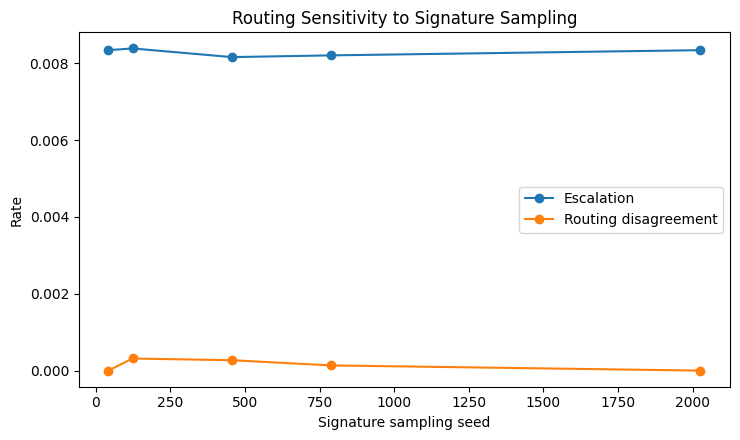


[Reviewer 3] Exact plotted values: R3_signature_routing_sensitivity
 Signature_Seed  Escalation_Rate  Routing_Agreement_vs_Seed42  Routing_Disagreement_vs_Seed42
             42     0.0083408476                            1                               0
            123     0.0083859333                    0.9996844                   0.00031559964
            456      0.008160505                   0.99972949                   0.00027051398
            789     0.0082055906                   0.99986474                   0.00013525699
           2026     0.0083408476                            1                               0
Saved numerical table: /content/drive/MyDrive/UNSW_NB15_IDS_XAI_BCCC_Method_Replication2/reviewer_strict_revision_1_7/tables/R3_signature_routing_sensitivity_numeric_table.csv


In [30]:
# BLOCK R3C: SIGNATURE-INDUCED ROUTING STABILITY WITH FROZEN POLICY
# Reports variation in similarity, routing agreement, ANMR, FBR, escalation across signature seeds.

sig_route_records=[]
reference_actions=None
for seed in CONFIG['signature_stability_seeds']:
    bank=signature_banks[SELECTED_SIGNATURE_SAMPLE_SIZE][seed]
    Xp=transform_features(policy_dev_df)
    yp=encode_active_labels(policy_dev_df['label'],zero_day_value=None)
    res=evaluate_final_policy(lgb_model,calibrators,bank,Xp,yp,f'PolicyDev | signature-seed={seed}',return_decisions=True)
    log=res.pop('_Decision_Log')
    if reference_actions is None: reference_actions=log['Action'].to_numpy(copy=True)
    agreement=float(np.mean(log['Action'].to_numpy()==reference_actions))
    sim_mean=float(np.nanmean(log['Similarity'])) if np.any(np.isfinite(log['Similarity'])) else np.nan
    sig_route_records.append({'Signature_Seed':seed,'Mean_Verified_Similarity':sim_mean,
                              'Routing_Agreement_vs_Seed42':agreement,
                              'ANMR':res['ANMR'],'FBR':res['FBR'],'Escalation_Rate':res['Escalation_Rate'],
                              'Attribution_Fraction':res['Attribution_Fraction']})

signature_routing_stability_df=pd.DataFrame(sig_route_records)
print('\n[Reviewer 3] Routing stability across signature seeds')
print(signature_routing_stability_df.to_string(index=False))
signature_routing_stability_df.to_csv(os.path.join(REV_TABLE_DIR,'R3_signature_routing_stability.csv'),index=False)

plt.figure(figsize=(7.5,4.5))
plt.plot(signature_routing_stability_df['Signature_Seed'],signature_routing_stability_df['Escalation_Rate'],marker='o',label='Escalation')
plt.plot(signature_routing_stability_df['Signature_Seed'],1-signature_routing_stability_df['Routing_Agreement_vs_Seed42'],marker='o',label='Routing disagreement')
plt.xlabel('Signature sampling seed'); plt.ylabel('Rate'); plt.title('Routing Sensitivity to Signature Sampling')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(REV_FIG_DIR,'R3_signature_routing_sensitivity.png'),dpi=220)
plt.show()


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_numeric_df = signature_routing_stability_df[["Signature_Seed", "Escalation_Rate", "Routing_Agreement_vs_Seed42"]].copy()
_figure_numeric_df["Routing_Disagreement_vs_Seed42"] = 1.0 - _figure_numeric_df["Routing_Agreement_vs_Seed42"]
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R3_signature_routing_sensitivity_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R3_signature_routing_sensitivity")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)


## Post-Freeze Signature Operational Sensitivity Diagnostic
This diagnostic is intentionally executed only after the development-selected routing policy has been frozen. It does not select the signature sample size or tune policy thresholds.



[Reviewer 3] Operational sensitivity to canonical signature sample size

[Evaluation] PolicyDev | signature-size=20
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold                = 0.05
High-confidence benign probability threshold = 0.9975
High-confidence benign similarity floor      = 0.0
Benign direct probability threshold         = 0.9987585843957376
Benign direct margin threshold              = 0.9982905381963332
Attack direct probability threshold         = 0.8456990805916857
Attack direct margin threshold              = 0.7172917009752988
Similarity metric                           = Spearman

[Evaluation] PolicyDev | signature-size=40
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability

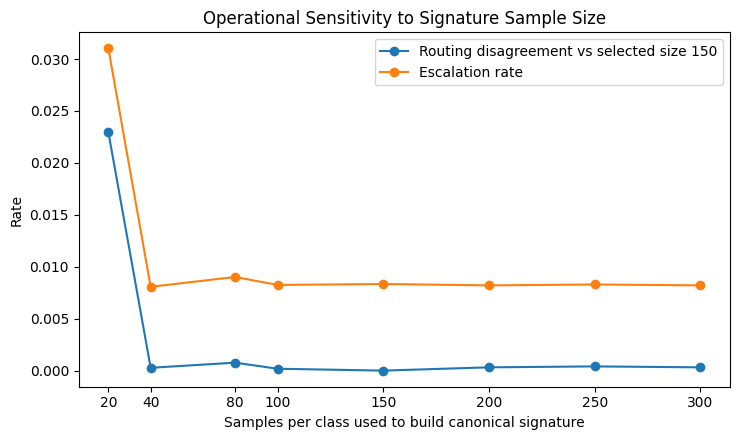


DIAGNOSTIC AUDIT
Dataset used             : policy_dev_df
Model retrained          : NO
Calibrators retrained    : NO
Thresholds retuned       : NO
Similarity reselected    : NO
Similarity metric        : Spearman
Signature seed fixed     : 42
Signature sizes compared : [20, 40, 80, 100, 150, 200, 250, 300]

[Reviewer 3] Exact plotted values: R3_signature_sample_size_operational_sensitivity
 Signature_Sample_Size  Routing_Disagreement_vs_SelectedSize  Escalation_Rate  ANMR          FBR
                    20                           0.022948602      0.031018936     1 0.0040799463
                    40                         0.00027051398     0.0080703336     1 0.0040799463
                    80                         0.00076645627     0.0090171326     1 0.0040799463
                   100                         0.00018034265     0.0082506763     1 0.0040799463
                   150                                     0     0.0083408476     1 0.0040799463
                   200 

In [31]:
# ======================================================================================
# R3B-DIAGNOSTIC: OPERATIONAL SENSITIVITY TO SIGNATURE SAMPLE SIZE
# ======================================================================================
# Purpose:
# Determine whether increasing the number of samples used to construct each
# canonical SHAP signature materially changes downstream routing behavior.
#
# IMPORTANT:
# - Development data only (policy_dev_df)
# - No threshold tuning
# - Same trained model
# - Same calibrators
# - Same frozen routing policy
# - Same similarity metric
# - Same reference signature seed
# - ONLY signature sample size changes: 20, 40, 80, 100, 150, 200, 250, 300
# ======================================================================================

print("\n" + "=" * 100)
print("[Reviewer 3] Operational sensitivity to canonical signature sample size")
print("=" * 100)

SIGNATURE_SAMPLE_SIZES_TO_COMPARE = [20, 40, 80, 100, 150, 200, 250, 300]

Xp = transform_features(policy_dev_df)
yp = encode_active_labels(
    policy_dev_df["label"],
    zero_day_value=None
)

sample_size_records = []
sample_size_decisions = {}

# Use exactly the same signature sampling seed for every sample size.
comparison_seed = int(CONFIG["signature_stability_seeds"][0])

for sample_size in SIGNATURE_SAMPLE_SIZES_TO_COMPARE:

    if sample_size not in signature_banks:
        raise KeyError(
            f"Signature bank for sample size {sample_size} was not constructed."
        )

    if comparison_seed not in signature_banks[sample_size]:
        raise KeyError(
            f"Signature bank for sample size {sample_size}, "
            f"seed {comparison_seed} was not constructed."
        )

    bank = signature_banks[sample_size][comparison_seed]

    res = evaluate_final_policy(
        lgb_model,
        calibrators,
        bank,
        Xp,
        yp,
        f"PolicyDev | signature-size={sample_size}",
        return_decisions=True
    )

    log = res.pop("_Decision_Log")

    actions = log["Action"].to_numpy(copy=True)
    sample_size_decisions[sample_size] = actions

    similarity = log["Similarity"].to_numpy(dtype=float)

    finite_similarity = np.isfinite(similarity)

    mean_similarity = (
        float(np.mean(similarity[finite_similarity]))
        if np.any(finite_similarity)
        else np.nan
    )

    sample_size_records.append({
        "Signature_Sample_Size": sample_size,
        "Signature_Seed": comparison_seed,
        "Mean_Verified_Similarity": mean_similarity,
        "ANMR": res["ANMR"],
        "FBR": res["FBR"],
        "Escalation_Rate": res["Escalation_Rate"],
        "Attribution_Fraction": res["Attribution_Fraction"]
    })


# ----------------------------------------------------------------------
# Routing agreement relative to the selected 150-sample signature
# ----------------------------------------------------------------------

reference_size = SELECTED_SIGNATURE_SAMPLE_SIZE
reference_actions = sample_size_decisions[reference_size]

for record in sample_size_records:

    sample_size = record["Signature_Sample_Size"]

    actions = sample_size_decisions[sample_size]

    agreement = float(
        np.mean(actions == reference_actions)
    )

    record["Routing_Agreement_vs_SelectedSize"] = agreement
    record["Routing_Disagreement_vs_SelectedSize"] = 1.0 - agreement


signature_sample_size_operational_df = pd.DataFrame(
    sample_size_records
)

# Reorder for readability
signature_sample_size_operational_df = (
    signature_sample_size_operational_df[
        [
            "Signature_Sample_Size",
            "Signature_Seed",
            "Mean_Verified_Similarity",
            "Routing_Agreement_vs_SelectedSize",
            "Routing_Disagreement_vs_SelectedSize",
            "ANMR",
            "FBR",
            "Escalation_Rate",
            "Attribution_Fraction"
        ]
    ]
    .sort_values("Signature_Sample_Size")
    .reset_index(drop=True)
)


print("\nOperational results:")
print(
    signature_sample_size_operational_df.to_string(
        index=False
    )
)


# ----------------------------------------------------------------------
# Pairwise routing agreement between ALL sample sizes
# ----------------------------------------------------------------------

agreement_matrix = pd.DataFrame(
    index=SIGNATURE_SAMPLE_SIZES_TO_COMPARE,
    columns=SIGNATURE_SAMPLE_SIZES_TO_COMPARE,
    dtype=float
)

for size_a in SIGNATURE_SAMPLE_SIZES_TO_COMPARE:
    for size_b in SIGNATURE_SAMPLE_SIZES_TO_COMPARE:

        agreement_matrix.loc[size_a, size_b] = float(
            np.mean(
                sample_size_decisions[size_a] == sample_size_decisions[size_b]


            )
        )

agreement_matrix.index.name = "Signature_Sample_Size"
agreement_matrix.columns.name = "Compared_With"


print("\nPairwise routing agreement:")
print(agreement_matrix.to_string())


# ----------------------------------------------------------------------
# Save
# ----------------------------------------------------------------------

signature_sample_size_operational_df.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R3_signature_sample_size_operational_sensitivity.csv"
    ),
    index=False
)

agreement_matrix.to_csv(
    os.path.join(
        REV_TABLE_DIR,
        "R3_signature_sample_size_pairwise_routing_agreement.csv"
    )
)


# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------

plt.figure(figsize=(7.5, 4.5))

plt.plot(
    signature_sample_size_operational_df["Signature_Sample_Size"],
    signature_sample_size_operational_df["Routing_Disagreement_vs_SelectedSize"],
    marker="o",
    label=f"Routing disagreement vs selected size {SELECTED_SIGNATURE_SAMPLE_SIZE}"
)

plt.plot(
    signature_sample_size_operational_df["Signature_Sample_Size"],
    signature_sample_size_operational_df["Escalation_Rate"],
    marker="o",
    label="Escalation rate"
)

plt.xlabel("Samples per class used to build canonical signature")
plt.ylabel("Rate")
plt.title("Operational Sensitivity to Signature Sample Size")
plt.xticks(SIGNATURE_SAMPLE_SIZES_TO_COMPARE)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        REV_FIG_DIR,
        "R3_signature_sample_size_operational_sensitivity.png"
    ),
    dpi=220
)

plt.show()


# ----------------------------------------------------------------------
# Simple audit
# ----------------------------------------------------------------------

print("\n" + "=" * 100)
print("DIAGNOSTIC AUDIT")
print("=" * 100)

print("Dataset used             : policy_dev_df")
print("Model retrained          : NO")
print("Calibrators retrained    : NO")
print("Thresholds retuned       : NO")
print("Similarity reselected    : NO")
print("Similarity metric        :", SELECTED_SIMILARITY_METRIC)
print("Signature seed fixed     :", comparison_seed)
print(
    "Signature sizes compared :",
    SIGNATURE_SAMPLE_SIZES_TO_COMPARE
)
print("=" * 100)


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_numeric_df = signature_sample_size_operational_df[["Signature_Sample_Size", "Routing_Disagreement_vs_SelectedSize", "Escalation_Rate"]].copy()
# Include other plotted series if present in the saved source dataframe.
for _metric in ["ANMR", "FBR"]:
    if _metric in signature_sample_size_operational_df.columns:
        _figure_numeric_df[_metric] = signature_sample_size_operational_df[_metric].values
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R3_signature_sample_size_operational_sensitivity_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R3_signature_sample_size_operational_sensitivity")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)


### Signature-bank sanity checks

Signature variability and stability are audited in the preceding R3 blocks; no duplicate standalone sanity-check cell is retained.


# Stage 8 — Four-Family LOAFO Simulated Zero-Day Evaluation

Four heterogeneous UNSW-NB15 attack families are evaluated by leave-one-attack-family-out retraining. Each held-out family is absent from its corresponding local training/development process.


In [32]:
# =============================================================================
# BLOCK R6: MULTI-FAMILY LOAFO ZERO-DAY EVALUATION
#
# FINAL ZERO-DAY FAMILIES (evaluated independently by LOAFO):
#   1. Port_Scan
#   2. DoS_GoldenEye
#   3. DoS_Slowhttptest
#   4. FTP-Patator
#
# PRIMARY SYSTEM ONLY:
#   - Each held-out attack family is excluded completely from its local
#     training/development data.
#   - Each LOAFO run rebuilds its local known-class LightGBM model.
#   - Probability calibration is rebuilt locally.
#   - SHAP signatures are rebuilt locally from local Train only.
#   - SELECTED_SIGNATURE_SAMPLE_SIZE remains globally frozen.
#   - SELECTED_SIMILARITY_METRIC remains globally frozen.
#   - The automatically selected GLOBAL FINAL_* routing thresholds remain
#     unchanged.
#   - No LOAFO-family-specific similarity selection or threshold tuning occurs.
#   - Final evaluation uses ALL held-out-family attack rows plus the SAME fixed
#     benign safety subset.
#
# PRIMARY ACTIONS:
#   BLOCK / ESCALATE / ALLOW
#
# FINAL REVIEW OUTPUT:
#   Holdout_Family
#   ANMR
#   FBR
#   Attack_Escalation_Rate
#   Attack_Block_Rate
#   Attack_Allow_Rate
#   Attribution_Fraction
#
# IMPORTANT:
#   There is NO secondary resolver, no Traffic+Confidence/OOD meta-model,
#   no pseudo-zero-day secondary training, and no secondary threshold search.
# =============================================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.calibration import IsotonicRegression


# =============================================================================
# 0. FINAL ZERO-DAY DESIGN
# =============================================================================

R6_FINAL_ZERO_DAY_FAMILIES = [
    "Exploits",
    "Fuzzers",
    "DoS",
    "Reconnaissance",
]

# Keep CONFIG synchronized so later cells see the same final design.
CONFIG["loafo_families"] = list(R6_FINAL_ZERO_DAY_FAMILIES)

_all_attack_classes_r6 = [
    str(x)
    for x in sorted(df_clean["label"].dropna().unique())
    if str(x) != "Benign"
]

missing_final = [
    x
    for x in R6_FINAL_ZERO_DAY_FAMILIES
    if x not in set(_all_attack_classes_r6)
]

if missing_final:
    raise RuntimeError(
        f"Requested final zero-day classes are absent: {missing_final}"
    )

print("\n" + "=" * 120)
print("[R6] FINAL PRIMARY LOAFO DESIGN")
print("=" * 120)

print("\nFINAL zero-day families — evaluation only:")
for _fam in R6_FINAL_ZERO_DAY_FAMILIES:
    print("  ", _fam)

print("\nPrimary policy thresholds:")
print("  FINAL_TAU_P                            =", float(FINAL_TAU_P))
print("  FINAL_TAU_S                            =", float(FINAL_TAU_S))
print("  FINAL_BENIGN_PROB_TAU                  =", float(FINAL_BENIGN_PROB_TAU))
print("  FINAL_BENIGN_SIM_TAU                   =", float(FINAL_BENIGN_SIM_TAU))
print(
    "  FINAL_HIGH_CONF_BENIGN_PROB_TAU        =",
    float(FINAL_HIGH_CONF_BENIGN_PROB_TAU),
)
print(
    "  FINAL_HIGH_CONF_BENIGN_SIM_FLOOR       =",
    float(FINAL_HIGH_CONF_BENIGN_SIM_FLOOR),
)
print(
    "  FINAL_BENIGN_DIRECT_PROB               =",
    float(FINAL_BENIGN_DIRECT_PROB),
)
print(
    "  FINAL_BENIGN_DIRECT_MARGIN             =",
    float(FINAL_BENIGN_DIRECT_MARGIN),
)
print(
    "  FINAL_ATTACK_DIRECT_PROB               =",
    float(FINAL_ATTACK_DIRECT_PROB),
)
print(
    "  FINAL_ATTACK_DIRECT_MARGIN             =",
    float(FINAL_ATTACK_DIRECT_MARGIN),
)

print("\nPASS: Primary thresholds remain automatically selected/frozen FINAL_* values.")
print("PASS: No manually chosen R6 routing threshold is introduced.")


# =============================================================================
# 1. GENERIC LIGHTGBM PREDICTED-CLASS SHAP CONTRIBUTIONS
# =============================================================================

def generic_pred_contrib(model, X, pred_idx, class_count):
    X = np.asarray(X, dtype=np.float32)
    pred_idx = np.asarray(pred_idx, dtype=int)

    nf = X.shape[1]

    raw = np.asarray(
        model.predict(
            X,
            pred_contrib=True,
        )
    )

    if (
        raw.ndim == 2
        and raw.shape[1] == class_count * (nf + 1)
    ):
        raw = raw.reshape(
            len(X),
            class_count,
            nf + 1,
        )

    if (
        raw.ndim == 3
        and raw.shape[1] == class_count
    ):
        return raw[
            np.arange(len(X)),
            pred_idx,
            :-1,
        ]

    if (
        raw.ndim == 3
        and raw.shape[2] == class_count
    ):
        return raw[
            np.arange(len(X)),
            :-1,
            pred_idx,
        ]

    raise ValueError(
        f"Unexpected contribution shape {raw.shape}"
    )


# =============================================================================
# 2. FIXED FINAL BENIGN SAFETY SUBSET
# =============================================================================

_LOAFO_BENIGN_POOL_POS = np.flatnonzero(
    df_clean["label"].eq("Benign").to_numpy()
)

_LOAFO_BENIGN_TARGET = int(
    np.sum(
        hard_test_df["label"].to_numpy()
        == "Benign"
    )
)

_LOAFO_BENIGN_TARGET = max(
    1,
    min(
        _LOAFO_BENIGN_TARGET,
        len(_LOAFO_BENIGN_POOL_POS),
    ),
)

_LOAFO_BENIGN_RNG = np.random.default_rng(
    RANDOM_STATE
)

LOAFO_BENIGN_TEST_INDICES = np.sort(
    _LOAFO_BENIGN_RNG.choice(
        _LOAFO_BENIGN_POOL_POS,
        size=_LOAFO_BENIGN_TARGET,
        replace=False,
    )
)

print("\n[Reviewer 6] Fixed FINAL LOAFO benign safety subset")
print("Benign evaluation rows :", len(LOAFO_BENIGN_TEST_INDICES))
print("Selection seed         :", RANDOM_STATE)
print("Shared by final families: YES")
print("Excluded from final LOAFO training: YES")


# =============================================================================
# 3. LOCAL LOAFO PROBABILITY CALIBRATION
# =============================================================================

def _loafo_calibrated_probabilities(
    model,
    calibrators,
    X,
    class_count,
):
    X = np.asarray(
        X,
        dtype=np.float32,
    )

    raw = np.asarray(
        model.predict(X),
        dtype=float,
    )

    calibrated = np.zeros_like(
        raw,
        dtype=float,
    )

    for class_idx in range(class_count):
        calibrated[:, class_idx] = calibrators[
            class_idx
        ].transform(
            raw[:, class_idx]
        )

    row_sum = calibrated.sum(
        axis=1,
        keepdims=True,
    )

    row_sum[
        row_sum <= 1e-12
    ] = 1.0

    return calibrated / row_sum


# =============================================================================
# 4. LOCAL LOAFO SHAP SIMILARITY
# =============================================================================

def _loafo_similarity(
    model,
    bank,
    X,
    pred,
    pred_names,
    class_count,
):
    X = np.asarray(
        X,
        dtype=np.float32,
    )

    pred = np.asarray(
        pred,
        dtype=int,
    )

    pred_names = np.asarray(
        pred_names,
        dtype=object,
    )

    if len(X) == 0:
        return np.zeros(
            0,
            dtype=float,
        )

    attrs = generic_pred_contrib(
        model,
        X,
        pred,
        class_count,
    )

    normalized = _row_l2_normalize(
        attrs
    )

    similarities = np.zeros(
        len(X),
        dtype=float,
    )

    for class_name in np.unique(pred_names):
        mask = (
            pred_names
            == class_name
        )

        similarities[mask] = _similarity_scores_from_normalized(
            normalized[mask],
            bank[class_name],
            SELECTED_SIMILARITY_METRIC,
        )

    return similarities


# =============================================================================
# 5. PRIMARY GLOBAL-FROZEN SELECTIVE SHAP EVALUATOR
# =============================================================================

def evaluate_loafo_selective(
    artifact,
    tag=None,
    return_decisions=False,
):
    """
    Primary LOAFO evaluator.

    Uses:
      - local LOAFO model
      - local probability calibration
      - local SHAP signatures
      - GLOBAL SELECTED_SIMILARITY_METRIC
      - automatically selected GLOBAL FINAL_* policy thresholds
    """

    model = artifact["Model"]
    calibrators = artifact["Calibrators"]
    bank = artifact["Signatures"]
    names = artifact["Names"]
    benign_index = int(artifact["Benign_Index"])
    class_count = int(artifact["Class_Count"])

    X = np.asarray(
        artifact["X_Eval"],
        dtype=np.float32,
    )

    true_names = np.asarray(
        artifact["True_Names"],
        dtype=object,
    )

    tag = (
        tag
        or f"Zero-Day LOAFO: {artifact['Holdout_Family']}"
    )

    total_start = time.perf_counter()

    probability_start = time.perf_counter()

    probs = _loafo_calibrated_probabilities(
        model,
        calibrators,
        X,
        class_count,
    )

    probability_time = (
        time.perf_counter()
        - probability_start
    )

    pred = np.argmax(
        probs,
        axis=1,
    )

    pred_names = np.asarray(
        [
            names[idx]
            for idx in pred
        ],
        dtype=object,
    )

    benign_probability = probs[
        :,
        benign_index,
    ]

    attack_confidence = (
        1.0
        - benign_probability
    )

    sorted_probs = np.sort(
        probs,
        axis=1,
    )

    margin = (
        sorted_probs[:, -1]
        - sorted_probs[:, -2]
    )

    max_probability = sorted_probs[
        :,
        -1,
    ]

    direct_allow = (
        (pred_names == "Benign")
        & (
            benign_probability
            >= float(FINAL_BENIGN_DIRECT_PROB)
        )
        & (
            margin
            >= float(FINAL_BENIGN_DIRECT_MARGIN)
        )
    )

    direct_block = (
        (pred_names != "Benign")
        & (
            attack_confidence
            >= float(FINAL_TAU_P)
        )
        & (
            max_probability
            >= float(FINAL_ATTACK_DIRECT_PROB)
        )
        & (
            margin
            >= float(FINAL_ATTACK_DIRECT_MARGIN)
        )
    )

    unresolved = ~(
        direct_allow
        | direct_block
    )

    actions = np.full(
        len(X),
        "ESCALATE",
        dtype=object,
    )

    actions[direct_allow] = "ALLOW"
    actions[direct_block] = "BLOCK"

    similarities = np.full(
        len(X),
        np.nan,
        dtype=float,
    )

    attribution_time = 0.0

    if np.any(unresolved):
        attribution_start = time.perf_counter()

        unresolved_similarity = _loafo_similarity(
            model,
            bank,
            X[unresolved],
            pred[unresolved],
            pred_names[unresolved],
            class_count,
        )

        attribution_time = (
            time.perf_counter()
            - attribution_start
        )

        similarities[
            unresolved
        ] = unresolved_similarity

        routed = route_policy_batch(
            pred_names[unresolved],
            attack_confidence[unresolved],
            unresolved_similarity,
            float(FINAL_TAU_P),
            float(FINAL_TAU_S),
            float(FINAL_BENIGN_PROB_TAU),
            float(FINAL_BENIGN_SIM_TAU),
            float(FINAL_HIGH_CONF_BENIGN_PROB_TAU),
            float(FINAL_HIGH_CONF_BENIGN_SIM_FLOOR),
        )

        actions[unresolved] = np.asarray(
            routed["actions"],
            dtype=object,
        )

    total_time = (
        time.perf_counter()
        - total_start
    )

    true_benign = (
        true_names
        == "Benign"
    )

    true_malicious = ~true_benign

    attack_rows = max(
        int(np.sum(true_malicious)),
        1,
    )

    benign_rows = max(
        int(np.sum(true_benign)),
        1,
    )

    attack_block_rate = float(
        np.sum(
            true_malicious
            & (actions == "BLOCK")
        )
        / attack_rows
    )

    attack_escalation_rate = float(
        np.sum(
            true_malicious
            & (actions == "ESCALATE")
        )
        / attack_rows
    )

    attack_allow_rate = float(
        np.sum(
            true_malicious
            & (actions == "ALLOW")
        )
        / attack_rows
    )

    if not np.isclose(
        attack_block_rate
        + attack_escalation_rate
        + attack_allow_rate,
        1.0,
        atol=1e-10,
    ):
        raise RuntimeError(
            "Primary attack BLOCK/ESCALATE/ALLOW rates do not sum to 1."
        )

    result = {
        "Environment": tag,

        "ANMR": float(
            1.0
            - attack_allow_rate
        ),

        "FBR": float(
            np.sum(
                true_benign
                & (actions == "BLOCK")
            )
            / benign_rows
        ),

        "Attack_Block_Rate": attack_block_rate,
        "Attack_Escalation_Rate": attack_escalation_rate,
        "Attack_Allow_Rate": attack_allow_rate,

        "Overall_Escalation_Rate": float(
            np.mean(
                actions == "ESCALATE"
            )
        ),

        "Attribution_Fraction": float(
            np.mean(unresolved)
        ),

        "Probability_Latency_ms_per_flow": float(
            1000.0
            * probability_time
            / max(len(X), 1)
        ),

        "Attribution_Latency_ms_per_flow": float(
            1000.0
            * attribution_time
            / max(len(X), 1)
        ),

        "End_to_End_Latency_ms_per_flow": float(
            1000.0
            * total_time
            / max(len(X), 1)
        ),

        "Throughput_flows_per_sec": float(
            len(X)
            / max(total_time, 1e-12)
        ),

        "Allow_Count": int(
            np.sum(
                actions == "ALLOW"
            )
        ),

        "Block_Count": int(
            np.sum(
                actions == "BLOCK"
            )
        ),

        "Escalate_Count": int(
            np.sum(
                actions == "ESCALATE"
            )
        ),

        "Attack_Rows": int(
            np.sum(true_malicious)
        ),

        "Benign_Rows": int(
            np.sum(true_benign)
        ),

        "Evaluation_Rows": int(
            len(X)
        ),

        "Attribution_Count": int(
            np.sum(unresolved)
        ),
    }

    if return_decisions:
        result["Actions"] = actions
        result["Predicted_Names"] = pred_names
        result["Predicted_Indices"] = pred
        result["Probabilities"] = probs
        result["Similarities"] = similarities
        result["Unresolved"] = unresolved

    return result


# =============================================================================
# 6. LOCAL LOAFO ARTIFACT BUILDER
#
# Builds one local zero-day experiment.
#
# The held-out attack family and fixed benign evaluation rows are excluded
# from local model development. Optional exclusion arguments are retained
# only as generic safeguards; this final R6 block does not use a secondary
# resolver or pseudo-zero-day development stage.
# =============================================================================

def _build_local_loafo_artifact(
    full_frame,
    holdout_name,
    benign_eval_indices,
    seed=42,
    permanently_excluded_attacks=None,
    extra_excluded_row_indices=None,
):
    frame = (
        full_frame
        .copy()
        .reset_index(drop=True)
    )

    frame["_LOAFO_ROW_ID"] = np.arange(
        len(frame),
        dtype=np.int64,
    )

    permanently_excluded_attacks = set(
        permanently_excluded_attacks
        or []
    )

    # Holdout itself is evaluated, not trained.
    permanently_excluded_attacks.discard(
        holdout_name
    )

    benign_eval_indices = np.asarray(
        benign_eval_indices,
        dtype=np.int64,
    )

    if extra_excluded_row_indices is None:
        extra_excluded_row_indices = np.zeros(
            0,
            dtype=np.int64,
        )
    else:
        extra_excluded_row_indices = np.asarray(
            extra_excluded_row_indices,
            dtype=np.int64,
        )

    benign_eval = frame[
        frame["_LOAFO_ROW_ID"].isin(
            benign_eval_indices
        )
    ].copy()

    hold = frame[
        frame["label"]
        == holdout_name
    ].copy()

    excluded_training_rows = np.union1d(
        benign_eval_indices,
        extra_excluded_row_indices,
    )

    known_mask = (
        frame["label"].ne(holdout_name)
        & (
            ~frame["_LOAFO_ROW_ID"].isin(
                excluded_training_rows
            )
        )
    )

    if permanently_excluded_attacks:
        known_mask &= (
            ~frame["label"].isin(
                permanently_excluded_attacks
            )
        )

    known = (
        frame[
            known_mask
        ]
        .copy()
        .reset_index(drop=True)
    )

    if len(hold) == 0:
        raise ValueError(
            f"LOAFO holdout family is empty: {holdout_name}"
        )

    if len(benign_eval) == 0:
        raise ValueError(
            "LOAFO benign evaluation subset is empty."
        )

    forbidden = (
        set(permanently_excluded_attacks)
        | {holdout_name}
    )

    leaked = forbidden.intersection(
        set(
            known["label"].unique()
        )
    )

    if leaked:
        raise RuntimeError(
            f"LOAFO leakage into known-class development: {sorted(leaked)}"
        )

    names = [
        "Benign"
    ] + sorted(
        [
            label
            for label in known[
                "label"
            ].unique()
            if label != "Benign"
        ]
    )

    cmap = {
        name: idx
        for idx, name in enumerate(names)
    }

    benign_index = cmap["Benign"]
    class_count = len(names)

    train_local, dev_local = train_test_split(
        known,
        test_size=0.28,
        random_state=seed,
        stratify=known["label"],
    )

    early_local, remaining_dev = train_test_split(
        dev_local,
        test_size=0.75,
        random_state=seed,
        stratify=dev_local["label"],
    )

    calibration_local, _unused_local = train_test_split(
        remaining_dev,
        test_size=0.50,
        random_state=seed + 1,
        stratify=remaining_dev["label"],
    )

    for split_name, split_frame in {
        "Train": train_local,
        "EarlyStopping": early_local,
        "Calibration": calibration_local,
    }.items():
        leaked_here = forbidden.intersection(
            set(
                split_frame[
                    "label"
                ].unique()
            )
        )

        if leaked_here:
            raise RuntimeError(
                f"LOAFO leakage in {split_name}: {sorted(leaked_here)}"
            )

    local_preprocessor = fit_feature_preprocessor(
        train_local,
        expected_features,
    )

    X_train_local = transform_features(
        train_local,
        local_preprocessor,
    )

    y_train_local = (
        train_local[
            "label"
        ]
        .map(cmap)
        .astype(int)
        .to_numpy()
    )

    X_early_local = transform_features(
        early_local,
        local_preprocessor,
    )

    y_early_local = (
        early_local[
            "label"
        ]
        .map(cmap)
        .astype(int)
        .to_numpy()
    )

    train_ds = lgb.Dataset(
        X_train_local,
        label=y_train_local,
    )

    early_ds = lgb.Dataset(
        X_early_local,
        label=y_early_local,
        reference=train_ds,
    )

    local_params = {
        "objective": "multiclass",
        "num_class": class_count,
        "metric": "multi_logloss",
        "learning_rate": 0.05,
        "num_leaves": 32,
        "feature_fraction": 0.90,
        "bagging_fraction": 0.90,
        "bagging_freq": 1,
        "seed": seed,
        "bagging_seed": seed,
        "feature_fraction_seed": seed,
        "data_random_seed": seed,
        "verbose": -1,
        "deterministic": True,
        "force_col_wise": True,
        "num_threads": 1,
        "num_threads": max(
            1,
            (os.cpu_count() or 2) - 1,
        ),
    }

    model = lgb.train(
        local_params,
        train_ds,
        num_boost_round=160,
        valid_sets=[early_ds],
        callbacks=[
            lgb.early_stopping(
                12,
                verbose=False,
            )
        ],
    )

    X_cal_local = transform_features(
        calibration_local,
        local_preprocessor,
    )

    y_cal_local = (
        calibration_local[
            "label"
        ]
        .map(cmap)
        .astype(int)
        .to_numpy()
    )

    raw_cal = np.asarray(
        model.predict(
            X_cal_local
        ),
        dtype=float,
    )

    calibrators = {}

    for class_idx in range(class_count):
        target = (
            y_cal_local
            == class_idx
        ).astype(int)

        iso = IsotonicRegression(
            out_of_bounds="clip"
        )

        if len(
            np.unique(target)
        ) < 2:
            iso.fit(
                np.append(
                    raw_cal[:, class_idx],
                    [0.0, 1.0],
                ),
                np.append(
                    target,
                    [0, 1],
                ),
            )
        else:
            iso.fit(
                raw_cal[:, class_idx],
                target,
            )

        calibrators[class_idx] = iso

    # -------------------------------------------------------------------------
    # Local Train-only SHAP signatures.
    # -------------------------------------------------------------------------

    bank = {}

    for class_idx, class_name in enumerate(names):
        rows = np.where(
            y_train_local
            == class_idx
        )[0]

        if len(rows) == 0:
            raise RuntimeError(
                f"No local training rows for class {class_name}."
            )

        rng = np.random.default_rng(
            seed + class_idx
        )

        take = rng.choice(
            rows,
            size=min(
                len(rows),
                int(SELECTED_SIGNATURE_SAMPLE_SIZE),
            ),
            replace=False,
        )

        attrs = generic_pred_contrib(
            model,
            X_train_local[take],
            np.full(
                len(take),
                class_idx,
                dtype=int,
            ),
            class_count,
        )

        normalized = _row_l2_normalize(
            attrs
        )

        signature = np.mean(
            normalized,
            axis=0,
        )

        signature = (
            signature
            / (
                np.linalg.norm(signature)
                + 1e-12
            )
        )

        bank[class_name] = signature.astype(
            np.float32
        )

    X_attack = transform_features(
        hold,
        local_preprocessor,
    )

    X_benign = transform_features(
        benign_eval,
        local_preprocessor,
    )

    X_eval = np.vstack(
        [
            X_attack,
            X_benign,
        ]
    ).astype(
        np.float32,
        copy=False,
    )

    true_names = np.concatenate(
        [
            np.full(
                len(X_attack),
                holdout_name,
                dtype=object,
            ),
            np.full(
                len(X_benign),
                "Benign",
                dtype=object,
            ),
        ]
    )

    # Robust known-class centers for OOD.
    local_class_med = {}
    local_class_iqr = {}

    for class_idx in range(class_count):
        class_rows = X_train_local[
            y_train_local == class_idx
        ].astype(float)

        local_class_med[
            class_idx
        ] = np.nanmedian(
            class_rows,
            axis=0,
        )

        q1 = np.nanquantile(
            class_rows,
            0.25,
            axis=0,
        )

        q3 = np.nanquantile(
            class_rows,
            0.75,
            axis=0,
        )

        local_class_iqr[
            class_idx
        ] = np.maximum(
            q3 - q1,
            1e-6,
        )

    return {
        "Holdout_Family": holdout_name,
        "Seed": int(seed),
        "Model": model,
        "Calibrators": calibrators,
        "Signatures": bank,
        "Names": names,
        "Class_Map": cmap,
        "Benign_Index": benign_index,
        "Class_Count": class_count,
        "Preprocessor": local_preprocessor,
        "Class_Median": local_class_med,
        "Class_IQR": local_class_iqr,
        "Train_Rows": int(len(train_local)),
        "EarlyStopping_Rows": int(len(early_local)),
        "Calibration_Rows": int(len(calibration_local)),
        "X_Eval": X_eval,
        "True_Names": true_names,
    }



[R6] FINAL PRIMARY LOAFO DESIGN

FINAL zero-day families — evaluation only:
   Exploits
   Fuzzers
   DoS
   Reconnaissance

Primary policy thresholds:
  FINAL_TAU_P                            = 0.7085714285714285
  FINAL_TAU_S                            = 0.01
  FINAL_BENIGN_PROB_TAU                  = 0.9
  FINAL_BENIGN_SIM_TAU                   = 0.05
  FINAL_HIGH_CONF_BENIGN_PROB_TAU        = 0.9975
  FINAL_HIGH_CONF_BENIGN_SIM_FLOOR       = 0.0
  FINAL_BENIGN_DIRECT_PROB               = 0.9987585843957376
  FINAL_BENIGN_DIRECT_MARGIN             = 0.9982905381963332
  FINAL_ATTACK_DIRECT_PROB               = 0.8456990805916857
  FINAL_ATTACK_DIRECT_MARGIN             = 0.7172917009752988

PASS: Primary thresholds remain automatically selected/frozen FINAL_* values.
PASS: No manually chosen R6 routing threshold is introduced.

[Reviewer 6] Fixed FINAL LOAFO benign safety subset
Benign evaluation rows : 2317
Selection seed         : 42
Shared by final families: YES
Excluded from fi

# Stage 9 — Constrained Adversarial Robustness


## Stage 9A — Frozen Constrained Adversarial Matrix Generation

The adversarial threat model is retained from the submitted study: malicious Hard-Test flows are moved **toward the benign training median** under a per-feature **epsilon × training-IQR** budget. Protocol/flag semantics are immutable, benign rows are untouched, and candidate changes are accepted only when they introduce **no new source-relative consistency violation**. The attack recipe is fixed before test evaluation and never uses routing thresholds.


In [33]:
# BLOCK R5A: CONSTRAINED SCORE-BASED TABULAR EVASION GENERATOR
# Reviewer 5 + submitted-experiment compatibility.
#
# IMPORTANT DESIGN RULES
# - Preserve the submitted threat model: malicious flows move TOWARD the benign
#   training median under an epsilon × training-IQR budget.
# - Protocol/flag variables are immutable.
# - Benign Time-Test rows are never modified.
# - No policy threshold is read or tuned by the attack.
# - No candidate may introduce a NEW violation of the exact R5 consistency rules.
# - epsilon=0 is an exact identity copy of Time-Test.
# - This remains constrained tabular feature-space evasion; packet-level
#   realizability is not claimed.

import numpy as np
import pandas as pd

X_time = transform_features(time_test_df)
y_time = encode_active_labels(time_test_df['label'], None)

# Training-only attack statistics, matching the submitted score-based design.
_adv_train = pd.DataFrame(
    X_train.astype(float),
    columns=expected_features,
    index=train_df.index,
)
ADV_Q1 = _adv_train.quantile(0.25).fillna(0.0).to_numpy(float)
ADV_Q3 = _adv_train.quantile(0.75).fillna(0.0).to_numpy(float)
ADV_SCALE = np.maximum(ADV_Q3 - ADV_Q1, 1e-6)
ADV_TRAIN_MEDIAN = _adv_train.median().fillna(0.0).to_numpy(float)
_adv_benign = _adv_train.loc[train_df['label'].astype(str).eq('Benign')]
ADV_BENIGN_MEDIAN = (_adv_benign.median()
                     .fillna(pd.Series(ADV_TRAIN_MEDIAN, index=expected_features))
                     .to_numpy(float))
_adv_index = {n:i for i,n in enumerate(expected_features)}

# Submitted-study immutability principle: protocol/flag semantics are never modified.
ADV_IMMUTABLE_MASK = np.array([
    ('protocol' in str(n).lower()) or ('flag' in str(n).lower())
    for n in expected_features
], dtype=bool)
ADV_MUTABLE_IDX = np.where(~ADV_IMMUTABLE_MASK)[0]

# Count-like variables remain discrete.
ADV_DISCRETE_MASK = np.array([
    any(tok in str(n).lower() for tok in ('count','packets','bytes','header','win','bulk','subflow'))
    for n in expected_features
], dtype=bool)
# Features that are nonnegative in training remain nonnegative after modification.
ADV_NONNEGATIVE_MASK = (_adv_train.min().fillna(0.0).to_numpy(float) >= 0.0)

# Exact same consistency rules used by the downstream Reviewer-5 audit.
def tabular_consistency_rule_matrix(
    X,
    feature_names
):

    X = np.asarray(
        X,
        dtype=float
    )

    idx = {
        name: i
        for i, name
        in enumerate(feature_names)
    }

    rules = {}


    # -------------------------------------------------------------------------
    # Finite-value rule
    # -------------------------------------------------------------------------

    rules["Finite"] = np.all(
        np.isfinite(X),
        axis=1
    )


    # -------------------------------------------------------------------------
    # Equality helper
    # -------------------------------------------------------------------------

    def eq(
        a,
        b,
        tol=1e-5
    ):

        return np.isclose(
            a,
            b,
            rtol=tol,
            atol=tol,
            equal_nan=False
        )


    # -------------------------------------------------------------------------
    # Packet total
    # -------------------------------------------------------------------------

    required = [
        "fwd_packets_count",
        "bwd_packets_count",
        "packets_count"
    ]

    if all(
        name in idx
        for name in required
    ):

        rules["PacketTotal"] = eq(

            X[
                :,
                idx[
                    "packets_count"
                ]
            ],

            X[
                :,
                idx[
                    "fwd_packets_count"
                ]
            ]
            +
            X[
                :,
                idx[
                    "bwd_packets_count"
                ]
            ]
        )


    # -------------------------------------------------------------------------
    # Payload-byte total
    # -------------------------------------------------------------------------

    required = [
        "fwd_total_payload_bytes",
        "bwd_total_payload_bytes",
        "total_payload_bytes"
    ]

    if all(
        name in idx
        for name in required
    ):

        rules["ByteTotal"] = eq(

            X[
                :,
                idx[
                    "total_payload_bytes"
                ]
            ],

            X[
                :,
                idx[
                    "fwd_total_payload_bytes"
                ]
            ]
            +
            X[
                :,
                idx[
                    "bwd_total_payload_bytes"
                ]
            ]
        )


    # -------------------------------------------------------------------------
    # Subflow relationships
    # -------------------------------------------------------------------------

    subflow_pairs = [

        (
            "subflow_fwd_packets",
            "fwd_packets_count"
        ),

        (
            "subflow_bwd_packets",
            "bwd_packets_count"
        ),

        (
            "subflow_fwd_bytes",
            "fwd_total_payload_bytes"
        ),

        (
            "subflow_bwd_bytes",
            "bwd_total_payload_bytes"
        )
    ]


    for derived_name, source_name in subflow_pairs:

        if (
            derived_name in idx
            and
            source_name in idx
        ):

            rules[
                f"{derived_name}={source_name}"
            ] = eq(

                X[
                    :,
                    idx[
                        derived_name
                    ]
                ],

                X[
                    :,
                    idx[
                        source_name
                    ]
                ]
            )


    # -------------------------------------------------------------------------
    # Average segment-size relationships
    # -------------------------------------------------------------------------

    avg_relations = [

        (
            "fwd_avg_segment_size",
            "fwd_total_payload_bytes",
            "fwd_packets_count"
        ),

        (
            "bwd_avg_segment_size",
            "bwd_total_payload_bytes",
            "bwd_packets_count"
        )
    ]


    for avg_name, byte_name, packet_name in avg_relations:

        if all(
            name in idx
            for name in [
                avg_name,
                byte_name,
                packet_name
            ]
        ):

            target = (

                X[
                    :,
                    idx[
                        byte_name
                    ]
                ]
                /
                np.maximum(
                    X[
                        :,
                        idx[
                            packet_name
                        ]
                    ],
                    1
                )
            )

            rules[
                avg_name
            ] = eq(

                X[
                    :,
                    idx[
                        avg_name
                    ]
                ],

                target,

                tol=1e-4
            )


    # -------------------------------------------------------------------------
    # Down/up packet ratio
    # -------------------------------------------------------------------------

    required = [
        "down_up_rate",
        "fwd_packets_count",
        "bwd_packets_count"
    ]

    if all(
        name in idx
        for name in required
    ):

        target = (

            X[
                :,
                idx[
                    "bwd_packets_count"
                ]
            ]
            /
            np.maximum(
                X[
                    :,
                    idx[
                        "fwd_packets_count"
                    ]
                ],
                1
            )
        )

        rules[
            "DownUpRatio"
        ] = eq(

            X[
                :,
                idx[
                    "down_up_rate"
                ]
            ],

            target,

            tol=1e-4
        )


    # -------------------------------------------------------------------------
    # Min <= mean <= max ordering
    # -------------------------------------------------------------------------

    prefixes = [

        "packet_iat",

        "packets_iat",

        "fwd_packets_iat",

        "bwd_packets_iat",

        "payload_bytes",

        "header_bytes"
    ]


    for prefix in prefixes:

        mn = f"{prefix}_min"
        me = f"{prefix}_mean"
        mx = f"{prefix}_max"

        if all(
            name in idx
            for name in [
                mn,
                me,
                mx
            ]
        ):

            rules[
                f"{prefix}_order"
            ] = (

                (
                    X[
                        :,
                        idx[mn]
                    ] <= X[


                        :,
                        idx[me]
                    ]
                    +
                    1e-9
                )

                &

                (
                    X[
                        :,
                        idx[me]
                    ] <= X[


                        :,
                        idx[mx]
                    ]
                    +
                    1e-9
                )
            )


    # -------------------------------------------------------------------------
    # Convert to DataFrame
    # -------------------------------------------------------------------------

    rule_df = pd.DataFrame(
        rules
    )

    assert len(rule_df) == len(X)

    return rule_df

def _no_new_violation_mask(X_source_rows, X_candidate_rows):
    src = tabular_consistency_rule_matrix(X_source_rows, expected_features).to_numpy(dtype=bool)
    adv = tabular_consistency_rule_matrix(X_candidate_rows, expected_features).to_numpy(dtype=bool)
    return ~np.any(src & (~adv), axis=1)

def _apply_budgeted_candidate(base, feature_mask, epsilon):
    """
    Move selected coordinates toward the benign median while strictly
    preserving the source-relative epsilon × training-IQR budget.

    The final budget is checked after float32 conversion. If float32
    representation causes any mutable coordinate to exceed its budget,
    that coordinate is reverted to its original source value.
    """
    base64 = np.asarray(base, dtype=np.float64)
    candidate = base64.copy()

    # Per-feature source-relative perturbation budget.
    step_cap = float(epsilon) * ADV_SCALE[None, :]

    # Move only toward the benign training median.
    delta_to_target = ADV_BENIGN_MEDIAN[None, :] - base64
    bounded_delta = (
        np.sign(delta_to_target)
        * np.minimum(np.abs(delta_to_target), step_cap)
    )

    effective = (
        np.asarray(feature_mask, dtype=bool)
        & (~ADV_IMMUTABLE_MASK[None, :])
    )
    candidate[effective] = base64[effective] + bounded_delta[effective]

    # Features that are nonnegative in training remain nonnegative.
    nonneg_effective = effective & ADV_NONNEGATIVE_MASK[None, :]
    candidate[nonneg_effective] = np.maximum(
        candidate[nonneg_effective], 0.0
    )

    # Preserve discreteness without allowing rounding to exceed the budget.
    disc_effective = effective & ADV_DISCRETE_MASK[None, :]
    if np.any(disc_effective):
        rounded = np.rint(candidate)
        rounded_delta = np.abs(rounded - base64)
        within_rounding_budget = rounded_delta <= (step_cap + 1e-9)

        use_rounded = disc_effective & within_rounding_budget
        candidate[use_rounded] = rounded[use_rounded]

        # If rounding would exceed the budget, keep the source value.
        revert_rounding = disc_effective & (~within_rounding_budget)
        candidate[revert_rounding] = base64[revert_rounding]

    # Protocol/flag variables are immutable.
    candidate[:, ADV_IMMUTABLE_MASK] = base64[:, ADV_IMMUTABLE_MASK]

    # Convert to the representation actually supplied to the model.
    base32 = np.asarray(base, dtype=np.float32)
    candidate32 = candidate.astype(np.float32)

    # Re-audit the REALIZED float32 perturbation. Float32 rounding can
    # otherwise create a tiny source-relative budget excess.
    realized_delta = np.abs(
        candidate32.astype(np.float64) - base32.astype(np.float64)
    )
    realized_budget = float(epsilon) * ADV_SCALE[None, :] + 1e-6

    budget_violation = (
        (realized_delta > realized_budget)
        & (~ADV_IMMUTABLE_MASK[None, :])
    )

    # Never relax the budget: revert offending coordinates to source.
    if np.any(budget_violation):
        candidate32[budget_violation] = base32[budget_violation]

    # Restore immutable coordinates exactly after float32 conversion.
    candidate32[:, ADV_IMMUTABLE_MASK] = base32[:, ADV_IMMUTABLE_MASK]

    # Internal hard check before returning the candidate.
    final_delta = np.abs(
        candidate32.astype(np.float64) - base32.astype(np.float64)
    )
    final_caps = float(epsilon) * ADV_SCALE[None, :] + 1e-6

    if np.any(
        final_delta[:, ADV_MUTABLE_IDX]
        > final_caps[:, ADV_MUTABLE_IDX]
    ):
        raise AssertionError(
            "Internal error: float32 adversarial candidate still exceeds "
            "epsilon × training-IQR budget."
        )

    return candidate32

def generate_constrained_adversarial_matrix(
    model, calibs, X_source, y_source, epsilon, seed, candidates=4
):
    """Constrained black-box attack matching the submitted benign-directed threat model.

    Candidate 0 modifies every mutable feature toward the benign median.
    Remaining candidates use random sparse subsets of mutable features.
    The highest-benign-probability candidate is retained only when it introduces
    no NEW R5 consistency violation relative to that source flow.
    """
    X_source = np.asarray(X_source, np.float32)
    y_source = np.asarray(y_source)
    malicious_idx = np.where(y_source != BENIGN_IDX)[0]

    if np.isclose(float(epsilon), 0.0):
        return X_source.copy(), {
            'epsilon': 0.0,
            'malicious_rows': int(len(malicious_idx)),
            'candidates_per_row': 0,
            'model_queries': 0,
            'mutable_feature_count': int(len(ADV_MUTABLE_IDX)),
            'accepted_candidate_rows': 0,
            'rejected_new_violation_rows': 0,
            'mean_changed_features_per_malicious_flow': 0.0,
            'max_changed_features_per_malicious_flow': 0
        }
    if len(malicious_idx) == 0:
        return X_source.copy(), {'epsilon':float(epsilon),'malicious_rows':0,'candidates_per_row':int(candidates),'model_queries':0}

    rng = np.random.default_rng(seed)
    base = X_source[malicious_idx].copy()
    out = X_source.copy()
    base_prob = get_calibrated_probabilities(model, calibs, base)[:, BENIGN_IDX]
    best = base.copy()
    best_prob = base_prob.copy()
    queries = int(len(base))
    accepted = 0
    rejected = 0

    for k in range(max(1, int(candidates))):
        if k == 0:
            mask = np.ones(base.shape, dtype=bool)
        else:
            mask = rng.random(base.shape) <= 0.50
        mask[:, ADV_IMMUTABLE_MASK] = False
        cand = _apply_budgeted_candidate(base, mask, float(epsilon))

        valid = _no_new_violation_mask(base, cand)
        rejected += int(np.sum(~valid))
        if not np.any(valid):
            continue

        score = get_calibrated_probabilities(model, calibs, cand)[:, BENIGN_IDX]
        queries += int(len(base))
        improve = valid & (score > best_prob)
        if np.any(improve):
            best[improve] = cand[improve]
            best_prob[improve] = score[improve]
            accepted += int(np.sum(improve))

    out[malicious_idx] = best

    # Hard source-relative epsilon audit on attacker-controlled coordinates.
    delta = np.abs(best.astype(np.float64) - base.astype(np.float64))
    caps = float(epsilon) * ADV_SCALE[None, :] + 1e-6
    if np.any(delta[:, ADV_MUTABLE_IDX] > caps[:, ADV_MUTABLE_IDX]):
        raise AssertionError('Adversarial mutable-feature delta exceeded epsilon × training-IQR budget.')

    if not np.all(_no_new_violation_mask(base, best)):
        raise AssertionError('Adversarial generator introduced a new R5 consistency violation.')

    return out, {
        'epsilon':float(epsilon), 'malicious_rows':int(len(malicious_idx)),
        'candidates_per_row':int(candidates), 'model_queries':int(queries),
        'mutable_feature_count':int(len(ADV_MUTABLE_IDX)),
        'accepted_candidate_rows':int(accepted),
        'rejected_new_violation_rows':int(rejected),
        'mean_changed_features_per_malicious_flow':float(np.mean(np.sum(delta > 0, axis=1))),
        'max_changed_features_per_malicious_flow':int(np.max(np.sum(delta > 0, axis=1)))
    }


# Stage 11 — Explainability and Technical Consistency Diagnostics


In [34]:
# BLOCK R7A: TECHNICAL CONSISTENCY AUDIT — L2 SIGNATURES AND VARIANCE
# Reviewer comment 7.

signature_audit=[]
for name,v in train_signatures.items():
    v=np.asarray(v,float)
    signature_audit.append({'Class':name,'L2_Norm':float(np.linalg.norm(v)),'Max_Abs_Component':float(np.max(np.abs(v))),
                            'Components_Above_1':int(np.sum(np.abs(v)>1+1e-9))})
signature_normalization_audit_df=pd.DataFrame(signature_audit)
print('\n[Reviewer 7] Canonical L2 signature audit')
print(signature_normalization_audit_df.to_string(index=False))
assert (signature_normalization_audit_df['Components_Above_1']==0).all(), 'Normalized signature component > 1 detected.'
signature_normalization_audit_df.to_csv(os.path.join(REV_TABLE_DIR,'R7_L2_signature_normalization_audit.csv'),index=False)

# Correct terminology: variance = mean squared deviation; standard deviation = sqrt(variance).
_, signature_variance_bank = build_signature_bank(lgb_model,train_df,SELECTED_SIGNATURE_SAMPLE_SIZE,PRIMARY_SIGNATURE_SEED)
variance_summary=[]
for name,var in signature_variance_bank.items():
    var=np.asarray(var,float); std=np.sqrt(np.maximum(var,0))
    variance_summary.append({'Class':name,'Mean_Feature_Variance':float(np.mean(var)),'Mean_Feature_StdDev':float(np.mean(std)),
                             'Max_Feature_Variance':float(np.max(var))})
signature_variance_audit_df=pd.DataFrame(variance_summary)
print('\nVariance/std-dev audit (manuscript Eq. 7 must use the correct term/formula)')
print(signature_variance_audit_df.to_string(index=False))
signature_variance_audit_df.to_csv(os.path.join(REV_TABLE_DIR,'R7_variance_vs_stddev_audit.csv'),index=False)


# Rebuild Table-6-style class profiles with unambiguous quantities.
# Raw mean absolute SHAP may exceed 1; normalized canonical-signature components cannot.
profile_rows=[]
Xtr=transform_features(train_df); ytr=encode_active_labels(train_df['label'],None)
for ci in range(CLASS_COUNT):
    rows=np.where(ytr==ci)[0]; rng=np.random.default_rng(9000+ci); take=rng.choice(rows,min(len(rows),SELECTED_SIGNATURE_SAMPLE_SIZE),replace=False)
    A=fast_predicted_class_attributions(lgb_model,Xtr[take],np.full(len(take),ci,dtype=int),batch_size=CONFIG.get('attribution_batch_size',8192))
    raw_mean_abs=np.mean(np.abs(A),axis=0); sig=np.asarray(train_signatures[resolve_active_class_name(ci)],float)
    top=np.argsort(raw_mean_abs)[-15:][::-1]
    for rank,j in enumerate(top,1):
        profile_rows.append({'Class':resolve_active_class_name(ci),'Rank':rank,'Feature':expected_features[j],
                             'Raw_MeanAbs_SHAP':float(raw_mean_abs[j]),'Normalized_Signature_Component':float(sig[j])})
classwise_shap_profile_df=pd.DataFrame(profile_rows)
classwise_shap_profile_df.to_csv(os.path.join(REV_TABLE_DIR,'R7_classwise_SHAP_profile_raw_vs_normalized.csv'),index=False)
print('\nReviewer-safe Table 6 profile columns: Raw_MeanAbs_SHAP and Normalized_Signature_Component')
print(classwise_shap_profile_df.to_string(index=False))
print('\nComplete class-wise SHAP profile printed for all active classes (Top-15 features per class).')

print('\nTable 6 reporting rule: if values > 1 are shown, label them as raw/mean absolute local SHAP contributions; '
      'do not label those values as components of the L2-normalized canonical signature.')



[Reviewer 7] Canonical L2 signature audit
         Class  L2_Norm  Max_Abs_Component  Components_Above_1
        Benign      1.0           0.545943                   0
      Analysis      1.0           0.530118                   0
      Backdoor      1.0           0.735482                   0
           DoS      1.0           0.940471                   0
      Exploits      1.0           0.801004                   0
       Fuzzers      1.0           0.976755                   0
       Generic      1.0           0.721431                   0
Reconnaissance      1.0           0.883385                   0
     Shellcode      1.0           0.764083                   0
         Worms      1.0           0.518152                   0

Variance/std-dev audit (manuscript Eq. 7 must use the correct term/formula)
         Class  Mean_Feature_Variance  Mean_Feature_StdDev  Max_Feature_Variance
        Benign               0.019362             0.076885              0.213847
      Analysis           

[Reviewer 7] SHAP-LIME diagnostic N=120, mean=0.2167, approximate 95% CI=(0.1910,0.2423)


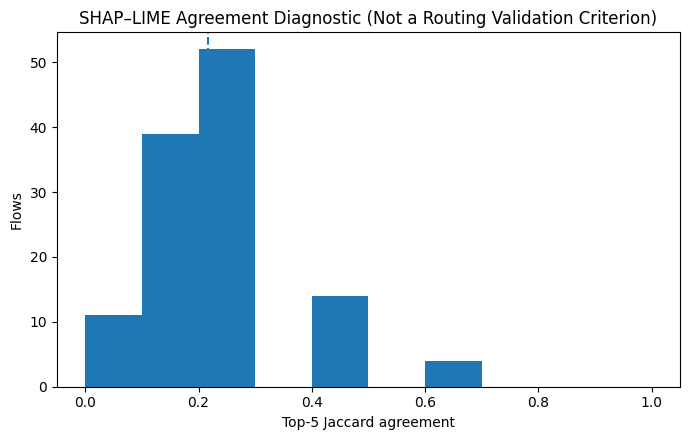

Note: bins are left-closed/right-open except the final bin, which includes 1.0.

[Reviewer 3] Exact plotted values: R7_SHAP_LIME_diagnostic_histogram
 Bin_Lower_Inclusive  Bin_Upper  Flow_Count    Fraction  Mean_Jaccard_Reference
                   0        0.1          11 0.091666667              0.21666667
                 0.1        0.2          39       0.325              0.21666667
                 0.2        0.3          52  0.43333333              0.21666667
                 0.3        0.4           0           0              0.21666667
                 0.4        0.5          14  0.11666667              0.21666667
                 0.5        0.6           0           0              0.21666667
                 0.6        0.7           4 0.033333333              0.21666667
                 0.7        0.8           0           0              0.21666667
                 0.8        0.9           0           0              0.21666667
                 0.9          1           0       

In [35]:
# BLOCK R7B: SHAP–LIME AGREEMENT DIAGNOSTIC
# Increase the sample count and report distribution/CI. This output is not used by the routing policy.

N_LIME=min(CONFIG['lime_diagnostic_rows'],len(similarity_dev_df))
idx=np.random.default_rng(42).choice(len(similarity_dev_df),N_LIME,replace=False)
X_lime=transform_features(similarity_dev_df)[idx]
explainer_lime=LimeTabularExplainer(transform_features(train_df),feature_names=expected_features,
                                    class_names=ACTIVE_CLASS_NAMES,mode='classification',discretize_continuous=True,random_state=42)
shap_pred=get_calibrated_probabilities(lgb_model,calibrators,X_lime).argmax(1)
A=fast_predicted_class_attributions(lgb_model,X_lime,shap_pred,batch_size=CONFIG.get('attribution_batch_size',8192))
agreements=[]
for i in range(N_LIME):
    shap_top=set(np.argsort(np.abs(A[i]))[-5:])
    exp=explainer_lime.explain_instance(X_lime[i],lambda z:get_calibrated_probabilities(lgb_model,calibrators,z),num_features=5,labels=[int(shap_pred[i])])
    lime_map=exp.as_map().get(int(shap_pred[i]),[]); lime_top=set([j for j,_ in lime_map[:5]])
    union=len(shap_top|lime_top); agreements.append(len(shap_top&lime_top)/union if union else 0.0)
ag=np.asarray(agreements,float); mean=float(np.mean(ag)); se=float(np.std(ag,ddof=1)/np.sqrt(len(ag))) if len(ag)>1 else 0
lime_diagnostic_df=pd.DataFrame({'Jaccard_Top5':ag})
print(f'[Reviewer 7] SHAP-LIME diagnostic N={len(ag)}, mean={mean:.4f}, approximate 95% CI=({mean-1.96*se:.4f},{mean+1.96*se:.4f})')
lime_diagnostic_df.to_csv(os.path.join(REV_TABLE_DIR,'R7_SHAP_LIME_diagnostic_distribution.csv'),index=False)
plt.figure(figsize=(7,4.5)); plt.hist(ag,bins=np.linspace(0,1,11)); plt.axvline(mean,linestyle='--'); plt.xlabel('Top-5 Jaccard agreement'); plt.ylabel('Flows');
plt.title('SHAP–LIME Agreement Diagnostic (Not a Routing Validation Criterion)'); plt.tight_layout(); plt.savefig(os.path.join(REV_FIG_DIR,'R7_SHAP_LIME_diagnostic_histogram.png'),dpi=220); plt.show()


# Reviewer 3: numerical values underlying the figure (reporting only)
_figure_hist_counts, _figure_hist_edges = np.histogram(ag, bins=np.linspace(0, 1, 11))
_figure_numeric_df = pd.DataFrame({
    "Bin_Lower_Inclusive": _figure_hist_edges[:-1],
    "Bin_Upper": _figure_hist_edges[1:],
    "Flow_Count": _figure_hist_counts,
})
_figure_numeric_df["Fraction"] = _figure_numeric_df["Flow_Count"] / len(ag) if len(ag) else np.nan
_figure_numeric_df["Mean_Jaccard_Reference"] = float(mean)
print("Note: bins are left-closed/right-open except the final bin, which includes 1.0.")
_figure_numeric_path = os.path.join(REV_TABLE_DIR, "R7_SHAP_LIME_diagnostic_histogram_numeric_table.csv")
_figure_numeric_df.to_csv(_figure_numeric_path, index=False, float_format="%.12g")
print("\n[Reviewer 3] Exact plotted values: R7_SHAP_LIME_diagnostic_histogram")
print(_figure_numeric_df.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
print("Saved numerical table:", _figure_numeric_path)


## Harmonized result experiments — M0 and M4 (Variant-B removed)

The upstream preprocessing, splits, SHAP signatures, development-only similarity selection, and SHAP–LIME diagnostics remain unchanged. **M0** uses UNSW original predictors and the canonical development-frozen policy. **M4** uses the original predictors plus the causal host-relative features and selects one reporting-seed canonical set of ten routing and direct-decision thresholds **only on PolicyOptimization** using the original R2B optimization procedure, freezing the entire vector across five model seeds. The latter is an explicitly distinct policy configuration, not a frozen-threshold transfer. All seeds use identical held-out partitions. The reporting seed is the corresponding row of the five-seed experiment. The four adversarial matrices are fixed transfer attacks generated using the reporting-seed M0 model, and applied identically to M0 and M4. LOAFO fits new family-specific models; it does not reuse the all-class M0 or M4 model, because that would leak the held-out family.

In [36]:
# H0 — shared evaluation, timing, and policy-isolation utilities (no result rows)
import os, copy, time, types, contextlib
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.calibration import IsotonicRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
H_SEEDS = [int(v) for v in CONFIG['multi_seed_values']]
H_REPORT_SEED = int(CONFIG.get('final_reporting_seed', RANDOM_STATE))
assert len(H_SEEDS) == len(set(H_SEEDS)) == 5 and H_REPORT_SEED in H_SEEDS
H_EPS = tuple(float(e) for e in CONFIG.get('adversarial_epsilons', [0.,.01,.025,.05,.10]) if float(e)>0)
assert len(H_EPS)==4, f'Expected exactly four nonzero adversarial budgets, got {H_EPS}'
H_M0_POLICY = dict(zip(
    ('TAU_P','TAU_S','BENIGN_PROB_TAU','BENIGN_SIM_TAU','HIGH_CONF_BENIGN_PROB_TAU',
     'HIGH_CONF_BENIGN_SIM_FLOOR','BENIGN_DIRECT_PROB','BENIGN_DIRECT_MARGIN',
     'ATTACK_DIRECT_PROB','ATTACK_DIRECT_MARGIN'),
    (FINAL_TAU_P,FINAL_TAU_S,FINAL_BENIGN_PROB_TAU,FINAL_BENIGN_SIM_TAU,
     FINAL_HIGH_CONF_BENIGN_PROB_TAU,FINAL_HIGH_CONF_BENIGN_SIM_FLOOR,
     FINAL_BENIGN_DIRECT_PROB,FINAL_BENIGN_DIRECT_MARGIN,
     FINAL_ATTACK_DIRECT_PROB,FINAL_ATTACK_DIRECT_MARGIN)))
H_POLICY_GLOBALS = {'FINAL_'+k:k for k in H_M0_POLICY}
@contextlib.contextmanager
def h_policy_scope(policy):
    previous = {g:globals()[g] for g in H_POLICY_GLOBALS}
    try:
        for g,k in H_POLICY_GLOBALS.items(): globals()[g]=float(policy[k])
        yield
    finally:
        globals().update(previous)
def h_fit(seed, representation):
    Xtr, Xes, Xcal = ((CHR_X_TRAIN_ORIG,CHR_X_EARLY_ORIG,CHR_X_CALIB_ORIG) if representation=='M0'
                      else (CHR_X_TRAIN_M4,CHR_X_EARLY_M4,CHR_X_CALIB_M4))
    names = list(expected_features) if representation=='M0' else CHR_M4_FEATURE_NAMES
    assert Xtr.shape[1] == len(names)
    p=copy.deepcopy(MAIN_PARAMS)
    p.update({k:int(seed) for k in ('seed','bagging_seed','feature_fraction_seed','data_random_seed')})
    p['verbose']=-1
    ds=lgb.Dataset(Xtr,label=CHR_Y_TRAIN,feature_name=names)
    es=lgb.Dataset(Xes,label=CHR_Y_EARLY,reference=ds,feature_name=names)
    model=lgb.train(p,ds,num_boost_round=200,valid_sets=[es],callbacks=[lgb.early_stopping(15,verbose=False)])
    raw=np.asarray(model.predict(Xcal),float)
    calibrators={}
    for c in range(CLASS_COUNT):
        y=(CHR_Y_CALIB==c).astype(int)
        if len(np.unique(y))!=2: raise RuntimeError(f'{representation} seed {seed}: calibration class {c} infeasible')
        calibrators[c]=IsotonicRegression(out_of_bounds='clip').fit(raw[:,c],y)
    signatures=chr_build_signature_bank(model,Xtr,CHR_Y_TRAIN,SELECTED_SIGNATURE_SAMPLE_SIZE,int(seed))
    return dict(Model=model,Calibrators=calibrators,Signatures=signatures,Seed=int(seed),
                Best_Iteration=int(model.best_iteration),Representation=representation)
def h_classifier(artifact,X,y):
    p=get_calibrated_probabilities(artifact['Model'],artifact['Calibrators'],X)
    pred=np.argmax(p,axis=1); attack=np.asarray(y)!=int(BENIGN_IDX)
    return dict(Accuracy=float(accuracy_score(y,pred)),
        Macro_Precision=float(precision_score(y,pred,average='macro',zero_division=0)),
        Macro_Recall=float(recall_score(y,pred,average='macro',zero_division=0)),
        Macro_F1=float(f1_score(y,pred,average='macro',zero_division=0)),
        Weighted_F1=float(f1_score(y,pred,average='weighted',zero_division=0)),
        Malicious_to_Benign_Rate=float(np.mean(pred[attack]==BENIGN_IDX)) if attack.any() else np.nan,
        Malicious_NonBenign_Rate=float(np.mean(pred[attack]!=BENIGN_IDX)) if attack.any() else np.nan)
def h_evaluate(artifact,policy,X,y,env,seed,kind='Clean'):
    X=np.asarray(X,np.float32);y=np.asarray(y,np.int32)
    if len(X)!=len(y):raise RuntimeError('Evaluation matrix/labels mismatch')
    with h_policy_scope(policy):
        r=evaluate_final_policy(artifact['Model'],artifact['Calibrators'],artifact['Signatures'],X,y,
                                f'{artifact["Representation"]} | {env} | seed {seed}')
    cl=h_classifier(artifact,X,y)
    out=dict(Model=artifact['Representation'],Seed=int(seed),Environment=env,Experiment=kind,
             Best_Iteration=artifact['Best_Iteration'],N=len(y),**cl)
    for k,old in [('ANMR','ANMR'),('FBR','FBR'),('Attack_Block_Rate','Attack_Block_Rate'),
                  ('Attack_Escalation_Rate','Attack_Escalation_Rate'),('Attack_Allow_Rate','Attack_Allow_Rate'),
                  ('Overall_Escalation_Rate','Escalation_Rate'),('Attribution_Fraction','Attribution_Fraction'),
                  ('Probability_Latency_ms_per_flow','Probability_Latency_ms_per_flow'),
                  ('Attribution_Latency_ms_per_flow','Attribution_Latency_ms_per_flow'),
                  ('Latency_ms_per_flow','End_to_End_Latency_ms_per_flow'),
                  ('Throughput_flows_per_sec','Throughput_flows_per_sec')]:out[k]=float(r[old])
    return out
def h_tables(rows,name):
    df=pd.DataFrame(rows)
    if df.empty:raise RuntimeError(f'{name} produced no results')
    keys=['Model','Environment','Experiment']
    if df.duplicated(['Model','Seed','Environment','Experiment']).any():raise RuntimeError(f'{name}: duplicate results')
    single=df[df.Seed==H_REPORT_SEED].copy()
    nums=[c for c in df.select_dtypes(include=np.number).columns if c not in ('Seed','N','Best_Iteration')]
    summary=df.groupby(keys,dropna=False)[nums].agg(['mean','std']).reset_index()
    os.makedirs(REV_TABLE_DIR,exist_ok=True)
    for label,table in [('five_seed',df),('single_seed',single),('mean_sd',summary)]:
        table.to_csv(os.path.join(REV_TABLE_DIR,f'H_{name}_{label}.csv'),index=False)
    print(f'{name}: {len(single)} reporting-seed rows; {len(df)} five-seed rows')
    display(single);display(summary)
    return df,single,summary
H_MATRICES={'M0':{'Host-Test':CHR_X_HOST_ORIG,'Time-Test':CHR_X_TIME_ORIG,'Hard-Test':CHR_X_HARD_ORIG},
            'M4':{'Host-Test':CHR_X_HOST_M4,'Time-Test':CHR_X_TIME_M4,'Hard-Test':CHR_X_HARD_M4}}
H_LABELS={'Host-Test':CHR_Y_HOST,'Time-Test':CHR_Y_TIME,'Hard-Test':CHR_Y_HARD}


In [37]:
# H1 — M0: fit, calibrate, canonical policy, Host/Time/Hard; seed 42 and five seeds
H_M0_ARTIFACTS={}
H_M0_ROWS=[]
for seed in H_SEEDS:
    art=h_fit(seed,'M0');H_M0_ARTIFACTS[seed]=art
    for env,X in H_MATRICES['M0'].items():
        H_M0_ROWS.append(h_evaluate(art,H_M0_POLICY,X,H_LABELS[env],env,seed))
H_M0_DF,H_M0_SINGLE,H_M0_SUMMARY=h_tables(H_M0_ROWS,'M0_shift')



[Evaluation] M0 | Host-Test | seed 42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold                = 0.05
High-confidence benign probability threshold = 0.9975
High-confidence benign similarity floor      = 0.0
Benign direct probability threshold         = 0.9987585843957376
Benign direct margin threshold              = 0.9982905381963332
Attack direct probability threshold         = 0.8456990805916857
Attack direct margin threshold              = 0.7172917009752988
Similarity metric                           = Spearman

[Evaluation] M0 | Time-Test | seed 42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold                = 0.05
Hi

,Model,Seed,Environment,Experiment,Best_Iteration,N,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,...,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M0,42,Host-Test,Clean,37,23948,0.747119,0.628940,0.489726,0.492539,...,0.422761,0.953922,0.046078,0.000000,0.084683,0.521547,0.004483,0.675240,0.680795,1468.871635
1,M0,42,Time-Test,Clean,37,88766,0.968558,0.616632,0.553337,0.531513,...,0.005162,0.971993,0.028007,0.000000,0.006624,0.062130,0.002819,0.082372,0.085983,11630.237116
2,M0,42,Hard-Test,Clean,37,23969,0.748508,0.609378,0.492547,0.495689,...,0.413466,0.952245,0.047617,0.000139,0.085986,0.517001,0.004254,0.665773,0.671100,1490.091870


Model Environment Experiment  Accuracy           Macro_Precision            \
                                    mean       std            mean       std   
0    M0   Hard-Test      Clean  0.750478  0.002564        0.597102  0.018191   
1    M0   Host-Test      Clean  0.750292  0.002267        0.613043  0.028049   
2    M0   Time-Test      Clean  0.968945  0.000310        0.610749  0.006326   

  Macro_Recall            Macro_F1  ... Attribution_Fraction            \
          mean       std      mean  ...                 mean       std   
0     0.483640  0.006293  0.490908  ...             0.517927  0.013972   
1     0.480429  0.006174  0.486849  ...             0.520620  0.014844   
2     0.555810  0.003136  0.531450  ...             0.234040  0.387270   

  Probability_Latency_ms_per_flow           Attribution_Latency_ms_per_flow  \
                             mean       std                            mean   
0                        0.005974  0.002742                        0.782894   
1                        0.006281  0.002829                        0.784528   
2                        0.004255  0.002336                        0.298961   

            Latency_ms_per_flow           Throughput_flows_per_sec  \
        std                mean       std                     mean   
0  0.189468            0.789921  0.192210              1314.839490   
1  0.185122            0.791866  0.187867              1309.557281   
2  0.451841            0.304054  0.451189              8256.307106   

                
           std  
0   252.667330  
1   247.714954  
2  4445.665832  

[3 rows x 39 columns]

In [38]:
# H2 — M4: fit, calibrate, development-only direct-gate selection, freeze, Host/Time/Hard
# Original SHAP fallback thresholds remain frozen; only four M4-specific direct gates are selected.
H_M4_DEV_X_ORIG=np.asarray(transform_features(policy_dev_df,PRIMARY_PREPROCESSOR),np.float32)
H_M4_DEV_REL,_=chr_build_causal_host_relative(policy_dev_df,H_M4_DEV_X_ORIG,
    history_frame=train_df,history_X=CHR_X_TRAIN_ORIG,tag='M4 PolicyOptimization')
H_M4_DEV_X=chr_append_relative(H_M4_DEV_X_ORIG,H_M4_DEV_REL)
H_M4_DEV_Y=np.asarray(encode_active_labels(policy_dev_df['label'],zero_day_value=None),np.int32)
H_M4_ARTIFACTS={};H_M4_POLICIES={};H_M4_DEV_AUDIT=[];H_M4_ROWS=[]
def h_select_m4_policy(art,seed):
    """Run the ORIGINAL two-step R2B optimizer on the M4 PolicyOptimization matrix.

    Only the feature matrix is adapted; the original 10-threshold optimization,
    development safety floors, candidate ranking and SHAP routing remain unchanged.
    The original policy_arrays function is restored before held-out evaluation.
    """
    model=art['Model'];calibs=art['Calibrators'];signatures=art['Signatures']
    probs=np.asarray(get_calibrated_probabilities(model,calibs,H_M4_DEV_X),float)
    pred=probs.argmax(axis=1)
    names=np.asarray([resolve_active_class_name(i) for i in pred],object)
    true_names=np.asarray([resolve_active_class_name(i) for i in H_M4_DEV_Y],object)
    sim,_=compute_similarity_metric(model,signatures,H_M4_DEV_X,pred,names,SELECTED_SIMILARITY_METRIC)
    # The existing optimizers invoke policy_arrays(). Override only its M4 data
    # adapter for these two calls, then restore the original function in finally.
    original_arrays=globals()['policy_arrays']
    def m4_policy_arrays(_model,_calibs,_signatures,_frame,_metric):
        if _model is not model or _metric!=SELECTED_SIMILARITY_METRIC:
            raise RuntimeError('M4 development optimizer received an inconsistent model or metric')
        return H_M4_DEV_X,H_M4_DEV_Y,probs,pred,names,true_names,sim
    try:
        globals()['policy_arrays']=m4_policy_arrays
        routing=tune_routing_policy(model,calibs,signatures,policy_dev_df,SELECTED_SIMILARITY_METRIC)
        selective=tune_selective_policy(model,calibs,signatures,policy_dev_df,
                                        SELECTED_SIMILARITY_METRIC,routing)
    finally:
        globals()['policy_arrays']=original_arrays
    keys=('TAU_P','TAU_S','BENIGN_PROB_TAU','BENIGN_SIM_TAU',
          'HIGH_CONF_BENIGN_PROB_TAU','HIGH_CONF_BENIGN_SIM_FLOOR')
    policy={k:float(v) for k,v in zip(keys,routing[:6])}
    policy.update(dict(zip(('BENIGN_DIRECT_PROB','BENIGN_DIRECT_MARGIN',
                            'ATTACK_DIRECT_PROB','ATTACK_DIRECT_MARGIN'),
                           map(float,selective[:4]))))

    m4_anmr = float(selective[4])
    m4_fbr = float(selective[5])

    m4_safety_feasible = (
        m4_anmr >= ANMR_SAFETY_FLOOR
        and m4_fbr <= FBR_SAFETY_CEILING
    )

    m4_selection_status = (
        "SAFETY_FEASIBLE"
        if m4_safety_feasible
        else "DEVELOPMENT_FALLBACK"
    )

    print(
        f"M4 seed {seed} policy selection: {m4_selection_status} | "
        f"ANMR={m4_anmr:.6f} | FBR={m4_fbr:.6f}"
    )

    audit = dict(
        Model='M4',
        Seed=seed,
        Dev_ANMR=m4_anmr,
        Dev_FBR=m4_fbr,
        Dev_Escalation=float(selective[6]),
        Dev_Attribution_Fraction=float(selective[7]),
        Dev_Attack_Block_Rate=float(selective[8]),
        Dev_Attack_Escalation_Rate=float(selective[9]),
        Dev_Attack_Allow_Rate=float(selective[10]),
        Safety_Feasible=m4_safety_feasible,
        Selection_Status=m4_selection_status,
        **policy
    )

    return policy, audit

# Select ONE M4 canonical policy on development data using the reporting-seed model.
# Freeze that exact policy vector for all five independently trained M4 models.
for seed in H_SEEDS:
    H_M4_ARTIFACTS[seed]=h_fit(seed,'M4')
H_M4_CANONICAL_POLICY,H_M4_CANONICAL_AUDIT=h_select_m4_policy(
    H_M4_ARTIFACTS[H_REPORT_SEED],H_REPORT_SEED)
H_M4_DEV_AUDIT.append(H_M4_CANONICAL_AUDIT)
for seed in H_SEEDS:
    H_M4_POLICIES[seed]=dict(H_M4_CANONICAL_POLICY)
    for env,X in H_MATRICES['M4'].items():
        H_M4_ROWS.append(h_evaluate(H_M4_ARTIFACTS[seed],H_M4_POLICIES[seed],
                                  X,H_LABELS[env],env,seed))
H_M4_DEV_AUDIT_DF=pd.DataFrame(H_M4_DEV_AUDIT)
H_M4_DEV_AUDIT_DF.to_csv(os.path.join(REV_TABLE_DIR,'H_M4_development_policy_selection.csv'),index=False)
H_M4_DF,H_M4_SINGLE,H_M4_SUMMARY=h_tables(H_M4_ROWS,'M4_shift')



[Reviewer R2] Escalation-aware routing-policy selection
Selection status       : SAFETY-FEASIBLE ESCALATION-AWARE ROUTING POLICY
ANMR                   : 1.0
FBR                    : 0.004183236068790993
Overall escalation     : 0.03854824165915239
Attack BLOCK rate      : 0.9534966276180333
Attack ESCALATION rate : 0.04650337238196663
Attack ALLOW rate      : 0.0

[Reviewer R2] Escalation-aware development-derived selective grids
Benign direct quantiles: [0.9, 0.95, 0.975, 0.99]
Attack direct quantiles: [0.5, 0.7, 0.8, 0.9, 0.95, 0.975, 0.99]
Benign direct prob     : [0.9986552405502108, 0.9987568205209663]
Benign direct margin   : [0.9982633997574107, 0.9983649398713921]
Attack direct prob     : [0.8098374427469895, 0.9812295300115511, 0.9908123097104521, 0.9933432845277488]
Attack direct margin   : [0.7055384157554769, 0.9741387947575928, 0.9864856184016728, 0.989005540927191]

[Reviewer R2] Escalation-aware selective-policy selection
Selection status       : SAFETY-FEASIBLE ESCALA

,Model,Seed,Environment,Experiment,Best_Iteration,N,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,...,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M4,42,Host-Test,Clean,57,23948,0.746826,0.586111,0.482141,0.477734,...,0.354825,0.938115,0.061839,0.000046,0.098255,0.511901,0.007272,0.925269,0.933560,1071.168338
1,M4,42,Time-Test,Clean,57,88766,0.968310,0.602164,0.561629,0.520241,...,0.004401,0.954533,0.045467,0.000000,0.009666,0.064428,0.005473,0.117731,0.124043,8061.742672
2,M4,42,Hard-Test,Clean,57,23969,0.748258,0.534643,0.475810,0.466637,...,0.357359,0.932939,0.065768,0.001293,0.101798,0.513663,0.007841,0.952375,0.961308,1040.249053


Model Environment Experiment  Accuracy           Macro_Precision            \
                                    mean       std            mean       std   
0    M4   Hard-Test      Clean  0.747198  0.002451        0.539628  0.007829   
1    M4   Host-Test      Clean  0.746927  0.002146        0.575967  0.018711   
2    M4   Time-Test      Clean  0.968143  0.000352        0.588778  0.010935   

  Macro_Recall            Macro_F1  ... Attribution_Fraction            \
          mean       std      mean  ...                 mean       std   
0     0.467443  0.009189  0.472039  ...             0.506362  0.007784   
1     0.477750  0.009967  0.481785  ...             0.504861  0.005686   
2     0.541183  0.020640  0.519628  ...             0.235144  0.385186   

  Probability_Latency_ms_per_flow           Attribution_Latency_ms_per_flow  \
                             mean       std                            mean   
0                        0.006474  0.001749                        0.819967   
1                        0.006350  0.001730                        0.805746   
2                        0.004480  0.001532                        0.431893   

            Latency_ms_per_flow           Throughput_flows_per_sec  \
        std                mean       std                     mean   
0  0.178407            0.827556  0.180059              1256.446273   
1  0.175151            0.813168  0.176825              1281.382533   
2  0.755536            0.437245  0.756562              8537.619520   

                
           std  
0   279.023192  
1   300.750887  
2  4987.822332  

[3 rows x 39 columns]

In [39]:
# H3 — M0 LOAFO: same original local model and frozen canonical policy; 4 families x 5 seeds
H_LOAFO_FAMILIES=list(R6_FINAL_ZERO_DAY_FAMILIES)
assert len(H_LOAFO_FAMILIES)==4
H_M0_LOAFO_ARTIFACTS={};H_M0_LOAFO_ROWS=[]
def h_loafo_record(model_name,seed,family,art,result):
    return dict(Model=model_name,Seed=int(seed),Environment=f'LOAFO: {family}',Experiment='LOAFO',
      N=int(result['Evaluation_Rows']),Best_Iteration=int(art['Model'].best_iteration),
      Accuracy=np.nan,Macro_Precision=np.nan,Macro_Recall=np.nan,Macro_F1=np.nan,Weighted_F1=np.nan,
      Malicious_to_Benign_Rate=np.nan,
      ANMR=float(result['ANMR']),FBR=float(result['FBR']),
      Attack_Block_Rate=float(result['Attack_Block_Rate']),
      Attack_Escalation_Rate=float(result['Attack_Escalation_Rate']),
      Attack_Allow_Rate=float(result['Attack_Allow_Rate']),
      Overall_Escalation_Rate=float(result['Overall_Escalation_Rate']),
      Attribution_Fraction=float(result['Attribution_Fraction']),
      Probability_Latency_ms_per_flow=float(result['Probability_Latency_ms_per_flow']),
      Attribution_Latency_ms_per_flow=float(result['Attribution_Latency_ms_per_flow']),
      Latency_ms_per_flow=float(result['End_to_End_Latency_ms_per_flow']),
      Throughput_flows_per_sec=float(result['Throughput_flows_per_sec']))
for seed in H_SEEDS:
    H_M0_LOAFO_ARTIFACTS[seed]={}
    for family in H_LOAFO_FAMILIES:
        art=_build_local_loafo_artifact(df_clean,family,LOAFO_BENIGN_TEST_INDICES,seed=seed)
        art['Representation']='M0';H_M0_LOAFO_ARTIFACTS[seed][family]=art
        with h_policy_scope(H_M0_POLICY):
            r=evaluate_loafo_selective(art,f'M0 LOAFO {family} seed={seed}')
        H_M0_LOAFO_ROWS.append(h_loafo_record('M0',seed,family,art,r))
H_M0_LOAFO_DF,H_M0_LOAFO_SINGLE,H_M0_LOAFO_SUMMARY=h_tables(H_M0_LOAFO_ROWS,'M0_LOAFO')


M0_LOAFO: 4 reporting-seed rows; 20 five-seed rows


,Model,Seed,Environment,Experiment,N,Best_Iteration,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,...,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M0,42,LOAFO: Exploits,LOAFO,29916,55,NaN,NaN,NaN,NaN,...,0.004316,0.954310,0.045473,0.000217,0.042653,0.516580,0.006147,0.864493,0.871146,1147.912841
1,M0,42,LOAFO: Fuzzers,LOAFO,24112,56,NaN,NaN,NaN,NaN,...,0.002590,0.214958,0.474145,0.310897,0.429247,0.984365,0.005862,1.597793,1.604245,623.346312
2,M0,42,LOAFO: DoS,LOAFO,7982,57,NaN,NaN,NaN,NaN,...,0.004748,0.980229,0.019771,0.000000,0.028815,0.740666,0.005907,1.183170,1.189755,840.509157
3,M0,42,LOAFO: Reconnaissance,LOAFO,15674,66,NaN,NaN,NaN,NaN,...,0.004748,0.990567,0.009358,0.000075,0.009315,0.888924,0.007610,1.674081,1.682334,594.412440


Model            Environment Experiment Accuracy     Macro_Precision      \
                                              mean std            mean std   
0    M0             LOAFO: DoS      LOAFO      NaN NaN             NaN NaN   
1    M0        LOAFO: Exploits      LOAFO      NaN NaN             NaN NaN   
2    M0         LOAFO: Fuzzers      LOAFO      NaN NaN             NaN NaN   
3    M0  LOAFO: Reconnaissance      LOAFO      NaN NaN             NaN NaN   

  Macro_Recall     Macro_F1  ... Attribution_Fraction            \
          mean std     mean  ...                 mean       std   
0          NaN NaN      NaN  ...             0.510298  0.128859   
1          NaN NaN      NaN  ...             0.523225  0.025801   
2          NaN NaN      NaN  ...             0.940677  0.054881   
3          NaN NaN      NaN  ...             0.811535  0.076681   

  Probability_Latency_ms_per_flow           Attribution_Latency_ms_per_flow  \
                             mean       std                            mean   
0                        0.007920  0.002198                        0.876171   
1                        0.005737  0.000776                        0.805616   
2                        0.006009  0.000441                        1.481150   
3                        0.006594  0.001247                        1.384379   

            Latency_ms_per_flow           Throughput_flows_per_sec              
        std                mean       std                     mean         std  
0  0.219069            0.884728  0.219332              1183.441136  270.058719  
1  0.075254            0.811880  0.076008              1241.071914  125.244913  
2  0.114209            1.487752  0.114277               675.433940   53.402439  
3  0.186087            1.391574  0.187027               728.494984   92.503509  

[4 rows x 37 columns]

In [40]:
# H4 — M4 LOAFO: same family/benign holdouts and seed splits, local M4 train-only statistics
# IMPORTANT: no held-out attack family contributes to local M4 training, calibration, or fallback statistics.
def h_local_m4_artifact(m0,seed,family):
    frame=df_clean.copy().reset_index(drop=True)
    frame['_LOAFO_ROW_ID']=np.arange(len(frame),dtype=np.int64)
    forbidden=(frame['label']==family)
    is_eval_benign=frame['_LOAFO_ROW_ID'].isin(LOAFO_BENIGN_TEST_INDICES)
    known=frame.loc[~forbidden&~is_eval_benign].copy().reset_index(drop=True)
    hold=frame.loc[forbidden].copy(); benign=frame.loc[is_eval_benign].copy()
    assert len(hold)>0 and len(benign)>0 and not (known['label']==family).any()
    tr,dev=train_test_split(known,test_size=.28,random_state=seed,stratify=known['label'])
    es,rest=train_test_split(dev,test_size=.75,random_state=seed,stratify=dev['label'])
    cal,_=train_test_split(rest,test_size=.50,random_state=seed+1,stratify=rest['label'])
    names=m0['Names'];cmap=m0['Class_Map'];nc=m0['Class_Count']
    pre=m0['Preprocessor']
    Xtr0=np.asarray(transform_features(tr,pre),np.float32)
    # Derive local Train-only global fallback statistics, never from the all-class M4 training set.
    vals=Xtr0[:,CHR_RELATIVE_COLS].astype(float)
    med=np.nanmedian(vals,axis=0)
    iq=np.nanquantile(vals,.75,axis=0)-np.nanquantile(vals,.25,axis=0)
    iq=np.where(np.isfinite(iq)&(np.abs(iq)>CHR_EPS),iq,1.)
    assert np.isfinite(med).all() and np.isfinite(iq).all()
    local_globals=dict(chr_build_causal_host_relative.__globals__)
    local_globals.update(CHR_GLOBAL_MEDIAN=med,CHR_GLOBAL_IQR=iq)
    local_builder=types.FunctionType(chr_build_causal_host_relative.__code__,local_globals,
                                     name='local_loafo_causal_builder',
                                     argdefs=chr_build_causal_host_relative.__defaults__)
    def m4(frame,tag,history=False):
        X=np.asarray(transform_features(frame,pre),np.float32)
        rel,_=local_builder(frame,X,history_frame=tr if history else None,
                            history_X=Xtr0 if history else None,tag=tag)
        return chr_append_relative(X,rel)
    Xtr=m4(tr,'LOAFO local train');Xes=m4(es,'LOAFO local early',True)
    Xcal=m4(cal,'LOAFO local calibration',True)
    # Attack and benign evaluation are combined into ONE target environment, allowing
    # only strictly earlier unlabeled within-evaluation host history; no train holdout leakage.
    ev=pd.concat([hold,benign],ignore_index=True)
    Xev=m4(ev,'LOAFO local evaluation',False)
    ytr=tr['label'].map(cmap).astype(int).to_numpy();y_es=es['label'].map(cmap).astype(int).to_numpy()
    ycal=cal['label'].map(cmap).astype(int).to_numpy()
    params=dict(objective='multiclass',num_class=nc,metric='multi_logloss',learning_rate=.05,
                num_leaves=32,feature_fraction=.90,bagging_fraction=.90,bagging_freq=1,
                seed=seed,bagging_seed=seed,feature_fraction_seed=seed,data_random_seed=seed,
                verbose=-1,deterministic=True,force_col_wise=True,
                num_threads=int(MAIN_PARAMS.get('num_threads',4)))
    ds=lgb.Dataset(Xtr,label=ytr,feature_name=CHR_M4_FEATURE_NAMES)
    esds=lgb.Dataset(Xes,label=y_es,reference=ds,feature_name=CHR_M4_FEATURE_NAMES)
    model=lgb.train(params,ds,num_boost_round=160,valid_sets=[esds],callbacks=[lgb.early_stopping(12,verbose=False)])
    raw=np.asarray(model.predict(Xcal),float);calibs={}
    for j in range(nc):
        target=(ycal==j).astype(int)
        iso=IsotonicRegression(out_of_bounds='clip')
        if np.unique(target).size<2:
            iso.fit(np.r_[raw[:,j],[0.,1.]],np.r_[target,[0,1]])
        else:iso.fit(raw[:,j],target)
        calibs[j]=iso
    signatures={}
    for j,name in enumerate(names):
        ix=np.where(ytr==j)[0]
        if not len(ix):raise RuntimeError(f'LOAFO {family} class {name} absent from train')
        rng=np.random.default_rng(seed+j)
        take=rng.choice(ix,size=min(len(ix),int(SELECTED_SIGNATURE_SAMPLE_SIZE)),replace=False)
        attrs=generic_pred_contrib(model,Xtr[take],np.full(len(take),j,int),nc)
        vec=np.mean(_row_l2_normalize(attrs),axis=0)
        signatures[name]=(vec/(np.linalg.norm(vec)+1e-12)).astype(np.float32)
    out=dict(m0,Model=model,Calibrators=calibs,Signatures=signatures,
             X_Eval=Xev,Representation='M4',Train_Rows=len(tr),EarlyStopping_Rows=len(es),Calibration_Rows=len(cal))
    assert not (tr['label']==family).any() and Xev.shape[1]==len(CHR_M4_FEATURE_NAMES)
    return out
H_M4_LOAFO_ARTIFACTS={};H_M4_LOAFO_ROWS=[]
for seed in H_SEEDS:
    H_M4_LOAFO_ARTIFACTS[seed]={}
    for family in H_LOAFO_FAMILIES:
        art=h_local_m4_artifact(H_M0_LOAFO_ARTIFACTS[seed][family],seed,family)
        H_M4_LOAFO_ARTIFACTS[seed][family]=art
        with h_policy_scope(H_M4_POLICIES[seed]):
            r=evaluate_loafo_selective(art,f'M4 LOAFO {family} seed={seed}')
        H_M4_LOAFO_ROWS.append(h_loafo_record('M4',seed,family,art,r))
H_M4_LOAFO_DF,H_M4_LOAFO_SINGLE,H_M4_LOAFO_SUMMARY=h_tables(H_M4_LOAFO_ROWS,'M4_LOAFO')


M4_LOAFO: 4 reporting-seed rows; 20 five-seed rows


,Model,Seed,Environment,Experiment,N,Best_Iteration,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,...,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M4,42,LOAFO: Exploits,LOAFO,29916,38,NaN,NaN,NaN,NaN,...,0.003884,0.909345,0.090511,0.000145,0.084336,0.733821,0.004528,0.938066,0.943127,1060.302105
1,M4,42,LOAFO: Fuzzers,LOAFO,24112,57,NaN,NaN,NaN,NaN,...,0.002590,0.198945,0.528791,0.272264,0.478683,0.980466,0.008343,1.610657,1.619520,617.466739
2,M4,42,LOAFO: DoS,LOAFO,7982,45,NaN,NaN,NaN,NaN,...,0.009063,0.974051,0.025772,0.000177,0.019795,0.723879,0.004204,1.051651,1.056448,946.567720
3,M4,42,LOAFO: Reconnaissance,LOAFO,15674,42,NaN,NaN,NaN,NaN,...,0.005179,0.981882,0.018043,0.000075,0.016652,0.774340,0.004223,1.053435,1.058240,944.964931


Model            Environment Experiment Accuracy     Macro_Precision      \
                                              mean std            mean std   
0    M4             LOAFO: DoS      LOAFO      NaN NaN             NaN NaN   
1    M4        LOAFO: Exploits      LOAFO      NaN NaN             NaN NaN   
2    M4         LOAFO: Fuzzers      LOAFO      NaN NaN             NaN NaN   
3    M4  LOAFO: Reconnaissance      LOAFO      NaN NaN             NaN NaN   

  Macro_Recall     Macro_F1  ... Attribution_Fraction            \
          mean std     mean  ...                 mean       std   
0          NaN NaN      NaN  ...             0.507467  0.121124   
1          NaN NaN      NaN  ...             0.714634  0.015837   
2          NaN NaN      NaN  ...             0.923308  0.052590   
3          NaN NaN      NaN  ...             0.765076  0.068160   

  Probability_Latency_ms_per_flow           Attribution_Latency_ms_per_flow  \
                             mean       std                            mean   
0                        0.006434  0.002233                        0.807625   
1                        0.004538  0.000230                        0.997316   
2                        0.006372  0.001566                        1.442100   
3                        0.006275  0.002957                        1.234362   

            Latency_ms_per_flow           Throughput_flows_per_sec              
        std                mean       std                     mean         std  
0  0.163614            0.814676  0.163378              1267.642139  255.616658  
1  0.045215            1.002416  0.045325               999.229883   45.370330  
2  0.130114            1.449056  0.131323               694.543805   61.288494  
3  0.219869            1.241258  0.222558               827.122606  150.498806  

[4 rows x 37 columns]

In [41]:
# H5 — prepare the FOUR constrained adversarial matrices once, without any test-driven tuning.
# The attacks are transferred unchanged to both architectures and all five seeds.
# Generator parameters and physical-consistency rules are the existing R5A definitions.
H_ADV_MATRICES={};H_ADV_GENERATION=[]
for eps in H_EPS:
    Xadv,audit=generate_constrained_adversarial_matrix(
        H_M0_ARTIFACTS[H_REPORT_SEED]['Model'],
        H_M0_ARTIFACTS[H_REPORT_SEED]['Calibrators'],
        CHR_X_TIME_ORIG,CHR_Y_TIME,eps,
        seed=int(RANDOM_STATE)+int(round(eps*10000)),
        candidates=int(CONFIG.get('adversarial_random_candidates',4)))
    assert Xadv.shape==CHR_X_TIME_ORIG.shape
    assert np.array_equal(Xadv[CHR_Y_TIME==BENIGN_IDX],CHR_X_TIME_ORIG[CHR_Y_TIME==BENIGN_IDX])
    H_ADV_MATRICES[eps]=np.asarray(Xadv,np.float32)
    H_ADV_GENERATION.append(audit)
H_ADV_GENERATION_DF=pd.DataFrame(H_ADV_GENERATION)
H_ADV_GENERATION_DF.to_csv(os.path.join(REV_TABLE_DIR,'H_adversarial_generation_audit.csv'),index=False)
display(H_ADV_GENERATION_DF)


,epsilon,malicious_rows,candidates_per_row,model_queries,mutable_feature_count,accepted_candidate_rows,rejected_new_violation_rows,mean_changed_features_per_malicious_flow,max_changed_features_per_malicious_flow
0,0.010,11283,4,56415,38,6258,0,7.517681,24
1,0.025,11283,4,56415,38,13120,0,14.184969,27
2,0.050,11283,4,56415,38,9982,0,10.494195,26
3,0.100,11283,4,56415,38,16630,0,14.844279,28


In [42]:
# H6 — M0: four identical transfer-attack budgets, reporting seed and five-seed results
H_M0_ADV_ROWS=[]
for seed in H_SEEDS:
    art=H_M0_ARTIFACTS[seed]
    for eps in H_EPS:
        H_M0_ADV_ROWS.append(h_evaluate(art,H_M0_POLICY,H_ADV_MATRICES[eps],CHR_Y_TIME,
              f'Adversarial Time-Test eps={eps:.3f}',seed,kind='Adversarial'))
H_M0_ADV_DF,H_M0_ADV_SINGLE,H_M0_ADV_SUMMARY=h_tables(H_M0_ADV_ROWS,'M0_adversarial')



[Evaluation] M0 | Adversarial Time-Test eps=0.010 | seed 42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold                = 0.05
High-confidence benign probability threshold = 0.9975
High-confidence benign similarity floor      = 0.0
Benign direct probability threshold         = 0.9987585843957376
Benign direct margin threshold              = 0.9982905381963332
Attack direct probability threshold         = 0.8456990805916857
Attack direct margin threshold              = 0.7172917009752988
Similarity metric                           = Spearman

[Evaluation] M0 | Adversarial Time-Test eps=0.025 | seed 42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign s

,Model,Seed,Environment,Experiment,Best_Iteration,N,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,...,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M0,42,Adversarial Time-Test eps=0.010,Adversarial,37,88766,0.955704,0.558053,0.444665,0.413729,...,0.005162,0.898165,0.101835,0.0,0.016008,0.072224,0.002909,0.097537,0.101250,9876.549563
1,M0,42,Adversarial Time-Test eps=0.025,Adversarial,37,88766,0.923484,0.476341,0.363871,0.345780,...,0.005162,0.636533,0.363467,0.0,0.049264,0.108059,0.002984,0.139498,0.143298,6978.482527
2,M0,42,Adversarial Time-Test eps=0.050,Adversarial,37,88766,0.947559,0.484107,0.401239,0.378273,...,0.005162,0.864221,0.135779,0.0,0.020323,0.076662,0.002766,0.097443,0.100985,9902.506082
3,M0,42,Adversarial Time-Test eps=0.100,Adversarial,37,88766,0.919451,0.509589,0.323544,0.285653,...,0.005162,0.828592,0.171408,0.0,0.024852,0.116509,0.003041,0.149607,0.153469,6515.964464


Model                      Environment   Experiment  Accuracy            \
                                                           mean       std   
0    M0  Adversarial Time-Test eps=0.010  Adversarial  0.960859  0.003158   
1    M0  Adversarial Time-Test eps=0.025  Adversarial  0.924002  0.002060   
2    M0  Adversarial Time-Test eps=0.050  Adversarial  0.949963  0.001399   
3    M0  Adversarial Time-Test eps=0.100  Adversarial  0.920895  0.005661   

  Macro_Precision           Macro_Recall            Macro_F1  ...  \
             mean       std         mean       std      mean  ...   
0        0.574627  0.013825     0.488975  0.026354  0.464800  ...   
1        0.504075  0.056047     0.370377  0.008357  0.346076  ...   
2        0.498873  0.015539     0.431517  0.019130  0.408620  ...   
3        0.468993  0.052420     0.335485  0.023265  0.305654  ...   

  Attribution_Fraction           Probability_Latency_ms_per_flow            \
                  mean       std                            mean       std   
0             0.244226  0.387824                        0.004141  0.002295   
1             0.279298  0.386740                        0.004454  0.002615   
2             0.249400  0.387584                        0.004256  0.002764   
3             0.286707  0.388338                        0.004477  0.002580   

  Attribution_Latency_ms_per_flow           Latency_ms_per_flow            \
                             mean       std                mean       std   
0                        0.317218  0.453019            0.322194  0.452430   
1                        0.366833  0.445297            0.372117  0.444733   
2                        0.320065  0.449438            0.325141  0.448839   
3                        0.378447  0.454388            0.383787  0.453795   

  Throughput_flows_per_sec               
                      mean          std  
0              7099.156628  3802.964191  
1              4957.773059  2534.037265  
2              6940.082628  3805.489044  
3              4741.616423  2397.529421  

[4 rows x 39 columns]

In [43]:
# H7 — M4: the EXACT SAME four transfer-attack budgets; causal host-relative features rebuilt
H_M4_ADV_MATRICES={}
for eps in H_EPS:
    H_M4_ADV_MATRICES[eps]=build_m4_time_matrix_from_original(
        H_ADV_MATRICES[eps],tag=f'Harmonized M4 adversarial eps={eps:.3f}')
H_M4_ADV_ROWS=[]
for seed in H_SEEDS:
    art=H_M4_ARTIFACTS[seed]
    for eps in H_EPS:
        H_M4_ADV_ROWS.append(h_evaluate(art,H_M4_POLICIES[seed],H_M4_ADV_MATRICES[eps],CHR_Y_TIME,
              f'Adversarial Time-Test eps={eps:.3f}',seed,kind='Adversarial'))
H_M4_ADV_DF,H_M4_ADV_SINGLE,H_M4_ADV_SUMMARY=h_tables(H_M4_ADV_ROWS,'M4_adversarial')



[Evaluation] M4 | Adversarial Time-Test eps=0.010 | seed 42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign similarity threshold                = 0.05
High-confidence benign probability threshold = 0.9975
High-confidence benign similarity floor      = 0.0
Benign direct probability threshold         = 0.9986552405502108
Benign direct margin threshold              = 0.9982633997574107
Attack direct probability threshold         = 0.8098374427469895
Attack direct margin threshold              = 0.7055384157554769
Similarity metric                           = Spearman

[Evaluation] M4 | Adversarial Time-Test eps=0.025 | seed 42
[Frozen development-selected policy]
TAU_P                                      = 0.7085714285714285
TAU_S                                      = 0.01
Benign probability threshold               = 0.9
Benign s

,Model,Seed,Environment,Experiment,Best_Iteration,N,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,...,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M4,42,Adversarial Time-Test eps=0.010,Adversarial,57,88766,0.961629,0.545790,0.499185,0.469577,...,0.004659,0.910662,0.089338,0.0,0.015017,0.076358,0.005049,0.140983,0.146813,6811.399955
1,M4,42,Adversarial Time-Test eps=0.025,Adversarial,57,88766,0.926458,0.421387,0.382850,0.351542,...,0.004530,0.699637,0.300363,0.0,0.041953,0.110650,0.005143,0.200184,0.206122,4851.493774
2,M4,42,Adversarial Time-Test eps=0.050,Adversarial,57,88766,0.952594,0.481056,0.462551,0.448254,...,0.004530,0.870159,0.129841,0.0,0.020278,0.082374,0.004855,0.150741,0.156381,6394.640332
3,M4,42,Adversarial Time-Test eps=0.100,Adversarial,57,88766,0.921749,0.402029,0.375860,0.329770,...,0.004491,0.766286,0.233714,0.0,0.033504,0.117996,0.005419,0.215685,0.221900,4506.537152


Model                      Environment   Experiment  Accuracy            \
                                                           mean       std   
0    M4  Adversarial Time-Test eps=0.010  Adversarial  0.959590  0.001807   
1    M4  Adversarial Time-Test eps=0.025  Adversarial  0.927432  0.002707   
2    M4  Adversarial Time-Test eps=0.050  Adversarial  0.950589  0.002282   
3    M4  Adversarial Time-Test eps=0.100  Adversarial  0.925909  0.008189   

  Macro_Precision           Macro_Recall            Macro_F1  ...  \
             mean       std         mean       std      mean  ...   
0        0.539750  0.010774     0.476397  0.022130  0.453897  ...   
1        0.458459  0.035375     0.378408  0.025913  0.361687  ...   
2        0.480546  0.019022     0.428860  0.022231  0.422468  ...   
3        0.444850  0.045366     0.361894  0.052858  0.347616  ...   

  Attribution_Fraction           Probability_Latency_ms_per_flow            \
                  mean       std                            mean       std   
0             0.245822  0.385792                        0.004109  0.001311   
1             0.279758  0.385561                        0.004280  0.001295   
2             0.252957  0.385632                        0.004023  0.001257   
3             0.288410  0.384588                        0.004352  0.001352   

  Attribution_Latency_ms_per_flow           Latency_ms_per_flow            \
                             mean       std                mean       std   
0                        0.438031  0.737314            0.442978  0.738324   
1                        0.487457  0.736589            0.492563  0.737590   
2                        0.446377  0.731067            0.451242  0.732038   
3                        0.500475  0.736388            0.505676  0.737374   

  Throughput_flows_per_sec               
                      mean          std  
0              7502.429330  4309.760940  
1              5178.083860  2814.666523  
2              6786.519586  3802.605824  
3              4804.389664  2610.379478  

[4 rows x 39 columns]

In [44]:
# H8 — harmonized M0/M4 result tables including measured latency and throughput
H_ALL_DF=pd.concat([H_M0_DF,H_M4_DF,H_M0_LOAFO_DF,H_M4_LOAFO_DF,H_M0_ADV_DF,H_M4_ADV_DF],ignore_index=True)
assert len(H_ALL_DF)==2*len(H_SEEDS)*(3+len(H_LOAFO_FAMILIES)+len(H_EPS))
H_ALL_DF['Environment']=H_ALL_DF['Environment'].astype(str)
H_ENV_ORDER={x:i for i,x in enumerate(['Host-Test','Time-Test','Hard-Test']+
     [f'LOAFO: {f}' for f in H_LOAFO_FAMILIES]+[f'Adversarial Time-Test eps={e:.3f}' for e in H_EPS])}
H_ALL_DF['_env_order']=H_ALL_DF['Environment'].map(H_ENV_ORDER)
H_ALL_DF['_model_order']=H_ALL_DF['Model'].map({'M0':0,'M4':1})
H_ALL_DF=H_ALL_DF.sort_values(['_env_order','_model_order','Seed']).drop(columns=['_env_order','_model_order'])
H_SINGLE_DF=H_ALL_DF[H_ALL_DF.Seed==H_REPORT_SEED].copy()
H_METRICS=[c for c in ('Accuracy','Macro_F1','Weighted_F1','Malicious_to_Benign_Rate',
   'ANMR','FBR','Attack_Block_Rate','Attack_Escalation_Rate','Attack_Allow_Rate',
   'Overall_Escalation_Rate','Attribution_Fraction','Latency_ms_per_flow','Throughput_flows_per_sec')]
H_SUMMARY_DF=H_ALL_DF.groupby(['Environment','Model','Experiment'],sort=False)[H_METRICS].agg(['mean','std']).reset_index()
for filename,frame in [('H_ALL_five_seed.csv',H_ALL_DF),('H_ALL_single_seed.csv',H_SINGLE_DF),
                       ('H_ALL_mean_sd.csv',H_SUMMARY_DF)]:
    frame.to_csv(os.path.join(REV_TABLE_DIR,filename),index=False)
print('Reporting-seed rows:',len(H_SINGLE_DF),'Five-seed rows:',len(H_ALL_DF))
display(H_SINGLE_DF[['Model','Environment','ANMR','FBR','Attribution_Fraction',
                      'Latency_ms_per_flow','Throughput_flows_per_sec']])
display(H_SUMMARY_DF)

# Classifier per-class evidence for the exact fitted models used above.
H_PER_CLASS_ROWS=[]
for model_name,artifacts in [('M0',H_M0_ARTIFACTS),('M4',H_M4_ARTIFACTS)]:
    for seed in H_SEEDS:
        art=artifacts[seed]
        for env,X in H_MATRICES[model_name].items():
            y=H_LABELS[env]
            p=get_calibrated_probabilities(art['Model'],art['Calibrators'],X)
            pred=np.asarray(p).argmax(axis=1)
            for j,name in enumerate(ACTIVE_CLASS_NAMES):
                mask=np.asarray(y)==j
                if not mask.any():continue
                H_PER_CLASS_ROWS.append(dict(Model=model_name,Seed=seed,Environment=env,Class=name,
                    Support=int(mask.sum()),Recall=float(np.mean(pred[mask]==j)),
                    Predicted_Benign_Rate=float(np.mean(pred[mask]==int(BENIGN_IDX))),
                    F1=float(f1_score(np.asarray(y)==j,pred==j,zero_division=0))))
H_PER_CLASS_DF=pd.DataFrame(H_PER_CLASS_ROWS)
H_PER_CLASS_SINGLE=H_PER_CLASS_DF[H_PER_CLASS_DF.Seed==H_REPORT_SEED].copy()
H_PER_CLASS_SUMMARY=H_PER_CLASS_DF.groupby(['Model','Environment','Class'],sort=False)[
    ['Recall','F1','Predicted_Benign_Rate']].agg(['mean','std']).reset_index()
for suffix,table in [('five_seed',H_PER_CLASS_DF),('single_seed',H_PER_CLASS_SINGLE),
                     ('mean_sd',H_PER_CLASS_SUMMARY)]:
    table.to_csv(os.path.join(REV_TABLE_DIR,'H_per_class_'+suffix+'.csv'),index=False)

# Paired M4-minus-M0 classifier per-class deltas, same seed and same held-out rows.
H_PC_WIDE=H_PER_CLASS_DF.pivot(index=['Seed','Environment','Class'],columns='Model',
    values=['Recall','F1','Predicted_Benign_Rate'])
H_PER_CLASS_DELTA_DF=pd.DataFrame({
    'Delta_Recall':H_PC_WIDE[('Recall','M4')]-H_PC_WIDE[('Recall','M0')],
    'Delta_F1':H_PC_WIDE[('F1','M4')]-H_PC_WIDE[('F1','M0')],
    'Delta_Predicted_Benign_Rate':H_PC_WIDE[('Predicted_Benign_Rate','M4')]-
                                  H_PC_WIDE[('Predicted_Benign_Rate','M0')]
}).reset_index()
H_PER_CLASS_DELTA_DF.to_csv(os.path.join(REV_TABLE_DIR,'H_per_class_M4_minus_M0_five_seed.csv'),index=False)


Reporting-seed rows: 22 Five-seed rows: 110


,Model,Environment,ANMR,FBR,Attribution_Fraction,Latency_ms_per_flow,Throughput_flows_per_sec
0,M0,Host-Test,1.000000,0.422761,0.521547,0.680795,1468.871635
15,M4,Host-Test,0.999954,0.354825,0.511901,0.933560,1071.168338
1,M0,Time-Test,1.000000,0.005162,0.062130,0.085983,11630.237116
16,M4,Time-Test,1.000000,0.004401,0.064428,0.124043,8061.742672
2,M0,Hard-Test,0.999861,0.413466,0.517001,0.671100,1490.091870
17,M4,Hard-Test,0.998707,0.357359,0.513663,0.961308,1040.249053
30,M0,LOAFO: Exploits,0.999783,0.004316,0.516580,0.871146,1147.912841
50,M4,LOAFO: Exploits,0.999855,0.003884,0.733821,0.943127,1060.302105
31,M0,LOAFO: Fuzzers,0.689103,0.002590,0.984365,1.604245,623.346312
51,M4,LOAFO: Fuzzers,0.727736,0.002590,0.980466,1.619520,617.466739


Environment Model   Experiment  Accuracy            \
                                                            mean       std   
0                         Host-Test    M0        Clean  0.750292  0.002267   
1                         Host-Test    M4        Clean  0.746927  0.002146   
2                         Time-Test    M0        Clean  0.968945  0.000310   
3                         Time-Test    M4        Clean  0.968143  0.000352   
4                         Hard-Test    M0        Clean  0.750478  0.002564   
5                         Hard-Test    M4        Clean  0.747198  0.002451   
6                   LOAFO: Exploits    M0        LOAFO       NaN       NaN   
7                   LOAFO: Exploits    M4        LOAFO       NaN       NaN   
8                    LOAFO: Fuzzers    M0        LOAFO       NaN       NaN   
9                    LOAFO: Fuzzers    M4        LOAFO       NaN       NaN   
10                       LOAFO: DoS    M0        LOAFO       NaN       NaN   
11                       LOAFO: DoS    M4        LOAFO       NaN       NaN   
12            LOAFO: Reconnaissance    M0        LOAFO       NaN       NaN   
13            LOAFO: Reconnaissance    M4        LOAFO       NaN       NaN   
14  Adversarial Time-Test eps=0.010    M0  Adversarial  0.960859  0.003158   
15  Adversarial Time-Test eps=0.010    M4  Adversarial  0.959590  0.001807   
16  Adversarial Time-Test eps=0.025    M0  Adversarial  0.924002  0.002060   
17  Adversarial Time-Test eps=0.025    M4  Adversarial  0.927432  0.002707   
18  Adversarial Time-Test eps=0.050    M0  Adversarial  0.949963  0.001399   
19  Adversarial Time-Test eps=0.050    M4  Adversarial  0.950589  0.002282   
20  Adversarial Time-Test eps=0.100    M0  Adversarial  0.920895  0.005661   
21  Adversarial Time-Test eps=0.100    M4  Adversarial  0.925909  0.008189   

    Macro_F1           Weighted_F1           Malicious_to_Benign_Rate  ...  \
        mean       std        mean       std                     mean  ...   
0   0.486849  0.004575    0.725905  0.002922                 0.008254  ...   
1   0.481785  0.009387    0.722276  0.003766                 0.012599  ...   
2   0.531450  0.001480    0.966400  0.000252                 0.004361  ...   
3   0.519628  0.010201    0.965291  0.000435                 0.009430  ...   
4   0.490908  0.004729    0.730268  0.002734                 0.014604  ...   
5   0.472039  0.006158    0.725883  0.002571                 0.023370  ...   
6        NaN       NaN         NaN       NaN                      NaN  ...   
7        NaN       NaN         NaN       NaN                      NaN  ...   
8        NaN       NaN         NaN       NaN                      NaN  ...   
9        NaN       NaN         NaN       NaN                      NaN  ...   
10       NaN       NaN         NaN       NaN                      NaN  ...   
11       NaN       NaN         NaN       NaN                      NaN  ...   
12       NaN       NaN         NaN       NaN                      NaN  ...   
13       NaN       NaN         NaN       NaN                      NaN  ...   
14  0.464800  0.030894    0.957689  0.004770                 0.029673  ...   
15  0.453897  0.022993    0.955335  0.002288                 0.047753  ...   
16  0.346076  0.013207    0.906611  0.005585                 0.269290  ...   
17  0.361687  0.031034    0.914298  0.004835                 0.235912  ...   
18  0.408620  0.022043    0.944872  0.002433                 0.078313  ...   
19  0.422468  0.023599    0.945586  0.003044                 0.082833  ...   
20  0.305654  0.036798    0.906587  0.009985                 0.154977  ...   
21  0.347616  0.056236    0.916755  0.014312                 0.148861  ...   

   Attack_Allow_Rate           Overall_Escalation_Rate            \
                mean       std                    mean       std   
0           0.000009  0.000021                0.090947  0.028223   
1           0.000841  0.001270                0.096710  0.010539   
2     

In [45]:
# H9 — M4 SHAP verification ablation: exact same direct gates, model, policy and data
# SHAP-disabled routes all unresolved flows to ESCALATE; it never silently ALLOWs them.
def h_eval_ablation(art,policy,X,y,seed,env,enabled=True):
    X=np.asarray(X,np.float32);y=np.asarray(y,np.int32);t0=time.perf_counter()
    tprob=time.perf_counter()
    p=np.asarray(get_calibrated_probabilities(art['Model'],art['Calibrators'],X),float)
    prob_time=time.perf_counter()-tprob
    pred=p.argmax(axis=1);names=np.asarray([resolve_active_class_name(i) for i in pred],object)
    ps=np.sort(p,axis=1);margin=ps[:,-1]-ps[:,-2];maxp=ps[:,-1];benp=p[:,int(BENIGN_IDX)]
    direct_allow=(names=='Benign')&(benp>=policy['BENIGN_DIRECT_PROB'])&(margin>=policy['BENIGN_DIRECT_MARGIN'])
    direct_block=(names!='Benign')&(1-benp>=policy['TAU_P'])&(
        maxp>=policy['ATTACK_DIRECT_PROB'])&(margin>=policy['ATTACK_DIRECT_MARGIN'])
    unresolved=~(direct_allow|direct_block)
    actions=np.full(len(y),'ESCALATE',object);actions[direct_allow]='ALLOW';actions[direct_block]='BLOCK'
    shap_time=0.
    if enabled and unresolved.any():
        t_shap=time.perf_counter()
        sim,_=compute_similarity_metric(art['Model'],art['Signatures'],X[unresolved],pred[unresolved],
                                        names[unresolved],SELECTED_SIMILARITY_METRIC)
        shap_time=time.perf_counter()-t_shap
        route=route_policy_batch(names[unresolved],1-benp[unresolved],sim,
             *[policy[k] for k in ('TAU_P','TAU_S','BENIGN_PROB_TAU','BENIGN_SIM_TAU',
                  'HIGH_CONF_BENIGN_PROB_TAU','HIGH_CONF_BENIGN_SIM_FLOOR')])
        actions[unresolved]=np.asarray(route['actions'],object)
    elapsed=time.perf_counter()-t0
    benign=y==int(BENIGN_IDX);attack=~benign
    if not benign.any() or not attack.any():raise RuntimeError('SHAP ablation requires both true classes')
    return dict(Model='M4',Seed=seed,Environment=env,Method='SHAP Enabled' if enabled else 'SHAP Disabled',
       N=len(y),ANMR=1-float(np.mean(actions[attack]=='ALLOW')),
       FBR=float(np.mean(actions[benign]=='BLOCK')),
       Attack_Block_Rate=float(np.mean(actions[attack]=='BLOCK')),
       Attack_Escalation_Rate=float(np.mean(actions[attack]=='ESCALATE')),
       Attack_Allow_Rate=float(np.mean(actions[attack]=='ALLOW')),
       Overall_Escalation_Rate=float(np.mean(actions=='ESCALATE')),
       Attribution_Fraction=float(np.mean(unresolved)) if enabled else 0.,
       Potential_SHAP_Fraction=float(np.mean(unresolved)),
       Probability_Latency_ms_per_flow=1000*prob_time/len(y),
       Attribution_Latency_ms_per_flow=1000*shap_time/len(y),
       Latency_ms_per_flow=1000*elapsed/len(y),Throughput_flows_per_sec=len(y)/max(elapsed,1e-12))
H_SHAP_ABLATION_ROWS=[]
for seed in H_SEEDS:
    for env,X in H_MATRICES['M4'].items():
        for enabled in (True,False):
            H_SHAP_ABLATION_ROWS.append(h_eval_ablation(H_M4_ARTIFACTS[seed],H_M4_POLICIES[seed],
                X,H_LABELS[env],seed,env,enabled))
H_SHAP_ABLATION_DF=pd.DataFrame(H_SHAP_ABLATION_ROWS)
H_SHAP_ABLATION_SINGLE=H_SHAP_ABLATION_DF[H_SHAP_ABLATION_DF.Seed==H_REPORT_SEED].copy()
H_SHAP_ABLATION_SUMMARY=H_SHAP_ABLATION_DF.groupby(['Environment','Method'],sort=False)[
    ['ANMR','FBR','Attack_Allow_Rate','Overall_Escalation_Rate','Attribution_Fraction',
     'Latency_ms_per_flow','Throughput_flows_per_sec']].agg(['mean','std']).reset_index()
for tag,table in [('single_seed',H_SHAP_ABLATION_SINGLE),('five_seed',H_SHAP_ABLATION_DF),
                  ('mean_sd',H_SHAP_ABLATION_SUMMARY)]:
    table.to_csv(os.path.join(REV_TABLE_DIR,'H_M4_SHAP_ablation_'+tag+'.csv'),index=False)
display(H_SHAP_ABLATION_SINGLE);display(H_SHAP_ABLATION_SUMMARY)


,Model,Seed,Environment,Method,N,ANMR,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Potential_SHAP_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec
0,M4,42,Host-Test,SHAP Enabled,23948,0.999954,0.354825,0.938115,0.061839,0.000046,0.098255,0.511901,0.511901,0.009070,0.940532,0.950326,1052.270079
1,M4,42,Host-Test,SHAP Disabled,23948,1.000000,0.090004,0.524056,0.475944,0.000000,0.511901,0.000000,0.511901,0.006934,0.000000,0.007485,133603.749077
2,M4,42,Time-Test,SHAP Enabled,88766,1.000000,0.004401,0.954533,0.045467,0.000000,0.009666,0.064428,0.064428,0.005017,0.117685,0.123199,8116.966006
3,M4,42,Time-Test,SHAP Disabled,88766,1.000000,0.001149,0.588939,0.411061,0.000000,0.064428,0.000000,0.064428,0.005093,0.000000,0.005570,179527.808493
4,M4,42,Hard-Test,SHAP Enabled,23969,0.998707,0.357359,0.932939,0.065768,0.001293,0.101798,0.513663,0.513663,0.006850,0.929010,0.936580,1067.714102
5,M4,42,Hard-Test,SHAP Disabled,23969,1.000000,0.091498,0.521892,0.478108,0.000000,0.513663,0.000000,0.513663,0.009418,0.000000,0.010031,99695.830596


Environment         Method      ANMR                 FBR            \
                                  mean       std      mean       std   
0   Host-Test   SHAP Enabled  0.999159  0.001270  0.395500  0.034890   
1   Host-Test  SHAP Disabled  1.000000  0.000000  0.092168  0.008222   
2   Time-Test   SHAP Enabled  0.999326  0.001506  0.004496  0.000341   
3   Time-Test  SHAP Disabled  0.999965  0.000079  0.001110  0.000122   
4   Hard-Test   SHAP Enabled  0.997765  0.001672  0.384117  0.026389   
5   Hard-Test  SHAP Disabled  0.999982  0.000041  0.100734  0.012681   

  Attack_Allow_Rate           Overall_Escalation_Rate            \
               mean       std                    mean       std   
0          0.000841  0.001270                0.096710  0.010539   
1          0.000000  0.000000                0.504861  0.005686   
2          0.000674  0.001506                0.034137  0.054447   
3          0.000035  0.000079                0.235144  0.385186   
4          0.002235  0.001672                0.105152  0.017236   
5          0.000018  0.000041                0.506362  0.007784   

  Attribution_Fraction           Latency_ms_per_flow            \
                  mean       std                mean       std   
0             0.504861  0.005686            0.800883  0.168992   
1             0.000000  0.000000            0.006852  0.001950   
2             0.235144  0.385186            0.425508  0.734587   
3             0.000000  0.000000            0.004758  0.001319   
4             0.506362  0.007784            0.809127  0.159872   
5             0.000000  0.000000            0.007406  0.002508   

  Throughput_flows_per_sec                
                      mean           std  
0              1296.538316    286.868023  
1            157213.658660  49998.010740  
2              8690.705526   5036.017129  
3            224993.429458  68727.612321  
4              1276.555672    259.697305  
5            151288.823006  61208.749707

In [46]:
# H10 — seven methods, exact frozen M4 experiment inputs and canonical-result audit
# H2/H4/H7 remain authoritative. No retraining, recalibration or perturbation generation.
H_METHODS=('Confidence-Guided Selective SHAP','Confidence-Only Routing',
 'Prediction-Margin Routing','Predictive-Entropy Routing',
 'Full SHAP Verification','Random Selective SHAP','Basic OOD-Score Routing')
H_SCALAR_METHODS=H_METHODS[1:4]+(H_METHODS[-1],)
H_RANDOM_DRAWS=(42,123,456,789,2026)
H_SEVEN_METRICS=('ANMR','FBR','Attack_Block_Rate','Attack_Escalation_Rate',
 'Attack_Allow_Rate','Overall_Escalation_Rate','Attribution_Fraction')
H_SEVEN_TIMING=('Probability_Latency_ms_per_flow','Attribution_Latency_ms_per_flow',
 'Latency_ms_per_flow','Throughput_flows_per_sec')

# The M4 classifier's training class distribution, not evaluation observations.
H_M4_TRAIN_CLASS_STATS={}
for c in range(CLASS_COUNT):
    z=np.asarray(CHR_X_TRAIN_M4[CHR_Y_TRAIN==c],float)
    if not len(z): raise RuntimeError(f'M4 OOD reference missing training class {c}')
    q1=np.nanquantile(z,.25,axis=0);q3=np.nanquantile(z,.75,axis=0)
    H_M4_TRAIN_CLASS_STATS[c]=(np.nanmedian(z,axis=0),np.maximum(q3-q1,1e-6))

def h10_ood(X,pred,stats):
    X=np.asarray(X,float);pred=np.asarray(pred,int);out=np.empty(len(X),float)
    for c in np.unique(pred):
        mask=pred==c;center,scale=stats[int(c)]
        out[mask]=np.mean(np.minimum(np.abs((X[mask,:len(center)]-center)/scale),20.),axis=1)
    return out

def h10_score(method,p,pred,X,stats):
    s=np.sort(p,axis=1)
    if method=='Confidence-Only Routing': return s[:,-1]
    if method=='Prediction-Margin Routing': return s[:,-1]-s[:,-2]
    if method=='Predictive-Entropy Routing':
        q=np.clip(p,1e-12,1.)
        return -np.sum(q*np.log(q),axis=1)/np.log(q.shape[1])
    if method=='Basic OOD-Score Routing': return h10_ood(X,pred,stats)
    raise KeyError(method)

def h10_scalar_actions(pred,score,tau,method,benign_idx):
    confident=(score<=tau if method in ('Predictive-Entropy Routing','Basic OOD-Score Routing')
               else score>=tau)
    actions=np.full(len(pred),'ESCALATE',object)
    actions[confident&(pred==benign_idx)]='ALLOW'
    actions[confident&(pred!=benign_idx)]='BLOCK'
    return actions

def h10_thresholds(art,stats):
    # Only the original M4 PolicyOptimization set is eligible for threshold fitting.
    p=np.asarray(get_calibrated_probabilities(art['Model'],art['Calibrators'],H_M4_DEV_X),float)
    pred=p.argmax(axis=1);benign=H_M4_DEV_Y==int(BENIGN_IDX);attack=~benign
    thresholds={};audit=[]
    for method in H_SCALAR_METHODS:
        score=h10_score(method,p,pred,H_M4_DEV_X,stats)
        candidates=np.unique(np.quantile(score,np.linspace(0,1,101)))
        feasible=[]
        for tau in candidates:
            a=h10_scalar_actions(pred,score,tau,method,int(BENIGN_IDX))
            anmr=1-float(np.mean(a[attack]=='ALLOW'))
            fbr=float(np.mean(a[benign]=='BLOCK'))
            if anmr>=ANMR_SAFETY_FLOOR and fbr<=FBR_SAFETY_CEILING:
                feasible.append((float(np.mean(a=='ESCALATE')),float(tau),anmr,fbr))
        if feasible:
            esc,tau,anmr,fbr=min(feasible)
            thresholds[method]=tau
            audit.append(dict(Seed=art['Seed'],Method=method,Feasible=True,Threshold=tau,
                              Dev_ANMR=anmr,Dev_FBR=fbr,Dev_Escalation=esc))
        else:
            thresholds[method]=None
            audit.append(dict(Seed=art['Seed'],Method=method,Feasible=False,Threshold=np.nan))
    return thresholds,audit

def h10_evaluate(art,policy,method,X,true_benign,seed,env,stats,threshold=None,
                 random_seed=42,loafo=False):
    X=np.asarray(X,np.float32);true_benign=np.asarray(true_benign,bool)
    if len(X)!=len(true_benign) or not true_benign.any() or true_benign.all():
        raise RuntimeError(f'{env}: invalid evaluation matrix or class distribution')
    t0=time.perf_counter();tp=time.perf_counter()
    if loafo:
        p=np.asarray(_loafo_calibrated_probabilities(art['Model'],art['Calibrators'],X,
                                                    int(art['Class_Count'])),float)
        names=np.asarray(art['Names'],object);bi=int(art['Benign_Index'])
    else:
        p=np.asarray(get_calibrated_probabilities(art['Model'],art['Calibrators'],X),float)
        names=np.asarray([resolve_active_class_name(i) for i in range(p.shape[1])],object)
        bi=int(BENIGN_IDX)
    probtime=time.perf_counter()-tp
    pred=p.argmax(axis=1);prednames=names[pred]
    s=np.sort(p,axis=1);margin=s[:,-1]-s[:,-2];maxp=s[:,-1];bp=p[:,bi]
    attributed=np.zeros(len(X),bool);shap_time=0.
    if method in H_SCALAR_METHODS:
        actions=(np.full(len(X),'ESCALATE',object) if threshold is None else
                 h10_scalar_actions(pred,h10_score(method,p,pred,X,stats),threshold,method,bi))
    else:
        da=(pred==bi)&(bp>=policy['BENIGN_DIRECT_PROB'])&(margin>=policy['BENIGN_DIRECT_MARGIN'])
        db=(pred!=bi)&(1-bp>=policy['TAU_P'])&(maxp>=policy['ATTACK_DIRECT_PROB'])&(
            margin>=policy['ATTACK_DIRECT_MARGIN'])
        unresolved=~(da|db)
        actions=np.full(len(X),'ESCALATE',object)
        actions[da]='ALLOW';actions[db]='BLOCK'
        if method=='Confidence-Guided Selective SHAP':
            attributed=unresolved.copy()
        elif method=='Full SHAP Verification':
            attributed[:]=True
        elif method=='Random Selective SHAP':
            # Matched direct gates; randomly select the SAME number of SHAP calls.
            # Non-selected unresolved flows ESCALATE, never automatically ALLOW/BLOCK.
            k=int(unresolved.sum());rng=np.random.default_rng(int(random_seed))
            attributed[rng.choice(len(X),size=k,replace=False)]=True
        else: raise KeyError(method)
        if attributed.any():
            ts=time.perf_counter()
            if loafo:
                sim=_loafo_similarity(art['Model'],art['Signatures'],X[attributed],
                                      pred[attributed],prednames[attributed],int(art['Class_Count']))
            else:
                sim,_=compute_similarity_metric(art['Model'],art['Signatures'],X[attributed],
                    pred[attributed],prednames[attributed],SELECTED_SIMILARITY_METRIC)
            shap_time=time.perf_counter()-ts
            route=route_policy_batch(prednames[attributed],1-bp[attributed],sim,
                *[policy[k] for k in ('TAU_P','TAU_S','BENIGN_PROB_TAU','BENIGN_SIM_TAU',
                'HIGH_CONF_BENIGN_PROB_TAU','HIGH_CONF_BENIGN_SIM_FLOOR')])
            actions[attributed]=np.asarray(route['actions'],object)
    elapsed=time.perf_counter()-t0;attack=~true_benign
    return dict(Model='M4',Seed=int(seed),Environment=env,Method=method,N=len(X),
        Feasible_Development_Threshold=(threshold is not None if method in H_SCALAR_METHODS else np.nan),
        ANMR=1-float(np.mean(actions[attack]=='ALLOW')),
        FBR=float(np.mean(actions[true_benign]=='BLOCK')),
        Attack_Block_Rate=float(np.mean(actions[attack]=='BLOCK')),
        Attack_Escalation_Rate=float(np.mean(actions[attack]=='ESCALATE')),
        Attack_Allow_Rate=float(np.mean(actions[attack]=='ALLOW')),
        Overall_Escalation_Rate=float(np.mean(actions=='ESCALATE')),
        Attribution_Fraction=float(np.mean(attributed)),
        Probability_Latency_ms_per_flow=1000*probtime/len(X),
        Attribution_Latency_ms_per_flow=1000*shap_time/len(X),
        Latency_ms_per_flow=1000*elapsed/len(X),
        Throughput_flows_per_sec=len(X)/max(elapsed,1e-12))

# Source-of-truth: the prior experiments' actual evaluated rows, never reconstructed numbers.
H10_REFERENCE=pd.concat([H_M4_DF,H_M4_LOAFO_DF,H_M4_ADV_DF],ignore_index=True)
H10_REFERENCE=H10_REFERENCE.set_index(['Seed','Environment'],verify_integrity=True)
H10_EPS=next((e for e in H_M4_ADV_MATRICES if np.isclose(float(e),.100)),None)
if H10_EPS is None: raise RuntimeError('H7 has no adversarial eps=0.100 matrix')
H10_ADV_ENV=f'Adversarial Time-Test eps={float(H10_EPS):.3f}'
H10_ENVS=list(H_MATRICES['M4'])+[f'LOAFO: {f}' for f in H_LOAFO_FAMILIES]+[H10_ADV_ENV]
assert len(H10_ENVS)==8  # 3 clean + 4 LOAFO + 1 adversarial
H_SCALAR_THRESHOLDS={};H_SCALAR_AUDITS=[];H_SEVEN_ROWS=[];H10_MATCH_AUDIT=[]
for seed in H_SEEDS:
    base_art=H_M4_ARTIFACTS[seed];policy=H_M4_POLICIES[seed]
    thresholds,audits=h10_thresholds(base_art,H_M4_TRAIN_CLASS_STATS)
    H_SCALAR_THRESHOLDS[seed]=thresholds;H_SCALAR_AUDITS.extend(audits)
    for env in H10_ENVS:
        loafo=env.startswith('LOAFO: ')
        if loafo:
            family=env[len('LOAFO: '):];art=H_M4_LOAFO_ARTIFACTS[seed][family]
            X=np.asarray(art['X_Eval'],np.float32)
            benign=np.asarray(art['True_Names'],object)=='Benign'
            # Local LOAFO class statistics are training-derived, and use original
            # feature dimensions because local M4-relative training stats are not stored.
            local_m0=H_M0_LOAFO_ARTIFACTS[seed][family]
            stats={int(c):(np.asarray(local_m0['Class_Median'][c],float),
                           np.asarray(local_m0['Class_IQR'][c],float))
                   for c in range(int(art['Class_Count']))}
        else:
            art=base_art;stats=H_M4_TRAIN_CLASS_STATS
            if env==H10_ADV_ENV:
                X=H_M4_ADV_MATRICES[H10_EPS];benign=np.asarray(CHR_Y_TIME)==int(BENIGN_IDX)
            else:
                X=H_MATRICES['M4'][env];benign=np.asarray(H_LABELS[env])==int(BENIGN_IDX)
        ref=H10_REFERENCE.loc[(seed,env)]
        if int(ref['N'])!=len(X):raise AssertionError(f'{env} seed {seed}: N mismatch with earlier experiment')
        for method in H_METHODS:
            if method=='Confidence-Guided Selective SHAP':
                # Reuse the earlier recorded canonical result, with exact metric equality.
                row={k:ref[k] for k in H_SEVEN_METRICS+H_SEVEN_TIMING}
                row.update(Model='M4',Seed=int(seed),Environment=env,Method=method,N=len(X),
                           Feasible_Development_Threshold=np.nan,Result_Source='H2/H4/H7 canonical')
                H10_MATCH_AUDIT.append(dict(Seed=seed,Environment=env,Exact_Match=True,
                                            Reference_Source='H2/H4/H7'))
            elif method=='Random Selective SHAP':
                draws=[h10_evaluate(art,policy,method,X,benign,seed,env,stats,
                                    random_seed=int(seed)+1009+int(draw),loafo=loafo)
                       for draw in H_RANDOM_DRAWS]
                row=dict(draws[0]);row['Random_Draws']=len(draws)
                for k in H_SEVEN_METRICS+H_SEVEN_TIMING:
                    row[k]=float(np.mean([r[k] for r in draws]))
                row['Result_Source']='H10 matched random draws'
            else:
                row=h10_evaluate(art,policy,method,X,benign,seed,env,stats,
                                  threshold=thresholds.get(method),loafo=loafo)
                row['Result_Source']='H10 evaluation'
            # Scalar baselines use standard M4 PolicyOptimization thresholds transferred
            # unchanged to LOAFO; NOT independently optimized for held-out families.
            row['Threshold_Transfer']=(bool(loafo) and method in H_SCALAR_METHODS)
            H_SEVEN_ROWS.append(row)
H_SEVEN_DF=pd.DataFrame(H_SEVEN_ROWS)
assert len(H_SEVEN_DF)==len(H_SEEDS)*len(H10_ENVS)*len(H_METHODS)
assert H_SEVEN_DF.groupby(['Seed','Environment']).size().eq(len(H_METHODS)).all()
H_SEVEN_SINGLE=H_SEVEN_DF[H_SEVEN_DF.Seed==H_REPORT_SEED].copy()
H_SEVEN_SUMMARY=H_SEVEN_DF.groupby(['Environment','Method'],sort=False)[
    list(H_SEVEN_METRICS)+['Latency_ms_per_flow','Throughput_flows_per_sec']].agg(['mean','std']).reset_index()
H_SCALAR_AUDIT_DF=pd.DataFrame(H_SCALAR_AUDITS)
H10_MATCH_AUDIT_DF=pd.DataFrame(H10_MATCH_AUDIT)
for filename,frame in [('H_M4_seven_methods_five_seed.csv',H_SEVEN_DF),
 ('H_M4_seven_methods_single_seed.csv',H_SEVEN_SINGLE),
 ('H_M4_seven_methods_mean_sd.csv',H_SEVEN_SUMMARY),
 ('H_M4_scalar_threshold_development_audit.csv',H_SCALAR_AUDIT_DF),
 ('H_M4_seven_methods_canonical_match_audit.csv',H10_MATCH_AUDIT_DF)]:
    frame.to_csv(os.path.join(REV_TABLE_DIR,filename),index=False)
print(f'H10: {len(H10_ENVS)} environments, {len(H_SEVEN_DF)} seed-method-environment rows')
display(H_SEVEN_SINGLE);display(H_SEVEN_SUMMARY)


H10: 8 environments, 280 seed-method-environment rows


,ANMR,FBR,Attack_Block_Rate,Attack_Escalation_Rate,Attack_Allow_Rate,Overall_Escalation_Rate,Attribution_Fraction,Probability_Latency_ms_per_flow,Attribution_Latency_ms_per_flow,Latency_ms_per_flow,Throughput_flows_per_sec,Model,Seed,Environment,Method,N,Feasible_Development_Threshold,Result_Source,Threshold_Transfer,Random_Draws
0,0.999954,0.354825,0.938115,0.061839,0.000046,0.098255,0.511901,0.007272,0.925269,0.933560,1071.168338,M4,42,Host-Test,Confidence-Guided Selective SHAP,23948,NaN,H2/H4/H7 canonical,False,NaN
1,0.999399,0.135439,0.605028,0.394371,0.000601,0.415901,0.000000,0.007470,0.000000,0.007792,128344.865462,M4,42,Host-Test,Confidence-Only Routing,23948,True,H10 evaluation,False,NaN
2,0.998752,0.224145,0.708786,0.289966,0.001248,0.311968,0.000000,0.008530,0.000000,0.008847,113037.513010,M4,42,Host-Test,Prediction-Margin Routing,23948,True,H10 evaluation,False,NaN
3,0.999492,0.233232,0.603965,0.395526,0.000508,0.406506,0.000000,0.008438,0.000000,0.008835,113190.097664,M4,42,Host-Test,Predictive-Entropy Routing,23948,True,H10 evaluation,False,NaN
4,0.999954,0.354825,0.938069,0.061885,0.000046,0.098589,1.000000,0.008600,1.822255,1.831357,546.043285,M4,42,Host-Test,Full SHAP Verification,23948,NaN,H10 evaluation,False,NaN
5,0.999972,0.227088,0.735536,0.264436,0.000028,0.300910,0.511901,0.007815,0.929554,0.937760,1066.445095,M4,42,Host-Test,Random Selective SHAP,23948,NaN,H10 matched random draws,False,5.0
6,1.000000,0.538295,0.727596,0.272404,0.000000,0.288667,0.000000,0.007797,0.000000,0.008593,116371.623928,M4,42,Host-Test,Basic OOD-Score Routing,23948,True,H10 evaluation,False,NaN
7,1.000000,0.004401,0.954533,0.045467,0.000000,0.009666,0.064428,0.005473,0.117731,0.124043,8061.742672,M4,42,Time-Test,Confidence-Guided Selective SHAP,88766,NaN,H2/H4/H7 canonical,False,NaN
8,1.000000,0.001562,0.656652,0.343348,0.000000,0.049490,0.000000,0.005246,0.000000,0.005485,182330.538275,M4,42,Time-Test,Confidence-Only Routing,88766,True,H10 evaluation,False,NaN
9,1.000000,0.002788,0.739963,0.260037,0.000000,0.037751,0.000000,0.005394,0.000000,0.005631,177576.189124,M4,42,Time-Test,Prediction-Margin Routing,88766,True,H10 evaluation,False,NaN


Environment                            Method  \
                                                                        
0                         Host-Test  Confidence-Guided Selective SHAP   
1                         Host-Test           Confidence-Only Routing   
2                         Host-Test         Prediction-Margin Routing   
3                         Host-Test        Predictive-Entropy Routing   
4                         Host-Test            Full SHAP Verification   
5                         Host-Test             Random Selective SHAP   
6                         Host-Test           Basic OOD-Score Routing   
7                         Time-Test  Confidence-Guided Selective SHAP   
8                         Time-Test           Confidence-Only Routing   
9                         Time-Test         Prediction-Margin Routing   
10                        Time-Test        Predictive-Entropy Routing   
11                        Time-Test            Full SHAP Verification   
12                        Time-Test             Random Selective SHAP   
13                        Time-Test           Basic OOD-Score Routing   
14                        Hard-Test  Confidence-Guided Selective SHAP   
15                        Hard-Test           Confidence-Only Routing   
16                        Hard-Test         Prediction-Margin Routing   
17                        Hard-Test        Predictive-Entropy Routing   
18                        Hard-Test            Full SHAP Verification   
19                        Hard-Test             Random Selective SHAP   
20                        Hard-Test           Basic OOD-Score Routing   
21                  LOAFO: Exploits  Confidence-Guided Selective SHAP   
22                  LOAFO: Exploits           Confidence-Only Routing   
23                  LOAFO: Exploits         Prediction-Margin Routing   
24                  LOAFO: Exploits        Predictive-Entropy Routing   
25                  LOAFO: Exploits            Full SHAP Verification   
26                  LOAFO: Exploits             Random Selective SHAP   
27                  LOAFO: Exploits           Basic OOD-Score Routing   
28                   LOAFO: Fuzzers  Confidence-Guided Selective SHAP   
29                   LOAFO: Fuzzers           Confidence-Only Routing   
30                   LOAFO: Fuzzers         Prediction-Margin Routing   
31                   LOAFO: Fuzzers        Predictive-Entropy Routing   
32                   LOAFO: Fuzzers            Full SHAP Verification   
33                   LOAFO: Fuzzers             Random Selective SHAP   
34                   LOAFO: Fuzzers           Basic OOD-Score Routing   
35                       LOAFO: DoS  Confidence-Guided Selective SHAP   
36                       LOAFO: DoS           Confidence-Only Routing   
37                       LOAFO: DoS         Prediction-Margin Routing   
38                       LOAFO: DoS        Predictive-Entropy Routing   
39                       LOAFO: DoS            Full SHAP Verification   
40                       LOAFO: DoS             Random Selective SHAP   
41                       LOAFO: DoS           Basic OOD-Score Routing   
42            LOAFO: Reconnaissance  Confidence-Guided Selective SHAP   
43            LOAFO: Reconnaissance           Confidence-Only Routing   
44            LOAFO: Reconnaissance         Prediction-Margin Routing   
45            LOAFO: Reconnaissance        Predictive-Entropy Routing   
46            LOAFO: Reconnaissance            Full SHAP Verification   
47            LOAFO: Reconnaissance             Random Selective SHAP   
48            LOAFO: Reconnaissance           Basic OOD-Score Routing   
49  Adversarial Time-Test eps=0.100  Confidence-Guided Selective SHAP   
50  Adversarial Time-Test eps=0.100           Confidence-Only Routing   
51  Adversarial Time-Test eps=0.100         Prediction-Margin Routing   
52  Adversarial Time-Test eps=0.100        Predictive-Entropy Routing   
53  Adver

In [47]:
# H11 — final audit and experiment summary (no retuning, no extra evaluation)
assert set(H_ALL_DF.Model)=={'M0','M4'}
assert set(H_ALL_DF.Seed)==set(H_SEEDS)
assert set(H_SEVEN_DF.Method)==set(H_METHODS)
assert 'VariantB' not in set(H_ALL_DF.Model)
assert H_ALL_DF.groupby(['Model','Seed']).size().eq(3+len(H_LOAFO_FAMILIES)+len(H_EPS)).all()
assert H_SEVEN_DF.groupby(['Environment','Seed']).size().eq(7).all()
assert H_SHAP_ABLATION_DF.groupby(['Environment','Seed']).size().eq(2).all()
assert all(X.shape[1]==len(expected_features) for X in H_MATRICES['M0'].values())
assert all(X.shape[1]==len(CHR_M4_FEATURE_NAMES) for X in H_MATRICES['M4'].values())
H_SUMMARY_OVERVIEW=pd.DataFrame([
 {'Experiment':'Clean Host/Time/Hard','Models':'M0 + M4','Per_Model_Seed_Rows':3*len(H_SEEDS)},
 {'Experiment':'LOAFO four families','Models':'M0 + M4','Per_Model_Seed_Rows':4*len(H_SEEDS)},
 {'Experiment':'Constrained adversarial four budgets','Models':'M0 + M4','Per_Model_Seed_Rows':4*len(H_SEEDS)},
 {'Experiment':'SHAP enabled/disabled','Models':'M4','Per_Model_Seed_Rows':2*3*len(H_SEEDS)},
 {'Experiment':'Seven operational methods','Models':'M4','Per_Model_Seed_Rows':7*3*len(H_SEEDS)},
])
H_SUMMARY_OVERVIEW.to_csv(os.path.join(REV_TABLE_DIR,'H_experiment_overview.csv'),index=False)
print('HARMONIZED RESULT PIPELINE COMPLETE')
print('Reporting seed:',H_REPORT_SEED,'Five seeds:',H_SEEDS)
display(H_SUMMARY_OVERVIEW)


HARMONIZED RESULT PIPELINE COMPLETE
Reporting seed: 42 Five seeds: [42, 123, 456, 789, 2026]


,Experiment,Models,Per_Model_Seed_Rows
0,Clean Host/Time/Hard,M0 + M4,15
1,LOAFO four families,M0 + M4,20
2,Constrained adversarial four budgets,M0 + M4,20
3,SHAP enabled/disabled,M4,30
4,Seven operational methods,M4,105
